# Control estocástico del modelo de Black-Scholes (problema de Merton)
## Proyecto MA4703-1 Control Óptimo: Teoría y Laboratorio — Primavera 2026

* Profesor: Héctor Ramírez C.
* Auxiliares: Diego Morales y Hernán Torres V.
* Ayudante: Fraick Reyes.
* Integrantes: Bonnie Lagos y Javier Cruz.

Este notebook reúne todos los avances del proyecto y se ejecuta **de arriba hacia abajo** (*Restart & Run All*). Cada sección corresponde a una línea de trabajo del enunciado:

| Sección | Objetivo del enunciado |
| --- | --- |
| 1 | Problema de Merton, utilidad CRRA y controles admisibles |
| 2 | Estudiar la controlabilidad del sistema |
| 3 | Simular trayectorias con distintos controles y aproximaciones de Monte-Carlo |
| 4 | Filtro de Kalman para estimar los parámetros de la dinámica |
| 5 | Existencia y caracterización de controles óptimos: programación dinámica y HJB numérica |
| 6 | Acotar el espacio de controles admisibles (fracción acotada, controles markovianos) |
| 7 | Horizonte finito $T$ y tiempo de parada $\tau$ |
| 8 | Extensiones: varios activos, $\mu(t)$ y $\sigma(t)$, cambios acotados de $\Pi$, costos de transacción |
| 9 | Conclusiones y números del póster |

Las figuras del póster se guardan en `figuras/` (PNG de 300 dpi, con letras grandes).

**Referencias.** [KS] Karatzas y Shreve (1991), *Brownian Motion and Stochastic Calculus*; [KD] Kushner y Dupuis (1992), *Numerical Methods for Stochastic Control Problems in Continuous Time*; [R] Ross (2008), *Stochastic Control in Continuous Time*; [St] Stojanovic (2002), *Computational Financial Mathematics*; [YZ] Yong y Zhou (1999), *Stochastic Controls: Hamiltonian Systems and HJB Equations*; [M] Merton (1969), *Lifetime portfolio selection under uncertainty: the continuous-time case*; [DN] Davis y Norman (1990), *Portfolio selection with transaction costs*.

In [1]:
# entorno del proyecto: Project.toml y Manifest.toml en la misma carpeta que el notebook
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

using Plots, LinearAlgebra, Statistics, Random, Printf

# estilo de los gráficos para el póster: letras grandes y líneas gruesas
default(size=(800, 540), titlefontsize=22, guidefontsize=22, tickfontsize=18, legendfontsize=16,
        linewidth=3, markersize=7, framestyle=:box, gridalpha=0.15, margin=8Plots.mm, dpi=150,
        foreground_color_legend=nothing, background_color_legend=RGBA(1, 1, 1, 0.8))

const CARPETA_FIGURAS = joinpath(@__DIR__, "figuras")
mkpath(CARPETA_FIGURAS)

# guarda un gráfico solo, en PNG de 300 dpi, y lo devuelve para mostrarlo
function guardar(pl, nombre)
    savefig(plot(pl, dpi=300), joinpath(CARPETA_FIGURAS, nombre * ".png"))
    return pl
end

## 1. Problema de Merton

**Modelo.** Un inversionista reparte su capital entre un banco, $dX^0_t=rX^0_t\,dt$, y una acción de Black-Scholes, $dX^1_t=\mu X^1_t\,dt+\sigma X^1_t\,dB_t$, con $\mu>r>0$ y $\sigma>0$. Con la fracción $\Pi_t=X^1_t/X_t$ invertida en la acción y el consumo $C_t$, el capital total $X_t=X^0_t+X^1_t$ cumple
$$
dX_t=\big[(r+\Pi_t(\mu-r))X_t-C_t\big]dt+\sigma\Pi_tX_t\,dB_t,\qquad X_0=x>0.
$$

**Utilidad CRRA.** $U(c)=\dfrac{c^{1-\eta}-1}{1-\eta}$ ($\eta\ne1$). Usamos $\eta=2$, es decir $U(c)=1-\frac1c$ y $U(0)=-\infty$.

**Controles admisibles** $\mathcal A_K$ [KS, Def. 5.8.2 y 5.8.5]: $(\Pi,C)$ progresivamente medibles tales que, con $\pi_t=\Pi_tX_t$ el monto invertido, para todo $T>0$,
$$
\int_0^T\pi_t^2\,dt<\infty,\qquad C_t\ge0,\qquad \int_0^TC_t\,dt<\infty,\qquad X_t\ge0\ \ \forall t\in[0,T]\quad\text{c.s.}
$$
La clase de Ross [R, 2.7] pide además $|\Pi_t|\le K_\Pi$; es más chica, $\mathcal A_R\subseteq\mathcal A_K$, y tiene el mismo valor óptimo porque el control óptimo tiene fracción constante.

**Problema.** $V(x)=\sup_{(\Pi,C)\in\mathcal A_K}J(x;\Pi,C)$, con $J(x;\Pi,C)=\mathbb E_x\big[\int_0^\infty e^{-\gamma t}U(C_t)\,dt\big]$.

**Teorema (reporte de avances, §1.4–1.5) [R, Teo. 2.7.2], [M].** Sean $\theta=(\mu-r)/\sigma$ el precio de mercado del riesgo y
$$
\nu=\frac1\eta\Big[\gamma-(1-\eta)\Big(r+\frac{\theta^2}{2\eta}\Big)\Big].
$$
Si $\nu>0$ (siempre si $\eta\ge1$), el control de Markov $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$, $C^*_t=\nu X^*_t$ es óptimo en $\mathcal A_K$, el consumo óptimo es único y
$$
V(x)=\frac{1}{1-\eta}\Big(\nu^{-\eta}x^{1-\eta}-\frac1\gamma\Big),
$$
que resuelve la ecuación HJB $\ \gamma V=\sup_{\Pi,\,c\ge0}\big\{U(c)+[(r+\Pi(\mu-r))x-c]V'+\tfrac12\sigma^2\Pi^2x^2V''\big\}$. La optimalidad se prueba por dualidad: con $\tilde U(\lambda)=\sup_{c\ge0}\{U(c)-\lambda c\}$ y la restricción presupuestaria de la Sección 2, la desigualdad de Fenchel da $J\le V$ para **todo** control de $\mathcal A_K$, y el control de Merton alcanza la cota. Si $\nu\le0$ (solo posible con $\eta<1$), $V=+\infty$ y el problema está mal planteado.

**Estrategias proporcionales** $\Pi_t\equiv\bar\pi$, $C_t=\bar cX_t$ (Prop. 3.2 más abajo). Si $\eta>1$ y
$$
\kappa(\bar\pi,\bar c)=\gamma-(1-\eta)\Big(r+\bar\pi(\mu-r)-\bar c-\tfrac\eta2\sigma^2\bar\pi^2\Big)>0,
\qquad J(x;\bar\pi,\bar c)=\frac{(\bar cx)^{1-\eta}}{(1-\eta)\kappa}-\frac{1}{(1-\eta)\gamma},
$$
y $J=-\infty$ si $\kappa\le0$. En $(\Pi^*,\nu)$ se tiene $\kappa=\nu$ y $J=V(x)$.

**Capital equivalente.** Para comparar estrategias usamos $x_{CE}$, definido por $V(x_{CE})=J$: el capital con el que el inversionista de Merton obtendría la misma utilidad. Merton tiene $x_{CE}=x_0=100$.

**Fracción fija con su mejor consumo.** Para una fracción fija $p$, sea $\rho(p)=r+(\mu-r)p-\frac\eta2\sigma^2p^2$. La tasa de consumo que maximiza $J(x;p,\cdot)$ es $\nu(p)=\frac{\gamma+(\eta-1)\rho(p)}{\eta}$, y $\nu(\Pi^*)=\nu$. Con $p=0$ se obtiene "todo en el banco": $\nu(0)=\frac{\gamma+(\eta-1)r}{\eta}$, con valor $\Psi(x)$.

En el código escribimos las letras griegas con su nombre (`theta`, `eta`, `gamma`, ...). Las fórmulas dependen de los parámetros `P`, porque en algunas secciones cambiamos $\eta$; `Pim` y `nu` son los valores con los parámetros base.

In [2]:
# parámetros del modelo
const par = (r = 0.03,      # tasa libre de riesgo
             mu = 0.08,     # retorno medio de la acción
             sigma = 0.20,  # volatilidad
             eta = 2.0,     # aversión relativa al riesgo (CRRA)
             gamma = 0.05,  # tasa de descuento
             x0 = 100.0)    # capital inicial

U(c; P=par) = (c^(1 - P.eta) - 1)/(1 - P.eta)                               # utilidad CRRA (eta != 1)
theta(P=par)  = (P.mu - P.r)/P.sigma                                         # precio de mercado del riesgo
Pistar(P=par) = (P.mu - P.r)/(P.eta*P.sigma^2)                               # fracción de Merton
nustar(P=par) = (P.gamma - (1 - P.eta)*(P.r + theta(P)^2/(2*P.eta)))/P.eta  # tasa óptima de consumo
V(x; P=par) = (nustar(P)^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)    # función valor de Merton
const Pim = Pistar()                                                         # Pi* con los parámetros base
const nu  = nustar()                                                         # nu con los parámetros base

# valor exacto de la estrategia proporcional (Pi, c X), eta > 1
kappa(Pi, c; P=par) = P.gamma - (1 - P.eta)*(P.r + Pi*(P.mu - P.r) - c - 0.5*P.eta*P.sigma^2*Pi^2)
Jexacto(Pi, c; P=par, x=P.x0) = kappa(Pi, c; P=P) > 0 ? ((c*x)^(1 - P.eta)/kappa(Pi, c; P=P) - 1/P.gamma)/(1 - P.eta) : -Inf

# J truncado en [0, T] (sirve para el sesgo de cuadratura de Monte-Carlo)
function Jtrunc(Pi, c, T; P=par, x=P.x0)
    k = kappa(Pi, c; P=P)
    return ((c*x)^(1 - P.eta)*(1 - exp(-k*T))/k - (1 - exp(-P.gamma*T))/P.gamma)/(1 - P.eta)
end

# capital equivalente: V(xCE) = J  (xCE = 0 si J = -Inf)
xCE(J; P=par) = isfinite(J) ? (nustar(P)^P.eta*((1 - P.eta)*J + 1/P.gamma))^(1/(1 - P.eta)) : 0.0

# fracción fija p con su mejor consumo; "solo banco" es p = 0
rho(p; P=par)  = P.r + (P.mu - P.r)*p - 0.5*P.eta*P.sigma^2*p^2
nu_p(p; P=par) = (P.gamma + (P.eta - 1)*rho(p; P=P))/P.eta
const nu0 = nu_p(0.0)
Psi(x; P=par) = (nu_p(0.0; P=P)^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)   # valor de "solo banco"

media_ic(Y) = (mean(Y), 1.96*std(Y)/sqrt(length(Y)))   # estimación y semiancho del IC 95% de Monte-Carlo

@printf("theta = %.4f   Pi* = %.4f   nu = %.6f   V(x0) = %.6f\n", theta(), Pim, nu, V(par.x0))
@printf("solo banco: nu(0) = %.4f,  Psi(x0) = %.4f,  xCE = %.2f\n", nu0, Psi(par.x0), xCE(Psi(par.x0)))

theta = 0.2500   Pi* = 0.6250   nu = 0.047813   V(x0) = 15.625614
solo banco: nu(0) = 0.0400,  Psi(x0) = 13.7500,  xCE = 69.99


## 2. Controlabilidad (objetivo 1)

Sean $\theta=(\mu-r)/\sigma$,
$$
Z_t=e^{-\theta B_t-\frac{\theta^2}2t},\qquad H_t=e^{-rt}Z_t=\exp\Big(-\big(r+\tfrac{\theta^2}2\big)t-\theta B_t\Big),
$$
y $\mathcal R(T)=\{X_T:(\Pi,C)\in\mathcal A_K(x)\}$ el **conjunto alcanzable** en tiempo $T$ [YZ, 2.6].

**Proposición 2.1 (restricción presupuestaria) [KS, (5.8.22)–(5.8.23)].** Para todo control admisible,
$$
\mathbb E\Big[H_TX_T+\int_0^TH_tC_t\,dt\Big]\le x.
$$

*Demostración.* Por Girsanov [KS, Teo. 3.5.1], bajo $d\tilde{\mathbb P}=Z_T\,d\mathbb P$ el proceso $\tilde B_t=B_t+\theta t$ es un browniano y $e^{-rt}X_t+\int_0^te^{-rs}C_s\,ds=x+\int_0^te^{-rs}\sigma\pi_s\,d\tilde B_s$ es una martingala local. Es no negativa, así que es una supermartingala, y $\tilde{\mathbb E}[\,\cdot\,]=\mathbb E[Z_T\,\cdot\,]$ da la desigualdad. $\blacksquare$

**Teorema 2.2 (controlabilidad exacta con restricciones).** $\mathcal R(T)=\mathcal B(x):=\{\xi\ge0\ \mathcal F_T\text{-medible}:\ \mathbb E[H_T\xi]\le x\}$.

*Demostración.* $\subseteq$ es la Prop. 2.1 con $C\ge0$. $\supseteq$: si $\mathbb E[H_T\xi]\le x$, por el teorema de cobertura [KS, Teo. 5.8.12] (representación de martingalas) existe un $\pi$ admisible que replica $\xi$ con costo $\mathbb E[H_T\xi]$, y el exceso $x-\mathbb E[H_T\xi]$ se consume en $t=0^+$ o se deja en el banco y se consume. $\blacksquare$

Como $\mathcal B(x)$ es convexo y cerrado en $L^1$, la versión aproximada con restricciones coincide con la exacta.

**Proposición 2.3 (no es controlable en el sentido clásico).** El objetivo determinista $\xi=2xe^{rT}$ cuesta $\mathbb E[H_T\xi]=2x>x$, así que no es alcanzable, y además toda riqueza alcanzable cumple
$$
\|\xi-X_T\|_{L^2}\ \ge\ x\,e^{(r-\theta^2/2)T}>0,
$$
así que tampoco es aproximadamente controlable.

*Demostración.* $\mathbb E[H_T]=e^{-rT}$ da el costo. Por la Prop. 2.1, $\mathbb E[H_T(\xi-X_T)]\ge2x-x=x$, y por Cauchy–Schwarz $x\le\|H_T\|_{L^2}\|\xi-X_T\|_{L^2}$ con $\|H_T\|_{L^2}=e^{(-r+\theta^2/2)T}$. $\blacksquare$

**Dependencia de la clase.** El pago $\xi=2xe^{rT}\mathbf 1_{\{\tilde B_T>0\}}$ cumple el presupuesto con igualdad, así que está en $\mathcal R(T)$ para $\mathcal A_K$; pero vale $0$ con probabilidad $1/2$, y con $C=0$ y fracción acotada (clase de Ross) el capital es estrictamente positivo. Por eso trabajamos en $\mathcal A_K$.

**Verificación numérica.** Para estrategias proporcionales el capital es lognormal (Prop. 3.1) y $e^{-rt}X_t+\int_0^te^{-rs}C_sds$ es una martingala verdadera, así que la Prop. 2.1 vale **con igualdad**: de hecho $\mathbb E[H_tX_t]=xe^{-\bar ct}$. Lo comprobamos con Monte-Carlo, junto con el costo de los dos objetivos anteriores y la cota de la Prop. 2.3.

In [3]:
# capital exacto de la estrategia proporcional (Pi, c X) dado B_t (Prop. 3.1)
X_prop(Pi, c, t, B; P=par, x=P.x0) = x*exp((P.r + Pi*(P.mu - P.r) - c - 0.5*P.sigma^2*Pi^2)*t + P.sigma*Pi*B)
H(t, B; P=par) = exp(-(P.r + theta(P)^2/2)*t - theta(P)*B)                      # deflactor

res_presupuesto = let T = 10.0, h = 1/12, N = 50_000, rng = Xoshiro(1)
    K = round(Int, T/h); t = h .* (0:K)
    B = vcat(zeros(1, N), cumsum(sqrt(h) .* randn(rng, K, N), dims=1))         # brownianos en la grilla
    w = fill(h, K + 1); w[1] = w[end] = h/2                                       # trapecio
    Hs = H.(t, B)
    println("Restricción presupuestaria E[H_T X_T + int_0^T H_t C_t dt] (debe ser x0 = 100):")
    for (nombre, Pi, c) in [("Merton (Pi*, nu)", Pim, nu), ("solo banco (0, nu(0))", 0.0, nu0), ("Kelly (2Pi*, nu)", 2Pim, nu)]
        X = X_prop.(Pi, c, t, B)
        Y = Hs[end, :] .* X[end, :] .+ vec(sum(w .* Hs .* (c .* X), dims=1))
        @printf("  %-24s %9.3f +- %.3f\n", nombre, media_ic(Y)...)
    end
    BT = B[end, :]; HT = Hs[end, :]
    xi1 = 2*par.x0*exp(par.r*T)                                                   # objetivo determinista
    xi2 = xi1 .* (BT .+ theta()*T .> 0)                                           # 2x e^{rT} 1{B~_T > 0}
    m1, s1 = media_ic(HT .* xi1); m2, s2 = media_ic(HT .* xi2)
    @printf("\nCosto E[H_T xi] de xi = 2x e^{rT}:        %8.3f +- %.3f   (exacto 2x = %.0f: no alcanzable)\n", m1, s1, 2par.x0)
    @printf("Costo de xi = 2x e^{rT} 1{B~_T > 0}:      %8.3f +- %.3f   (exacto x = %.0f: alcanzable en A_K)\n", m2, s2, par.x0)
    cota = par.x0*exp((par.r - theta()^2/2)*T)
    println("\nDistancia L2 al objetivo 2x e^{rT} (cota de la Prop. 2.3 = ", @sprintf("%.2f", cota), "):")
    for (nombre, Pi, c) in [("Merton", Pim, nu), ("todo en acción, sin consumo", 1.0, 0.0), ("solo banco, sin consumo", 0.0, 0.0)]
        @printf("  %-28s %8.2f\n", nombre, sqrt(mean((xi1 .- X_prop.(Pi, c, T, BT)).^2)))
    end
    cota
end;

Restricción presupuestaria E[H_T X_T + int_0^T H_t C_t dt] (debe ser x0 = 100):
  Merton (Pi*, nu)            99.985 +- 0.287
  solo banco (0, nu(0))       99.936 +- 0.659
  Kelly (2Pi*, nu)           100.000 +- 0.000

Costo E[H_T xi] de xi = 2x e^{rT}:         199.857 +- 1.619   (exacto 2x = 200: no alcanzable)
Costo de xi = 2x e^{rT} 1{B~_T > 0}:       100.495 +- 0.684   (exacto x = 100: alcanzable en A_K)

Distancia L2 al objetivo 2x e^{rT} (cota de la Prop. 2.3 = 98.76):
  Merton                         162.53
  todo en acción, sin consumo    162.20
  solo banco, sin consumo        134.99


Las tres estrategias proporcionales gastan exactamente el capital inicial: su "costo" $\mathbb E[H_TX_T+\int H_tC_t\,dt]$ es 100 dentro del error de Monte-Carlo. Para Kelly ($\bar\pi=2\Pi^*=\theta/\sigma$) el error es cero: el portafolio de Kelly es el *numerario* del mercado, $X_t=xe^{-\bar ct}/H_t$, así que $H_tX_t$ es determinista y la identidad se cumple trayectoria a trayectoria. Duplicar el capital con certeza cuesta el doble de lo que se tiene, mientras que duplicarlo solo cuando $\tilde B_T>0$ cuesta exactamente $x$: el conjunto alcanzable está determinado por el **presupuesto**, no por la dirección en que se quiere llevar el estado, que es la diferencia con la controlabilidad de Kalman de los sistemas lineales deterministas. Ninguna estrategia se acerca al objetivo determinista en $L^2$ más que la cota de la Prop. 2.3.

## 3. Simulación y Monte-Carlo (objetivo 2)

Simulamos las trayectorias del capital con distintos tipos de controles y estimamos su utilidad esperada con Monte-Carlo, validando todo contra la solución exacta de Merton.

### 3.1 Simulación exacta

Simulamos estrategias **proporcionales** $\Pi_t\equiv\bar\pi$, $C_t=\bar cX_t$ (retroalimentación lineal en el estado). Tienen fracción acotada, así que están en la clase de Ross $\mathcal A_R\subseteq\mathcal A_K$, y el control de Merton es una de ellas.

**Proposición 3.1 (simulación exacta).** Con $\Pi\equiv\bar\pi$ y $C=\bar cX$,
$$
X_t=x\exp\Big(\big(r+\bar\pi(\mu-r)-\bar c-\tfrac12\sigma^2\bar\pi^2\big)t+\sigma\bar\pi B_t\Big)>0,
$$
así que, con $Z\sim\mathcal N(0,1)$ independiente del pasado, el esquema log-Euler
$$
X_{t+h}=X_t\,e^{\left(r+\bar\pi(\mu-r)-\bar c-\frac12\sigma^2\bar\pi^2\right)h+\sigma\bar\pi\sqrt h\,Z}
$$
**no tiene error de discretización**: da la ley exacta de $(X_{t_k})_k$ en la grilla, y $X>0$, así que nunca hay quiebra.

*Demostración.* Por Itô, $d\big(xe^{Y_t}\big)=xe^{Y_t}\big[(r+\bar\pi(\mu-r)-\bar c)dt+\sigma\bar\pi\,dB_t\big]$ con $Y_t$ el exponente, y por unicidad fuerte esa es la solución. Como $B_{t+h}-B_t\sim\sqrt h\,Z$ es independiente de $\mathcal F_t$, el paso del esquema es exacto. $\blacksquare$

(Un esquema de Euler–Maruyama, en cambio, tiene error de discretización y puede volver negativo el capital, lo que con $\eta=2$ da utilidad $-\infty$.)

In [4]:
# Esquema exacto (Prop. 3.1). Z: matriz K x N de normales estándar (K pasos, N trayectorias).
# Devuelve X en t_k = k h, matriz (K+1) x N.
function simular_exacto(Pi, c, Z, h; P=par, x=P.x0)
    a = P.r + Pi*(P.mu - P.r) - c - 0.5*P.sigma^2*Pi^2      # deriva de log X
    logX = log(x) .+ cumsum(a*h .+ P.sigma*Pi*sqrt(h) .* Z, dims=1)
    return vcat(fill(x, 1, size(Z, 2)), exp.(logX))
end

# distintos tipos de controles proporcionales que comparamos
const controles = ["Merton (Pi*, nu)"          => (Pim, nu),
                   "Solo banco (0, nu)"        => (0.0, nu),
                   "Todo en acción (1, nu)"    => (1.0, nu),
                   "Kelly (2Pi*, nu)"          => (2Pim, nu),
                   "Consumo bajo (Pi*, nu/2)"  => (Pim, nu/2),
                   "Consumo alto (Pi*, 3nu/2)" => (Pim, 1.5nu)]

6-element Vector{Pair{String, Tuple{Float64, Float64}}}:
          "Merton (Pi*, nu)" => (0.6249999999999999, 0.0478125)
        "Solo banco (0, nu)" => (0.0, 0.0478125)
    "Todo en acción (1, nu)" => (1.0, 0.0478125)
          "Kelly (2Pi*, nu)" => (1.2499999999999998, 0.0478125)
  "Consumo bajo (Pi*, nu/2)" => (0.6249999999999999, 0.02390625)
 "Consumo alto (Pi*, 3nu/2)" => (0.6249999999999999, 0.07171875)

**Trayectorias.** Usamos los **mismos escenarios** (la misma matriz $Z$) para todos los controles, así que las diferencias entre los gráficos se deben solo al control. Se grafican 20 trayectorias, la mediana con la banda 5%–95% (300 trayectorias) y la media exacta $\mathbb E[X_t]=xe^{(r+\bar\pi(\mu-r)-\bar c)t}$.

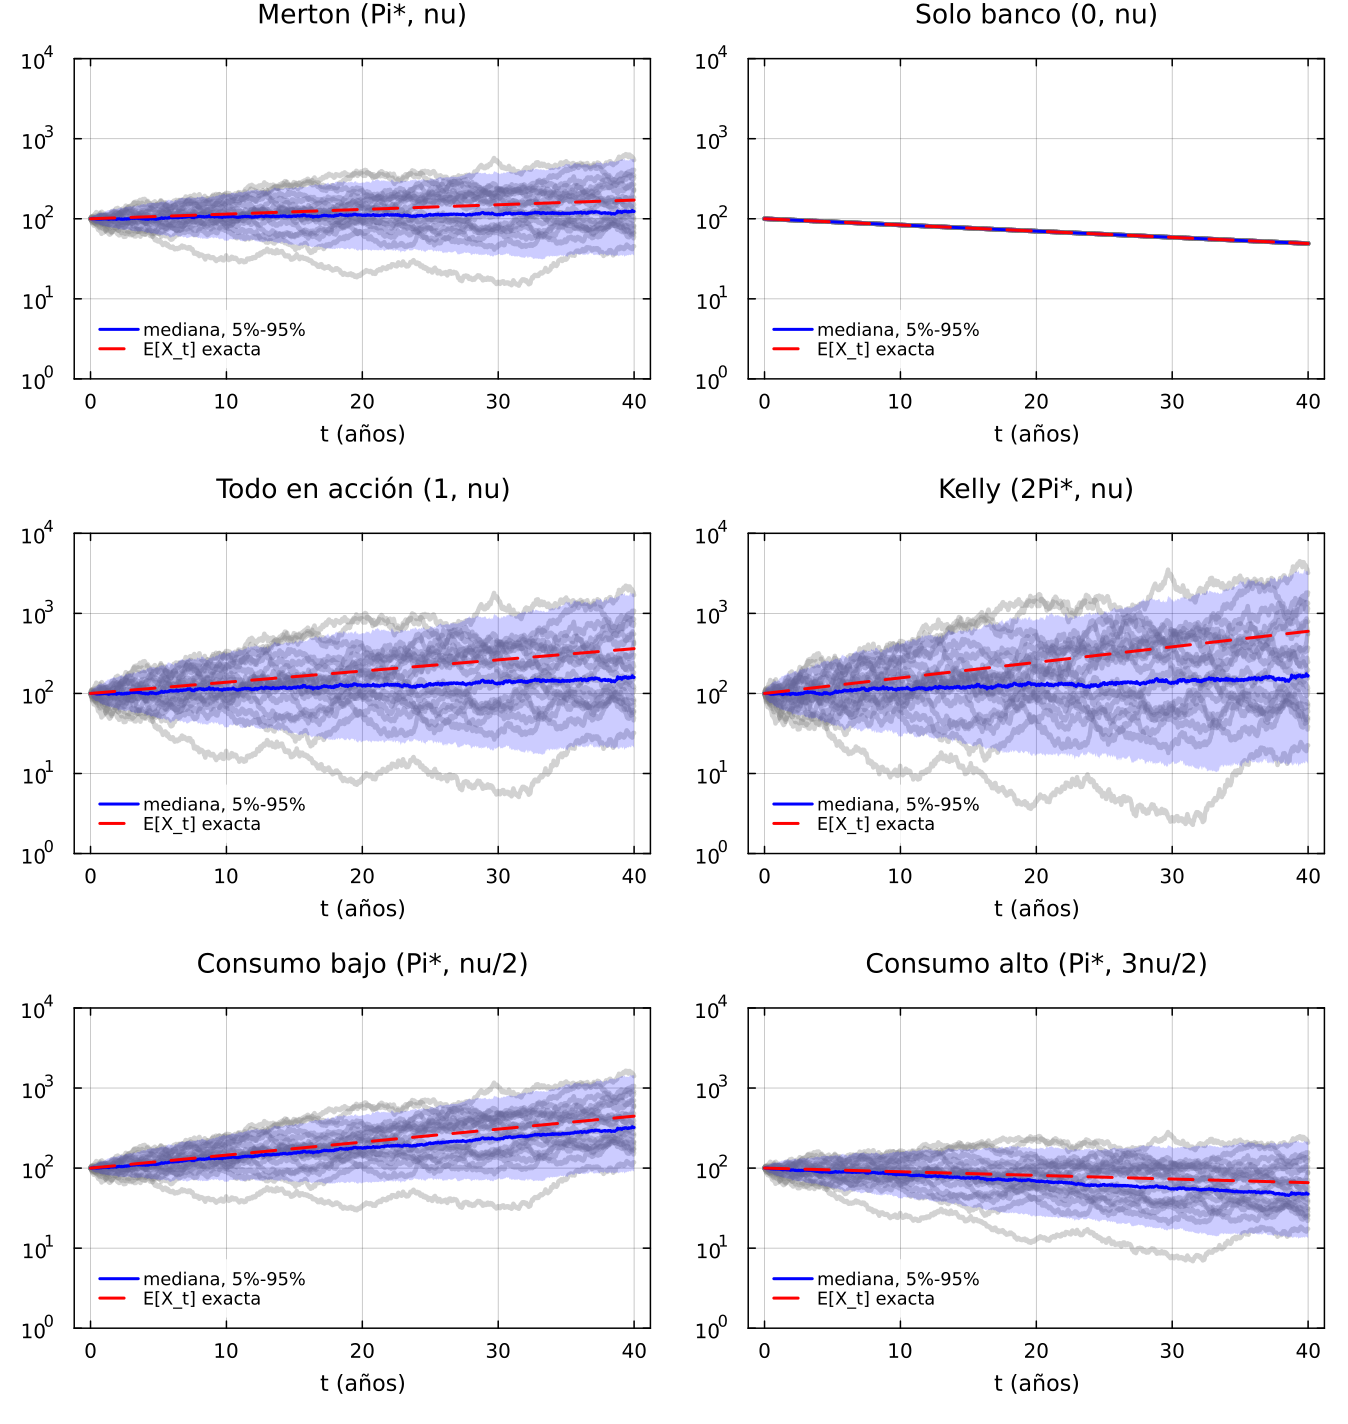

In [5]:
let T = 40.0, h = 1/52, N = 300
    Random.seed!(1)
    K = round(Int, T/h); t = h .* (0:K)
    Z = randn(K, N)                     # escenarios comunes a todos los controles
    figs = []
    for (nombre, (Pi, c)) in controles
        X = simular_exacto(Pi, c, Z, h)
        @assert minimum(X) > 0               # Prop. 3.1: el capital nunca se anula
        q = [quantile(X[k, :], [0.05, 0.5, 0.95]) for k in 1:K+1]
        med = getindex.(q, 2)
        pl = plot(t, X[:, 1:20], color=:gray, alpha=0.35, primary=false, title=nombre, titlefontsize=12,
                  yscale=:log10, ylims=(1, 1e4), tickfontsize=9, guidefontsize=10, legendfontsize=8, margin=2Plots.mm)
        plot!(pl, t, med, ribbon=(med .- getindex.(q, 1), getindex.(q, 3) .- med),
              fillalpha=0.2, color=:blue, lw=2, label="mediana, 5%-95%")
        plot!(pl, t, par.x0 .* exp.((par.r + Pi*(par.mu - par.r) - c) .* t), color=:red, ls=:dash, lw=2, label="E[X_t] exacta")
        push!(figs, pl)
    end
    plot(figs..., layout=(3, 2), size=(900, 950), legend=:bottomleft, xlabel="t (años)")
end

* **Solo banco** es determinista, $X_t=xe^{(r-\nu)t}$, y decrece a tasa $\nu-r\approx1.8\%$ anual.
* En **Merton** la media crece a tasa $r+\Pi^*(\mu-r)-\nu\approx1.3\%$ anual, y la mediana a $\approx0.6\%$.
* **Kelly** ($2\Pi^*$) tiene la mediana que más crece, pero también la mayor dispersión.
* **Consumo alto** hace caer el capital y **consumo bajo** lo acumula.

### 3.2 Referencia exacta

**Proposición 3.2.** Sea $\eta>1$. Si $\kappa(\bar\pi,\bar c)>0$, $J(x;\bar\pi,\bar c)=\frac{(\bar cx)^{1-\eta}}{(1-\eta)\kappa}-\frac{1}{(1-\eta)\gamma}$, y si $\kappa\le0$, $J=-\infty$. En $(\Pi^*,\nu)$ se tiene $\kappa=\nu$ y $J=V(x)$. El funcional truncado en $[0,T]$ es $J_T=\frac{1}{1-\eta}\Big((\bar cx)^{1-\eta}\frac{1-e^{-\kappa T}}{\kappa}-\frac{1-e^{-\gamma T}}{\gamma}\Big)$.

*Demostración.* Por la Prop. 3.1, $\log X_t$ es gaussiano y $e^{-\gamma t}\mathbb E[X_t^{1-\eta}]=x^{1-\eta}e^{-\kappa t}$. Como $U(\bar cX_t)=\frac{(\bar cX_t)^{1-\eta}-1}{1-\eta}$ y el término $(\bar cX_t)^{1-\eta}$ es positivo, por Tonelli $\mathbb E\int_0^\infty e^{-\gamma t}(\bar cX_t)^{1-\eta}dt=(\bar cx)^{1-\eta}/\kappa$ si $\kappa>0$ y $+\infty$ si no. Con $(\bar\pi,\bar c)=(\Pi^*,\nu)$, $\bar\pi(\mu-r)-\frac\eta2\sigma^2\bar\pi^2=\frac{\theta^2}{2\eta}$ y $\kappa=\eta\nu+(1-\eta)\nu=\nu$. $\blacksquare$

**Corolario 3.3.** Entre las estrategias proporcionales, $J$ es máximo en $(\Pi^*,\nu)$. Con $\eta=2$: "solo banco" y "Kelly" tienen el mismo $J$ (simetría de $\kappa$ en $\bar\pi$ alrededor de $\Pi^*$), consumir $\nu/2$ o $3\nu/2$ da el mismo $J$, y consumir $2\nu$ o más da $J=-\infty$ aunque el capital nunca se anule.

(Aquí "solo banco" consume a la tasa $\nu$ de Merton, por eso su $x_{CE}$ es 67.3; con su consumo óptimo $\nu(0)$ sube a 70.0, que es la referencia del póster.)

In [6]:
@printf("kappa(Pi*, nu) - nu = %.1e   |   J(Pi*, nu) - V(x0) = %.1e\n\n", kappa(Pim, nu) - nu, Jexacto(Pim, nu) - V(par.x0))
@printf("%-27s %8s %10s %9s\n", "control", "kappa", "J exacto", "xCE")
for (nombre, (Pi, c)) in controles
    @printf("%-27s %8.4f %10.4f %9.3f\n", nombre, kappa(Pi, c), Jexacto(Pi, c), xCE(Jexacto(Pi, c)))
end
@printf("%-27s %8.4f %10.4f %9.3f\n", "Consumo 2nu (Pi*, 2nu)", kappa(Pim, 2nu), Jexacto(Pim, 2nu), xCE(Jexacto(Pim, 2nu)))
@printf("%-27s %8.4f %10.4f %9.3f\n", "Solo banco, consumo nu(0)", kappa(0.0, nu0), Jexacto(0.0, nu0), xCE(Jexacto(0.0, nu0)))

kappa(Pi*, nu) - nu = 0.0e+00   |   J(Pi*, nu) - V(x0) = 0.0e+00

control                        kappa   J exacto       xCE
Merton (Pi*, nu)              0.0478    15.6256   100.000
Solo banco (0, nu)            0.0322    13.5021    67.320
Todo en acción (1, nu)        0.0422    15.0424    88.235
Kelly (2Pi*, nu)              0.0322    13.5021    67.320
Consumo bajo (Pi*, nu/2)      0.0717    14.1675    75.000
Consumo alto (Pi*, 3nu/2)     0.0239    14.1675    75.000
Consumo 2nu (Pi*, 2nu)        0.0000       -Inf     0.000
Solo banco, consumo nu(0)     0.0400    13.7500    69.990


### 3.3 Estimador de Monte-Carlo

En la grilla $t_k=kh$, $T=Kh$, para cada trayectoria calculamos
$$
Y=\sum_{k=0}^Kw_k\,e^{-\gamma t_k}U(\bar cX_{t_k})+e^{-\gamma T}\,\Psi_{\bar\pi,\bar c}(X_T),\qquad w_0=w_K=\tfrac h2,\ w_k=h,
$$
es decir, $\int_0^Te^{-\gamma t}U(C_t)\,dt$ por trapecio más un término final que reemplaza la cola $[T,\infty)$: $\Psi_{\bar\pi,\bar c}(y)=J(y;\bar\pi,\bar c)$ es el valor exacto de **seguir con la misma estrategia** desde $X_T=y$ (Prop. 3.2). En el control de Merton, $\Psi_{\Pi^*,\nu}=V$. Luego
$$
\hat J_N=\frac1N\sum_{i=1}^NY^{(i)},\qquad \text{IC}_{95\%}:\ \hat J_N\pm1.96\,\frac{s_N}{\sqrt N}.
$$

**Proposición 3.4.** Si $\kappa(\bar\pi,\bar c)>0$:
1. $\mathbb E[Y]-J=J^h_T-J_T$, donde $J^h_T$ es el trapecio de la función determinista $f(t)=\frac{1}{1-\eta}\big((\bar cx)^{1-\eta}e^{-\kappa t}-e^{-\gamma t}\big)$. El único sesgo es el de la cuadratura, $O(h^2)$, y **no hay sesgo de truncamiento** para ningún $T$.
2. $Y$ tiene segundo momento finito, así que por la ley de grandes números $\hat J_N\to\mathbb E[Y]$ c.s., y por el TCL el intervalo tiene cobertura asintótica del 95%.
3. **Variables antitéticas:** si $Y^-$ se calcula con $-Z$, los pares $\frac12(Y+Y^-)$ son i.i.d. con la misma media, y el intervalo se calcula sobre los pares.

*Demostración.* (1) Por la Prop. 3.1, $e^{-\gamma t}\mathbb E[U(\bar cX_t)]=f(t)$. Por la Prop. 3.2 aplicada en $X_T$, $e^{-\gamma T}\mathbb E[\Psi(X_T)]=\frac{1}{1-\eta}\big((\bar cx)^{1-\eta}\frac{e^{-\kappa T}}{\kappa}-\frac{e^{-\gamma T}}{\gamma}\big)=J-J_T$. (2) $Y$ es combinación finita de potencias de lognormales. (3) $Z$ y $-Z$ tienen la misma ley. $\blacksquare$

In [7]:
# Y^(i) = trapecio en [0, T] + e^{-gamma T} J(X_T; Pi, c)   (Prop. 3.4)
function utilidad_mc(Pi, c, Z, h; P=par, x=P.x0)
    K = size(Z, 1)
    X = simular_exacto(Pi, c, Z, h; P=P, x=x)
    w = fill(h, K + 1); w[1] = h/2; w[end] = h/2      # pesos del trapecio
    desc = exp.(-P.gamma .* h .* (0:K))                 # factores de descuento e^{-gamma t_k}
    Y = vec(sum(w .* desc .* U.(c .* X; P=P), dims=1))
    return Y .+ exp(-P.gamma*K*h) .* [Jexacto(Pi, c; P=P, x=XT) for XT in X[end, :]]
end

# E[Y] exacto (Prop. 3.4): J + (trapecio - J_T); la diferencia con J es solo el error de cuadratura
function EJmc(Pi, c, T, h; P=par, x=P.x0)
    k = kappa(Pi, c; P=P); K = round(Int, T/h)
    f(s) = ((c*x)^(1 - P.eta)*exp(-k*s) - exp(-P.gamma*s))/(1 - P.eta)
    trapecio = h*(0.5*(f(0.0) + f(T)) + sum(f(n*h) for n in 1:K-1))
    return Jexacto(Pi, c; P=P, x=x) + trapecio - Jtrunc(Pi, c, T; P=P, x=x)
end

EJmc (generic function with 1 method)

**Estimación para cada control.** $N=10^4$ trayectorias, $T=30$ años y paso mensual, con los mismos escenarios para todos los controles. Como los escenarios son comunes, la diferencia $Y_{\text{Merton}}-Y_{\text{otro}}$ tiene varianza $s_1^2+s_2^2-2\,\mathrm{cov}$, mucho menor que sin pareo: así se establece con significancia que Merton es mejor **sin usar los valores exactos**.

In [8]:
let T = 30.0, h = 1/12, N = 10_000
    Random.seed!(10)
    Z = randn(round(Int, T/h), N)
    res = Dict{String, Vector{Float64}}()
    @printf("%-27s %10s %8s %10s %10s %8s\n", "control", "J_N (MC)", "+-IC95", "E[Y]", "J exacto", "xCE")
    for (nombre, (Pi, c)) in controles
        Y = utilidad_mc(Pi, c, Z, h); res[nombre] = Y
        m, s = media_ic(Y)
        @printf("%-27s %10.4f %8.4f %10.4f %10.4f %8.3f\n", nombre, m, s, EJmc(Pi, c, T, h), Jexacto(Pi, c), xCE(m))
    end
    YM = res["Merton (Pi*, nu)"]
    @printf("\n%-27s %10s %12s %14s %10s\n", "control", "J_M - J", "+-IC pareado", "+-IC sin pareo", "exacto")
    for (nombre, (Pi, c)) in controles[2:end]
        d = YM .- res[nombre]
        @printf("%-27s %10.4f %12.4f %14.4f %10.4f\n", nombre, mean(d), 1.96*std(d)/sqrt(N),
                1.96*sqrt(var(YM) + var(res[nombre]))/sqrt(N), Jexacto(Pim, nu) - Jexacto(Pi, c))
    end
end

control                       J_N (MC)   +-IC95       E[Y]   J exacto      xCE
Merton (Pi*, nu)               15.6110   0.0369    15.6256    15.6256   99.666
Solo banco (0, nu)             13.5021   0.0000    13.5021    13.5021   67.320
Todo en acción (1, nu)         15.0016   0.0842    15.0424    15.0424   87.515
Kelly (2Pi*, nu)               13.3907   0.1942    13.5021    13.5021   66.186
Consumo bajo (Pi*, nu/2)       14.1539   0.0402    14.1675    14.1675   74.826
Consumo alto (Pi*, 3nu/2)      14.1385   0.0643    14.1675    14.1675   74.629

control                        J_M - J +-IC pareado +-IC sin pareo     exacto
Solo banco (0, nu)              2.1088       0.0369         0.0369     2.1235
Todo en acción (1, nu)          0.6094       0.0503         0.0919     0.5833
Kelly (2Pi*, nu)                2.2202       0.1643         0.1977     2.1235
Consumo bajo (Pi*, nu/2)        1.4571       0.0072         0.0546     1.4581
Consumo alto (Pi*, 3nu/2)       1.4725       0.0290     

Todos los intervalos contienen el valor exacto, y $\mathbb E[Y]$ difiere de $J$ solo en el error de cuadratura. Merton tiene $x_{CE}=100$ y todos los demás controles son peores, como predice el Corolario 3.3; las diferencias pareadas son significativas.

### 3.4 Validación: tasa $N^{-1/2}$, cobertura y variables antitéticas

Repetimos el experimento $R=200$ veces para varios $N$ con el control de Merton y medimos el error cuadrático medio de $\hat J_N$ respecto de $\mathbb E[Y]$ (conocido por la Prop. 3.4), la fracción de intervalos que contienen $\mathbb E[Y]$ y el error con variables antitéticas usando el **mismo número de trayectorias** ($N/2$ pares).

N =   100: RMSE = 0.19321 | cobertura IC95 = 0.940 | RMSE antitéticas = 0.08623
N =   400: RMSE = 0.09404 | cobertura IC95 = 0.955 | RMSE antitéticas = 0.04740
N =  1600: RMSE = 0.04709 | cobertura IC95 = 0.960 | RMSE antitéticas = 0.02179
N =  6400: RMSE = 0.02115 | cobertura IC95 = 0.975 | RMSE antitéticas = 0.01133
pendiente log-log del RMSE: -0.529 (teórica -1/2);  reducción de varianza antitética ~ 4.3 veces (T = 30, paso trimestral)


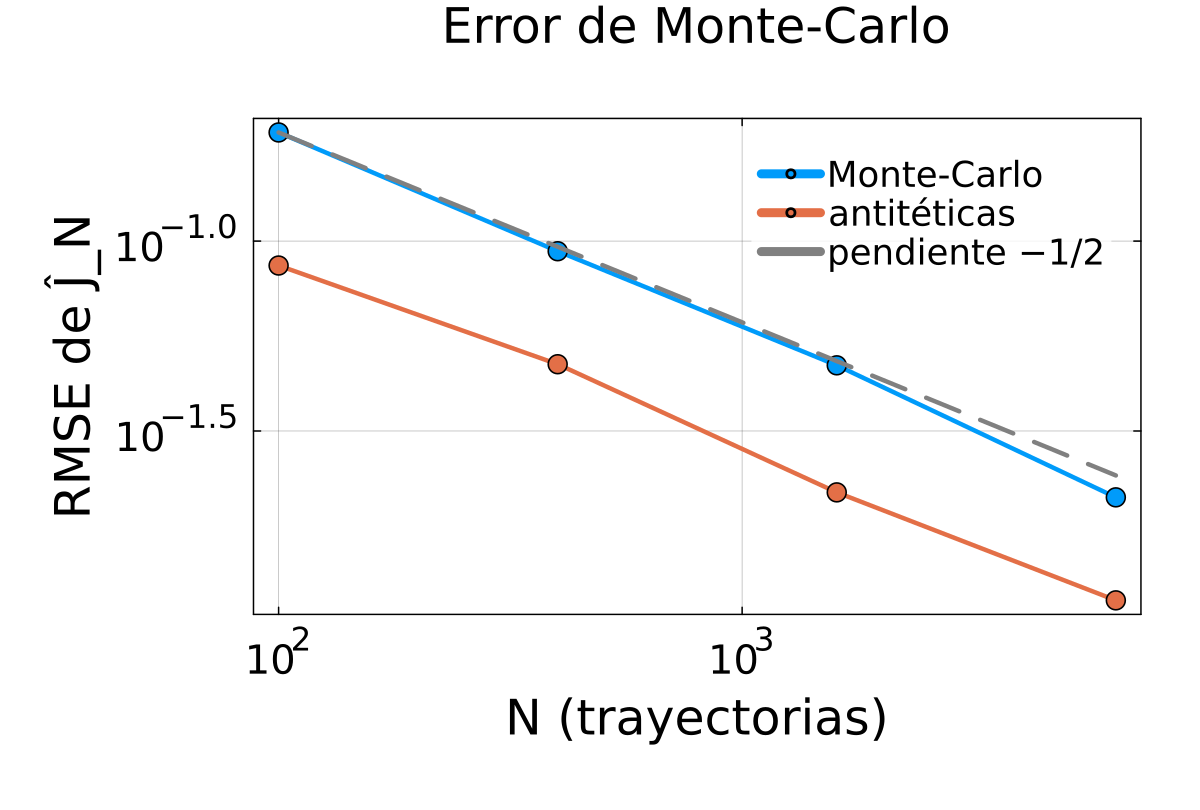

In [9]:
pendiente(x, y) = (lx = log.(x); ly = log.(y); sum((lx .- mean(lx)) .* (ly .- mean(ly)))/sum((lx .- mean(lx)).^2))

let T = 30.0, h = 1/4, R = 200
    Random.seed!(11)
    K = round(Int, T/h); EY = EJmc(Pim, nu, T, h)
    Ns = [100, 400, 1600, 6400]
    rmse, cobertura, rmse_at = Float64[], Float64[], Float64[]
    for Ni in Ns
        est = zeros(R); est_at = zeros(R); dentro = 0
        for rep in 1:R
            Zi = randn(K, Ni)
            m, s = media_ic(utilidad_mc(Pim, nu, Zi, h))
            est[rep] = m; dentro += abs(m - EY) <= s
            Zp = Zi[:, 1:div(Ni, 2)]                                               # N/2 pares antitéticos
            est_at[rep] = mean((utilidad_mc(Pim, nu, Zp, h) .+ utilidad_mc(Pim, nu, -Zp, h)) ./ 2)
        end
        push!(rmse, sqrt(mean((est .- EY).^2))); push!(cobertura, dentro/R); push!(rmse_at, sqrt(mean((est_at .- EY).^2)))
        @printf("N = %5d: RMSE = %.5f | cobertura IC95 = %.3f | RMSE antitéticas = %.5f\n", Ni, rmse[end], cobertura[end], rmse_at[end])
    end
    @printf("pendiente log-log del RMSE: %.3f (teórica -1/2);  reducción de varianza antitética ~ %.1f veces (T = 30, paso trimestral)\n",
            pendiente(Ns, rmse), mean((rmse ./ rmse_at).^2))
    pl = plot(Ns, [rmse rmse_at], xscale=:log10, yscale=:log10, marker=:circle, label=["Monte-Carlo" "antitéticas"],
              xlabel="N (trayectorias)", ylabel="RMSE de Ĵ_N", title="Error de Monte-Carlo")
    plot!(pl, Ns, rmse[1] .* sqrt.(Ns[1] ./ Ns), ls=:dash, color=:gray, label="pendiente −1/2")
end

### 3.5 Figuras del póster

Mediana y banda 10%–90% del capital para Merton, "solo banco" y Kelly, todos con $C=\nu X$ y en los mismos escenarios, y convergencia de $\hat J_N$ (pares antitéticos) al valor exacto $V(x_0)$, con su IC al 95%.

La reducción de varianza de las antitéticas depende de la configuración: aquí ($T=10$, paso semanal) es de unas 8 veces, y en la validación anterior ($T=30$, paso trimestral) de unas 4 veces. Por eso en el póster y el reporte conviene decir "entre 4 y 8 veces" o indicar la configuración.

J_N = 15.6263 +- 0.0069   vs   V(x0) = 15.6256;   reducción de varianza por antitéticas: 8.4 veces


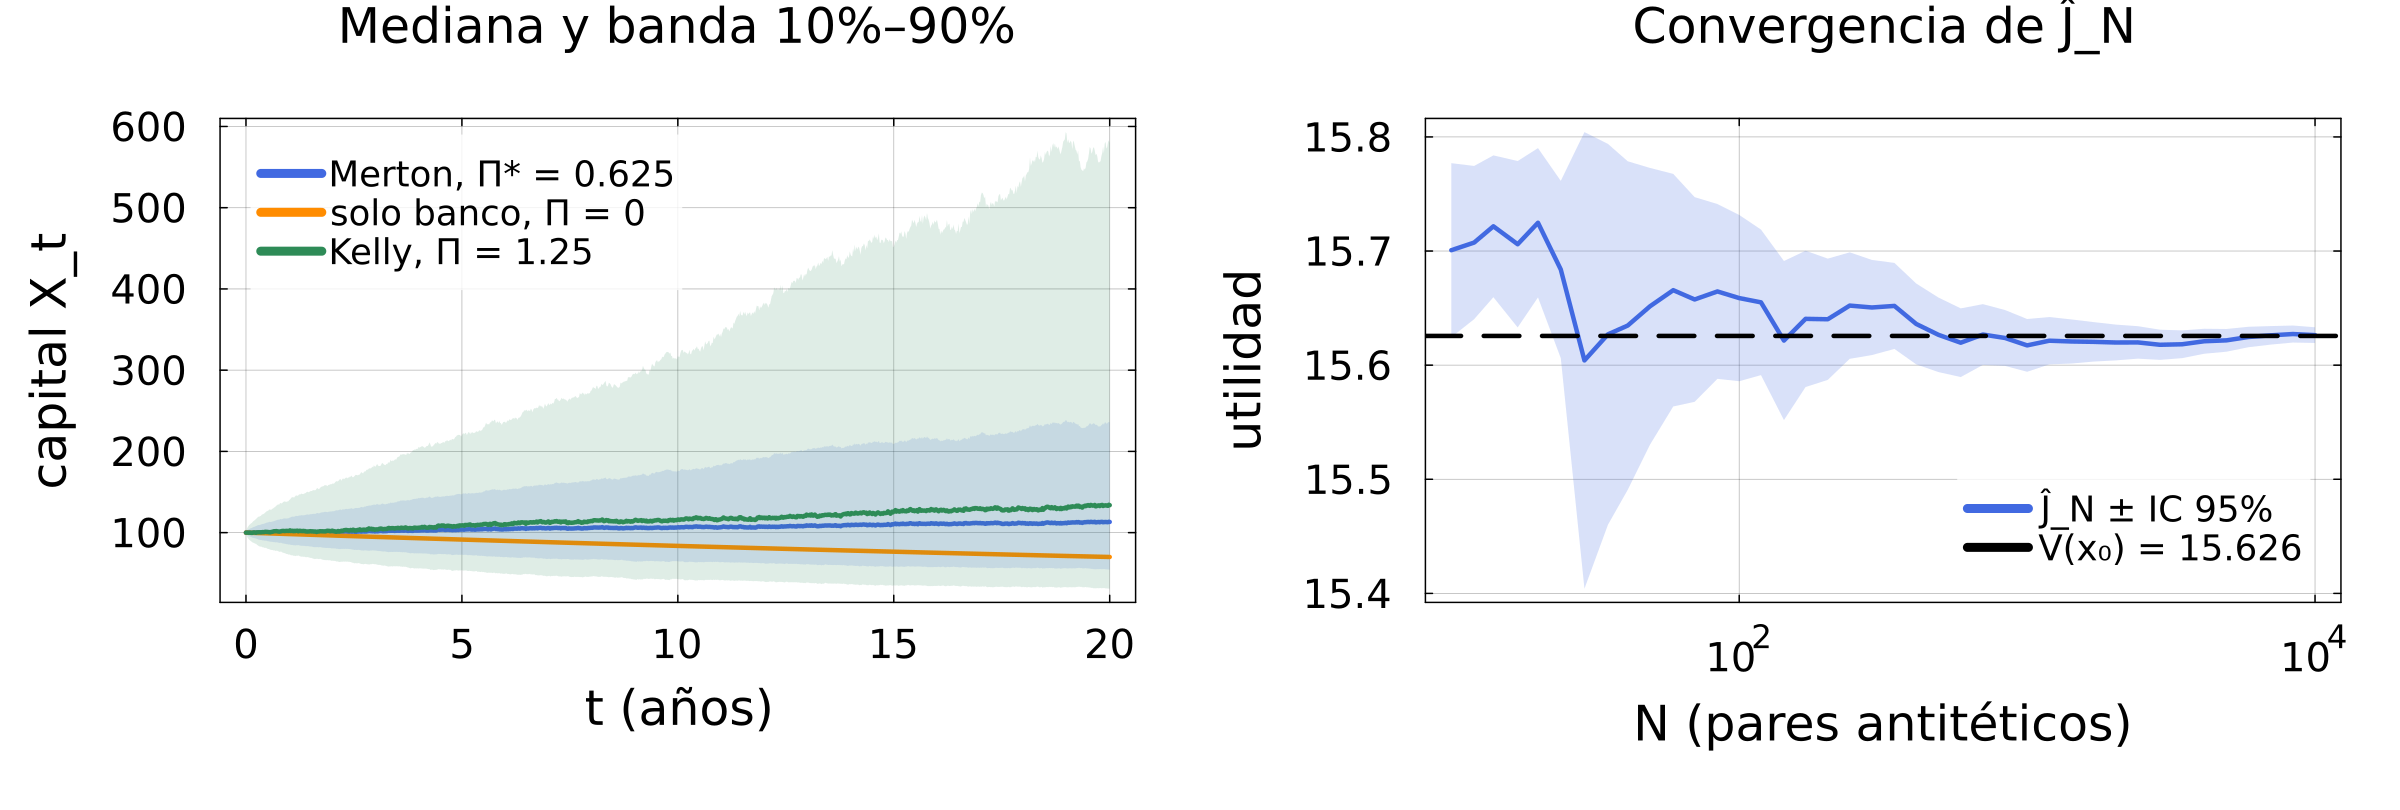

In [10]:
let
    Random.seed!(50)
    # (a) trayectorias con el esquema exacto, mismos escenarios para los tres controles
    T, h, N = 20.0, 1/52, 2000
    K = round(Int, T/h); t = h .* (0:K)
    Z = randn(K, N)
    pa = plot(xlabel="t (años)", ylabel="capital X_t", title="Mediana y banda 10%–90%", legend=:topleft)
    for (nombre, Pi, col) in [("Merton, Π* = 0.625", Pim, :royalblue), ("solo banco, Π = 0", 0.0, :darkorange),
                              ("Kelly, Π = 1.25", 2Pim, :seagreen)]
        X = simular_exacto(Pi, nu, Z, h)
        q = [quantile(X[k, :], [0.1, 0.5, 0.9]) for k in 1:K+1]
        med = getindex.(q, 2)
        plot!(pa, t, med, ribbon=(med .- getindex.(q, 1), getindex.(q, 3) .- med), fillalpha=0.15, color=col, label=nombre)
    end
    guardar(pa, "mc_trayectorias")

    # (b) convergencia de J_N con pares antitéticos (Prop. 3.4)
    T, h, N = 10.0, 1/52, 10_000
    Z = randn(round(Int, T/h), N)
    Y1 = utilidad_mc(Pim, nu, Z, h); Y2 = utilidad_mc(Pim, nu, -Z, h)
    Yp = (Y1 .+ Y2) ./ 2
    Ns = unique(round.(Int, exp10.(range(1, log10(N), length=40))))
    m = [mean(Yp[1:n]) for n in Ns]; s = [1.96*std(Yp[1:n])/sqrt(n) for n in Ns]
    pb = plot(Ns, m, ribbon=s, fillalpha=0.2, color=:royalblue, xscale=:log10, label="Ĵ_N ± IC 95%",
              xlabel="N (pares antitéticos)", ylabel="utilidad", title="Convergencia de Ĵ_N", legend=:bottomright)
    hline!(pb, [V(par.x0)], ls=:dash, color=:black, label=@sprintf("V(x₀) = %.3f", V(par.x0)))
    guardar(pb, "mc_convergencia")
    @printf("J_N = %.4f +- %.4f   vs   V(x0) = %.4f;   reducción de varianza por antitéticas: %.1f veces\n",
            m[end], s[end], V(par.x0), (var(Y1)/2)/var(Yp))
    plot(pa, pb, layout=(1, 2), size=(1600, 540))
end

**Conclusiones de la Sección 3.**
1. Con estrategias proporcionales el capital es lognormal: la simulación log-Euler es **exacta** y nunca hay quiebra.
2. Con el valor de continuación exacto, $\hat J_N$ solo tiene el sesgo de la cuadratura; el error estadístico decae como $N^{-1/2}$, los intervalos tienen la cobertura esperada y las variables antitéticas reducen la varianza entre 4 y 8 veces según el horizonte.
3. Monte-Carlo confirma la teoría: $\hat J_N$ converge a $V(x)$ y el control de Merton es mejor que todos los demás controles simulados, con significancia.

## 4. Filtro de Kalman para estimar los parámetros (objetivo 3)

El control de Merton depende de $\mu$ y $\sigma$, que en la práctica no se conocen: se observan los precios $S_t$ de la acción. En esta sección:

1. escribimos el modelo de observación de los precios (4.1);
2. estimamos $\sigma$ con la varianza realizada (4.2);
3. estimamos $\mu$ con un filtro de Kalman, constante o variable en el tiempo (4.3 y 4.4);
4. medimos cuánto se pierde al usar en el control de Merton los parámetros estimados (4.5).

### 4.1 Modelo de observación

El precio de la acción es $S_t=S_0\exp\big((\mu-\frac{\sigma^2}2)t+\sigma B_t\big)$. Si lo observamos cada $h$ años (diario: $h=1/252$), los **rendimientos logarítmicos**
$$
R_k=\log S_{t_k}-\log S_{t_{k-1}}=\Big(\mu-\frac{\sigma^2}2\Big)h+\sigma\sqrt h\,\varepsilon_k,\qquad \varepsilon_k\ \text{i.i.d.}\ \mathcal N(0,1),
$$
son exactamente gaussianos e independientes (como en la Prop. 3.1). Estimar $\mu$ y $\sigma$ es estimar la media y la varianza de normales i.i.d., pero con precisiones muy distintas. Para la Sección 4.4 permitimos una deriva variable $\mu(t)$, congelada en cada paso.

In [11]:
const h_diario = 1/252   # paso de observación diario

# rendimientos logarítmicos en [0, T] con paso h; mu puede ser un número o una función del tiempo
function rendimientos(T, h; mu=par.mu, sigma=par.sigma)
    n = round(Int, T/h); t = h .* (0:n-1)
    m = mu isa Function ? mu.(t) : fill(mu, n)
    return (m .- sigma^2/2) .* h .+ sigma*sqrt(h) .* randn(n)
end

sigma_rv(R, h) = sqrt(var(R)/h)   # varianza realizada (Prop. 4.1)

sigma_rv (generic function with 1 method)

### 4.2 Estimación de $\sigma$: varianza realizada

**Proposición 4.1.** Con $n=T/h$ rendimientos, $\hat\sigma^2=\frac{1}{(n-1)h}\sum_{k=1}^n(R_k-\bar R)^2$ es insesgado y $\mathrm{sd}(\hat\sigma)\approx\frac{\sigma}{\sqrt{2n}}$. El error depende del **número de observaciones** $n$, no del tiempo total $T$: con datos diarios, un año basta para conocer $\sigma$ con un error de $0.009$ (4.5%).

*Demostración.* Los $R_k$ son normales i.i.d. con varianza $\sigma^2h$, así que $(n-1)\hat\sigma^2/\sigma^2\sim\chi^2_{n-1}$, de media $n-1$ y varianza $2(n-1)$. Luego $\mathbb E[\hat\sigma^2]=\sigma^2$, $\mathrm{Var}(\hat\sigma^2)=\frac{2\sigma^4}{n-1}$, y por el método delta $\mathrm{sd}(\hat\sigma)\approx\frac{1}{2\sigma}\sqrt{\frac{2\sigma^4}{n-1}}=\frac{\sigma}{\sqrt{2(n-1)}}$. $\blacksquare$

En tiempo continuo, la variación cuadrática $\langle\log S\rangle_T=\sigma^2T$ [KS, cap. 3] determina $\sigma$ exactamente con cualquier trayectoria. Por eso $\sigma$ se considera "conocida", y el parámetro difícil es $\mu$.

### 4.3 Filtro de Kalman para $\mu$

**Modelo de espacio de estados.** El estado es la deriva $\mu_k$ y la observación es el rendimiento corregido $z_k:=R_k+\frac{\hat\sigma^2}{2}h$:
$$
\mu_k=\mu_{k-1}+w_k,\quad w_k\sim\mathcal N(0,qh);\qquad z_k=h\,\mu_k+v_k,\quad v_k\sim\mathcal N(0,\hat\sigma^2h).
$$
Con $q=0$ la deriva es constante; con $q>0$ puede cambiar lentamente (4.4). El modelo es lineal y gaussiano, así que el filtro entrega la ley exacta de $\mu_k$ dados $z_1,\dots,z_k$, una normal $\mathcal N(m_k,P_k)$ con
$$
P_k^-=P_{k-1}+qh,\qquad G_k=\frac{hP_k^-}{h^2P_k^-+\hat\sigma^2h},\qquad m_k=m_{k-1}+G_k\,(z_k-h\,m_{k-1}),\qquad P_k=(1-hG_k)P_k^-.
$$
Partimos de una a priori muy difusa, $m_0=r$ y $P_0=1$. Para simplificar usamos en el filtro el $\hat\sigma$ de todo el período: por la Prop. 4.1 su error es de 4.5% con un año de datos y menor que 2% desde los cinco años, así que no cambia los resultados.

**Proposición 4.2 (deriva constante).** Si $q=0$, $\frac{1}{P_k}=\frac{1}{P_0}+\frac{t_k}{\hat\sigma^2}$ y $m_k=P_k\Big(\frac{m_0}{P_0}+\frac{1}{\hat\sigma^2}\sum_{j\le k}z_j\Big)$. Con a priori difusa ($P_0\to\infty$),
$$
m_k=\frac{\log S_{t_k}-\log S_0}{t_k}+\frac{\hat\sigma^2}{2},\qquad P_k=\frac{\hat\sigma^2}{t_k},
$$
es decir, el filtro es el estimador de máxima verosimilitud y $\mathrm{sd}(\hat\mu)=\sigma/\sqrt T$: depende **solo del tiempo total observado**, no de la frecuencia.

*Demostración.* Con $q=0$, $P_k=\frac{\hat\sigma^2h\,P_{k-1}}{h^2P_{k-1}+\hat\sigma^2h}$, luego $\frac1{P_k}=\frac1{P_{k-1}}+\frac{h}{\hat\sigma^2}$ y sumando $\frac1{P_k}=\frac1{P_0}+\frac{kh}{\hat\sigma^2}$. Del mismo modo $\frac{m_k}{P_k}=\frac{m_{k-1}}{P_{k-1}}+\frac{z_k}{\hat\sigma^2}$. Como $\sum_{j\le k}z_j=\log S_{t_k}-\log S_0+\frac{\hat\sigma^2}2t_k$, se obtiene la fórmula. $\blacksquare$

In [12]:
# filtro de Kalman para la deriva: estado mu_k, observación z_k = R_k + s2 h/2 = h mu_k + ruido
# s2: varianza estimada; q: varianza por año de los cambios de mu (q = 0: mu constante)
function kalman_mu(R, h, s2; q=0.0, m0=par.r, P0=1.0)
    n = length(R); m = zeros(n); Pk = zeros(n)
    mk, Pv = m0, P0
    for k in 1:n
        Pv += q*h                              # predicción
        G = h*Pv/(h^2*Pv + s2*h)               # ganancia de Kalman
        mk += G*(R[k] + s2*h/2 - h*mk)         # actualización con la observación z_k
        Pv *= 1 - h*G
        m[k], Pk[k] = mk, Pv
    end
    return m, Pk
end

kalman_mu (generic function with 1 method)

**Una trayectoria.** Simulamos 20 años de precios diarios y miramos cómo aprende el filtro. Para $\sigma$ graficamos la varianza realizada con los datos disponibles hasta cada fecha.

con 20 años: mu estimado = 0.0193 +- 0.0869 (IC 95%),  sigma estimado = 0.1986


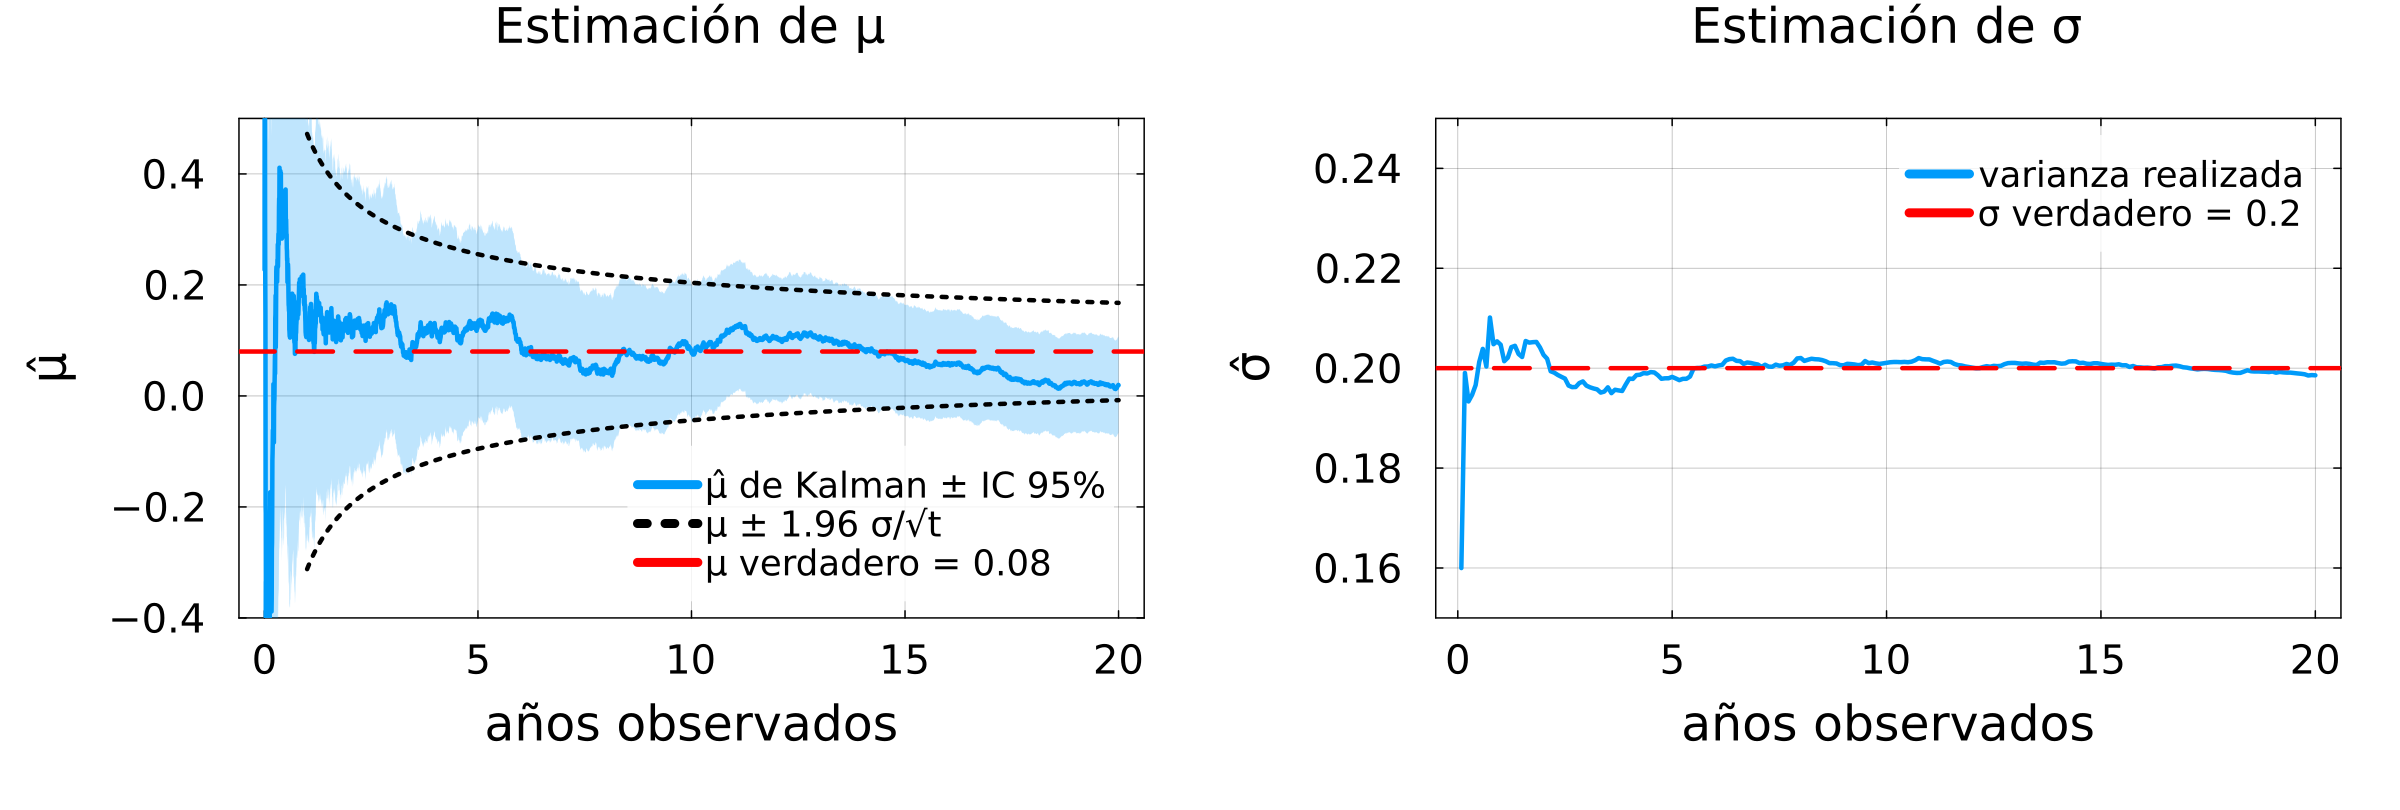

In [13]:
let T = 20.0, h = h_diario
    Random.seed!(3)
    R = rendimientos(T, h)
    m, Pk = kalman_mu(R, h, sigma_rv(R, h)^2)
    t = h .* (1:length(R))
    sig_hat = [sqrt(var(R[1:k])/h) for k in 21:21:length(R)]   # varianza realizada hasta cada mes
    pa = plot(t, m, ribbon=1.96 .* sqrt.(Pk), fillalpha=0.25, label="μ̂ de Kalman ± IC 95%", ylims=(-0.4, 0.5),
              xlabel="años observados", ylabel="μ̂", title="Estimación de μ", legend=:bottomright)
    plot!(pa, t[252:end], par.mu .+ 1.96 .* par.sigma ./ sqrt.(t[252:end]), color=:black, ls=:dot, label="μ ± 1.96 σ/√t")
    plot!(pa, t[252:end], par.mu .- 1.96 .* par.sigma ./ sqrt.(t[252:end]), color=:black, ls=:dot, label=false)
    hline!(pa, [par.mu], color=:red, ls=:dash, label="μ verdadero = 0.08")
    pb = plot(t[21:21:end], sig_hat, label="varianza realizada", xlabel="años observados", ylabel="σ̂", ylims=(0.15, 0.25),
              title="Estimación de σ", legend=:topright)
    hline!(pb, [par.sigma], color=:red, ls=:dash, label="σ verdadero = 0.2")
    @printf("con 20 años: mu estimado = %.4f +- %.4f (IC 95%%),  sigma estimado = %.4f\n", m[end], 1.96*sqrt(Pk[end]), sig_hat[end])
    guardar(pa, "kalman_estimacion_mu"); guardar(pb, "kalman_estimacion_sigma")
    plot(pa, pb, layout=(1, 2), size=(1600, 540))
end

Con 20 años de datos diarios el filtro estima $\hat\mu=0.019$ con un intervalo de $\pm0.087$: contiene al verdadero $\mu=0.08$, pero ni siquiera permite afirmar que $\mu>r=0.03$. La banda se angosta como $1/\sqrt t$, igual que la cota $\sigma/\sqrt t$ (punteada). En cambio, $\sigma$ queda estimado con un error menor que $0.01$ desde el primer año.

**Muchas trayectorias.** Repetimos el experimento 500 veces para varios horizontes $T$ y comparamos la desviación de los estimadores con las Proposiciones 4.1 y 4.2.

In [14]:
kalman_precision = let h = h_diario
    Random.seed!(4)
    Ts = [1, 2, 5, 10, 20, 40]; sd_mu = Float64[]; sd_sig = Float64[]
    println("   T   media(mu)  sd(mu)  sigma/sqrt(T)   media(sigma)  sd(sigma)  sigma/sqrt(2n)")
    for T in Ts
        est_mu = zeros(500); est_sig = zeros(500)
        for i in 1:500
            R = rendimientos(T, h); s = sigma_rv(R, h)
            est_mu[i] = kalman_mu(R, h, s^2)[1][end]; est_sig[i] = s
        end
        push!(sd_mu, std(est_mu)); push!(sd_sig, std(est_sig))
        @printf("%4d %10.4f %8.4f %12.4f %13.4f %10.5f %12.5f\n", T, mean(est_mu), sd_mu[end], par.sigma/sqrt(T),
                mean(est_sig), sd_sig[end], par.sigma/sqrt(2*T/h))
    end
    println("\nmisma ventana (T = 10 años), distinta frecuencia de observación:")
    for (nombre, hf) in [("diaria", 1/252), ("semanal", 1/52), ("mensual", 1/12)]
        est_mu = zeros(1000); est_sig = zeros(1000)
        for i in 1:1000
            R = rendimientos(10, hf); s = sigma_rv(R, hf)
            est_mu[i] = kalman_mu(R, hf, s^2)[1][end]; est_sig[i] = s
        end
        @printf("  %-8s sd(mu) = %.4f   sd(sigma) = %.5f\n", nombre, std(est_mu), std(est_sig))
    end
    @printf("\naños para que 1.96 sigma/sqrt(T) < mu - r:  T > %.1f\n", (1.96*par.sigma/(par.mu - par.r))^2)
    (Ts=Ts, sd_mu=sd_mu, sd_sig=sd_sig, h=h)
end;

   T   media(mu)  sd(mu)  sigma/sqrt(T)   media(sigma)  sd(sigma)  sigma/sqrt(2n)
   1     0.0886   0.1988       0.2000        0.1997    0.00863      0.00891
   2     0.0772   0.1467       0.1414        0.2001    0.00604      0.00630
   5     0.0773   0.0923       0.0894        0.2000    0.00425      0.00398
  10     0.0787   0.0625       0.0632        0.2000    0.00280      0.00282
  20     0.0817   0.0444       0.0447        0.2000    0.00188      0.00199
  40     0.0795   0.0321       0.0316        0.2000    0.00140      0.00141

misma ventana (T = 10 años), distinta frecuencia de observación:
  diaria   sd(mu) = 0.0619   sd(sigma) = 0.00276
  semanal  sd(mu) = 0.0612   sd(sigma) = 0.00597
  mensual  sd(mu) = 0.0602   sd(sigma) = 0.01274

años para que 1.96 sigma/sqrt(T) < mu - r:  T > 61.5


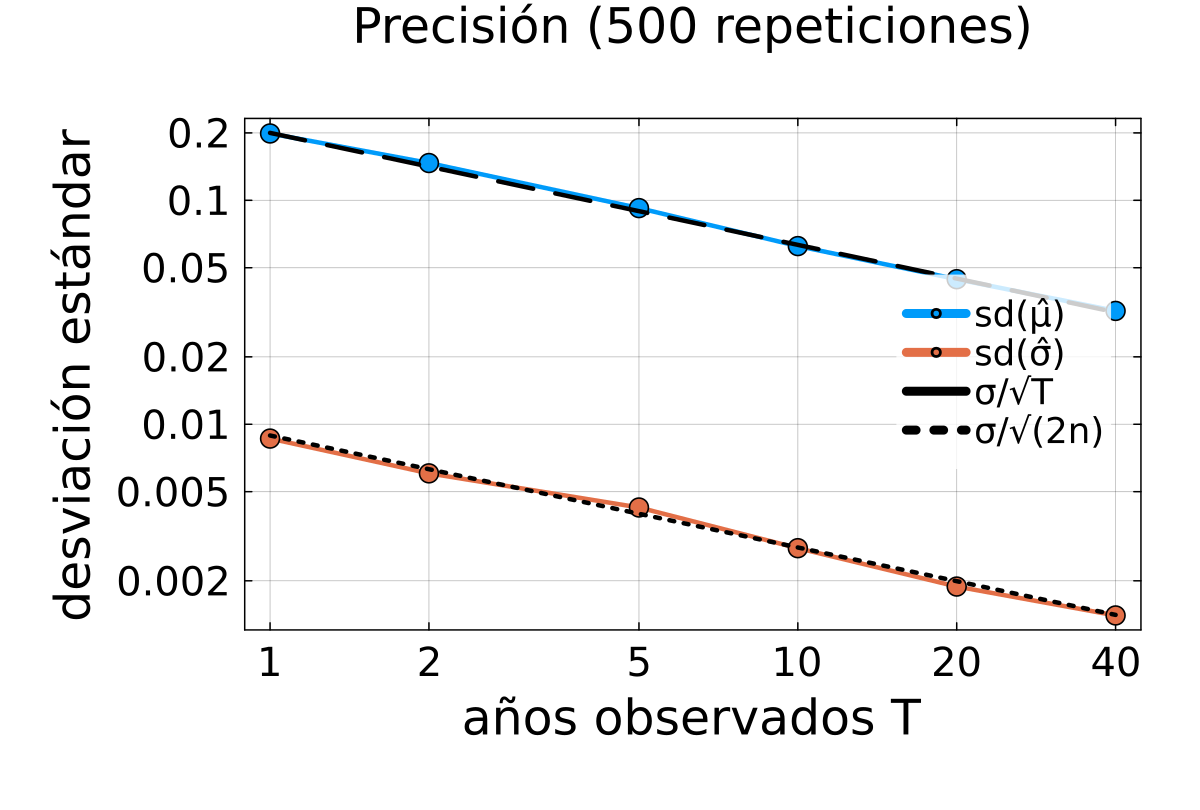

In [15]:
let (; Ts, sd_mu, sd_sig, h) = kalman_precision
    pc = plot(Ts, [sd_mu sd_sig], xscale=:log10, yscale=:log10, marker=:circle, xlabel="años observados T",
              ylabel="desviación estándar", label=["sd(μ̂)" "sd(σ̂)"], title="Precisión (500 repeticiones)", legend=:right,
              xticks=(Ts, string.(Ts)), yticks=([0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2], ["0.002", "0.005", "0.01", "0.02", "0.05", "0.1", "0.2"]))
    plot!(pc, Ts, par.sigma ./ sqrt.(Ts), ls=:dash, color=:black, label="σ/√T")
    plot!(pc, Ts, par.sigma ./ sqrt.(2 .* Ts ./ h), ls=:dot, color=:black, label="σ/√(2n)")
    guardar(pc, "kalman_precision")
end

Las fórmulas se cumplen: la desviación de $\hat\mu$ coincide con $\sigma/\sqrt T$ y la de $\hat\sigma$ con $\sigma/\sqrt{2n}$. La diferencia entre los dos parámetros es enorme:

* con 10 años, $\hat\sigma$ tiene un error de 0.003 (1.4%), pero $\hat\mu$ tiene un error de 0.063, **mayor que la prima de riesgo** $\mu-r=0.05$;
* observar con más frecuencia mejora $\hat\sigma$ unas 4.6 veces, pero **no mejora** $\hat\mu$ (Prop. 4.2): para conocer $\mu$ hay que esperar, no muestrear más seguido.

Para que el error de $\hat\mu$ sea menor que la prima de riesgo con 95% de confianza, $1.96\,\sigma/\sqrt T<0.05$, harían falta más de 61 años de datos.

### 4.4 Deriva variable: filtro con $q>0$

Si $\mu$ cambia en el tiempo, el filtro con $q=0$ promedia toda la historia. Con $q>0$ el filtro **olvida** los datos viejos: en régimen estacionario (filtro de Kalman–Bucy) la varianza es $P_\infty=\sigma\sqrt q$ y la memoria efectiva es de $\sigma/\sqrt q$ años. Lo probamos con un ciclo de 10 años, $\mu(t)=0.08+0.06\sin(2\pi t/10)$, midiendo el error cuadrático medio del seguimiento entre los años 10 y 40, para $\sigma=0.2$ y para una acción poco volátil ($\sigma=0.05$).

                  q = 0e+00     q = 1e-04     q = 1e-03     q = 1e-02  
sigma = 0.20:        0.0586        0.0591        0.0686        0.1031     (memoria sigma/sqrt(q) = inf, 20.0, 6.3, 2.0 años)
sigma = 0.05:        0.0443        0.0436        0.0415        0.0521     (memoria sigma/sqrt(q) = inf, 5.0, 1.6, 0.5 años)


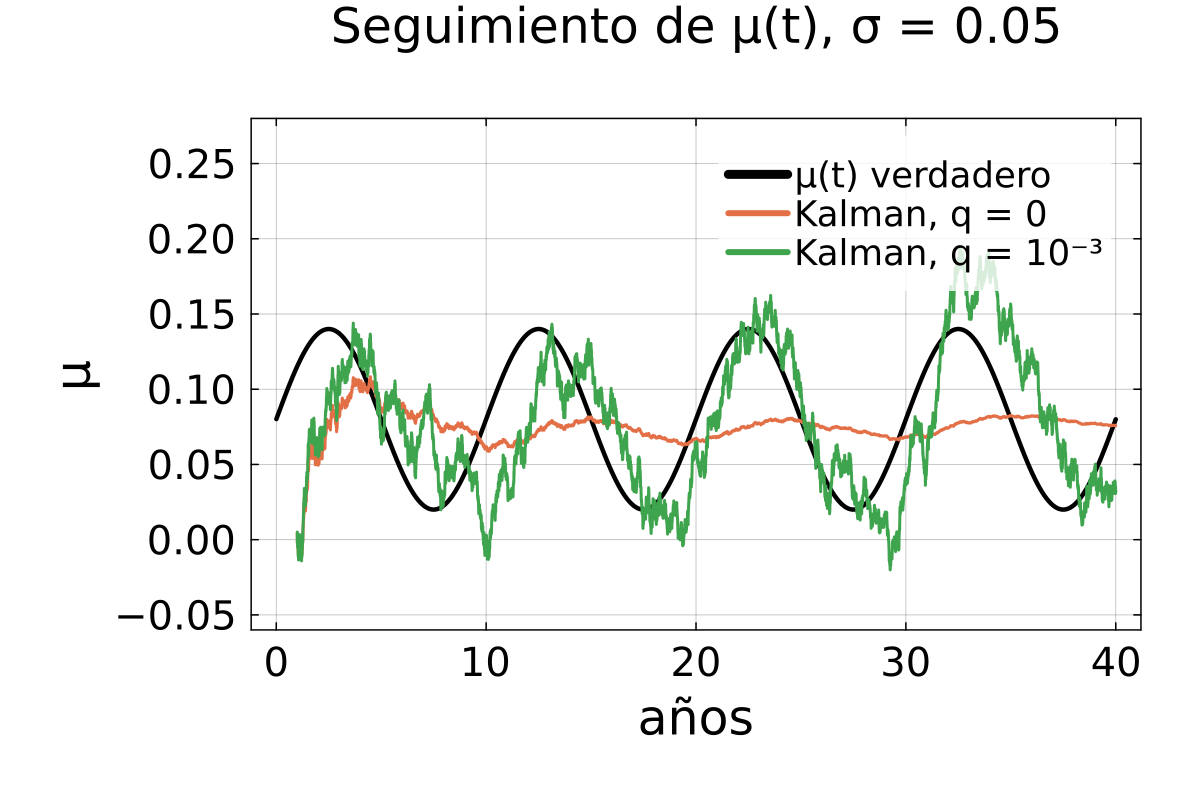

In [16]:
mu_ciclo(t) = 0.08 + 0.06*sin(2pi*t/10)

let h = h_diario, qs = [0.0, 1e-4, 1e-3, 1e-2]
    Random.seed!(5)
    println("               ", join([@sprintf("   q = %-7.0e", q) for q in qs]))
    for sig in [0.20, 0.05]
        err = zeros(length(qs))
        for rep in 1:50
            R = rendimientos(40, h; mu=mu_ciclo, sigma=sig); s2 = var(R)/h
            tt = h .* (1:length(R)); I = tt .>= 10
            for (j, q) in enumerate(qs)
                mq, _ = kalman_mu(R, h, s2; q=q)
                err[j] += sqrt(mean((mq[I] .- mu_ciclo.(tt[I])).^2))/50
            end
        end
        @printf("sigma = %.2f:  %s   (memoria sigma/sqrt(q) = %s años)\n", sig, join([@sprintf("  %10.4f  ", e) for e in err]),
                join([q > 0 ? @sprintf("%.1f", sig/sqrt(q)) : "inf" for q in qs], ", "))
    end
    # una trayectoria con sigma = 0.05 para ver el seguimiento
    Random.seed!(6)
    R = rendimientos(40, h; mu=mu_ciclo, sigma=0.05); tt = h .* (1:length(R))
    pl = plot(tt, mu_ciclo.(tt), color=:black, label="μ(t) verdadero", xlabel="años", ylabel="μ", ylims=(-0.06, 0.28),
              title="Seguimiento de μ(t), σ = 0.05", legend=:topright)
    I1 = tt .>= 1                                           # desde el año 1, sin el transiente inicial
    for (q, nombre) in [(0.0, "Kalman, q = 0"), (1e-3, "Kalman, q = 10⁻³")]
        plot!(pl, tt[I1], kalman_mu(R, h, var(R)/h; q=q)[1][I1], lw=2, label=nombre)
    end
    guardar(pl, "kalman_seguimiento")
end

Con $\sigma=0.2$, ningún $q>0$ mejora al filtro de deriva constante: con memoria corta domina el ruido, y con memoria larga el filtro se comporta como el de $q=0$. Incluso con $\sigma=0.05$ la mejora es pequeña. La información sobre $\mu$ llega a razón de $1/\sigma^2$ por año, y un ciclo de 10 años no da tiempo para aprenderlo.

### 4.5 Efecto en el control: Merton con parámetros estimados

Un inversionista que observó $T_{\text{obs}}$ años de precios usa en la fórmula de Merton los parámetros estimados, $\hat\Pi=\frac{\hat\mu-r}{\eta\hat\sigma^2}$ y $\hat\nu=\frac1\eta\big[\gamma-(1-\eta)\big(r+\frac{\hat\theta^2}{2\eta}\big)\big]$. Es una estrategia proporcional, así que su valor **verdadero** se calcula exactamente con la Prop. 3.2 (con los $\mu$ y $\sigma$ verdaderos). Si $\kappa(\hat\Pi,\hat\nu)\le0$, la estrategia vale $J=-\infty$ ($x_{CE}=0$): con $\eta=2$ esto pasa cuando $\hat\mu$ sale muy alto, porque el inversionista se apalanca demasiado **y** consume demasiado.

La versión **prudente** acota la fracción a $[0,1]$ y usa la tasa de consumo óptima para esa fracción con los parámetros estimados, $\tilde\nu=\frac{\gamma+(\eta-1)\hat\rho(\tilde\Pi)}{\eta}$. La referencia es "solo banco" con su consumo óptimo, $x_{CE}=70$.

Tobs  sd(Pi est.)  mediana xCE  P(J = -Inf)  P(xCE < 70)  |  prudente: mediana xCE  P(xCE < 70)
   5       1.099        27.30        0.426        0.652  |                 69.99        0.626
  10       0.770        71.54        0.238        0.488  |                 73.97        0.453
  20       0.558        85.64        0.116        0.341  |                 85.64        0.299
  40       0.386        92.61        0.031        0.191  |                 92.61        0.149


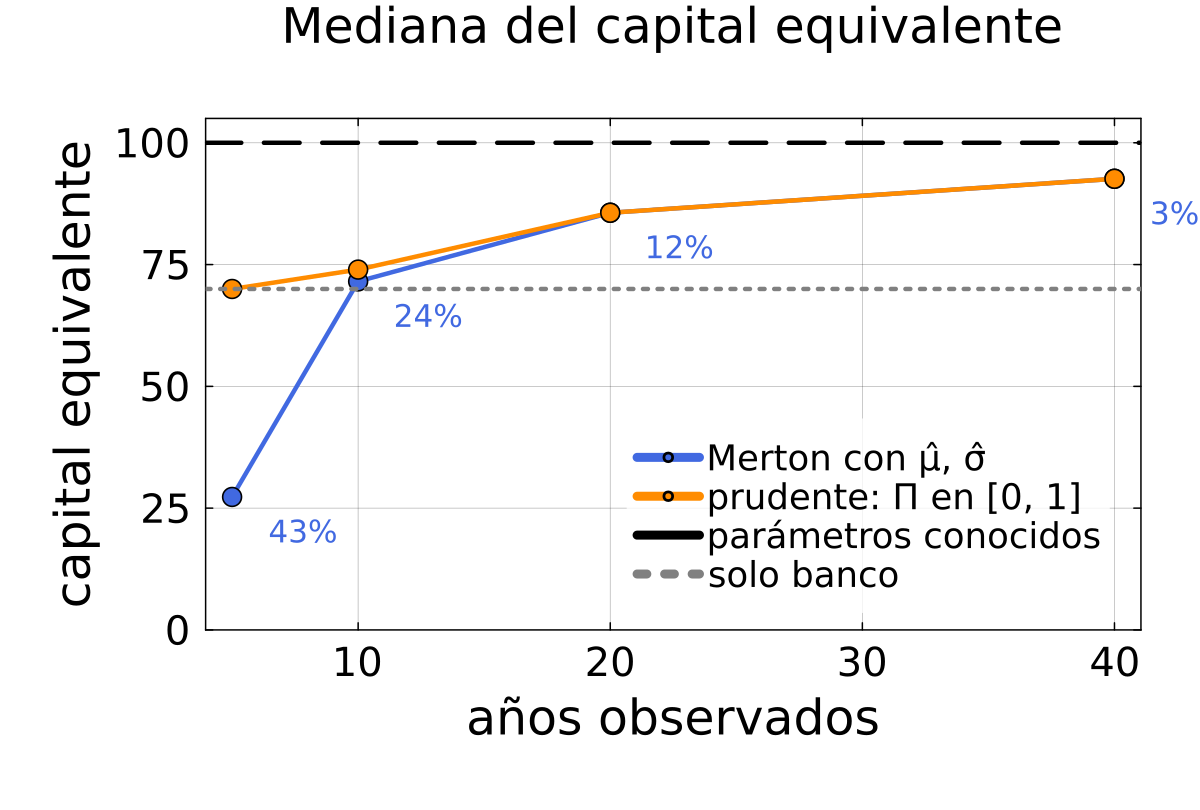

In [17]:
kalman_costo = let h = h_diario
    Random.seed!(7)
    Tobs = [5, 10, 20, 40]; med_ingenuo = Float64[]; med_prudente = Float64[]; P_inf = Float64[]
    println("Tobs  sd(Pi est.)  mediana xCE  P(J = -Inf)  P(xCE < 70)  |  prudente: mediana xCE  P(xCE < 70)")
    for To in Tobs
        x1 = zeros(2000); x2 = zeros(2000); Pis = zeros(2000)
        for i in 1:2000
            R = rendimientos(To, h)
            s2 = var(R)/h
            mu_e = kalman_mu(R, h, s2)[1][end]
            th = (mu_e - par.r)/sqrt(s2)
            Pi_e = (mu_e - par.r)/(par.eta*s2)
            nu_e = (par.gamma - (1 - par.eta)*(par.r + th^2/(2*par.eta)))/par.eta
            Pis[i] = Pi_e; x1[i] = xCE(Jexacto(Pi_e, nu_e))
            Pi_p = clamp(Pi_e, 0.0, 1.0)                                        # versión prudente
            nu_pr = (par.gamma + (par.eta - 1)*(par.r + (mu_e - par.r)*Pi_p - 0.5*par.eta*s2*Pi_p^2))/par.eta
            x2[i] = xCE(Jexacto(Pi_p, nu_pr))
        end
        push!(med_ingenuo, median(x1)); push!(med_prudente, median(x2)); push!(P_inf, mean(x1 .== 0))
        @printf("%4d %11.3f %12.2f %12.3f %12.3f  | %21.2f %12.3f\n", To, std(Pis), median(x1), mean(x1 .== 0), mean(x1 .< 70),
                median(x2), mean(x2 .< 70))
    end
    pd = plot(Tobs, [med_ingenuo med_prudente], marker=:circle, xlabel="años observados", ylabel="capital equivalente",
              ylims=(0, 105), label=["Merton con μ̂, σ̂" "prudente: Π en [0, 1]"], color=[:royalblue :darkorange],
              title="Mediana del capital equivalente", legend=:bottomright)
    hline!(pd, [100], color=:black, ls=:dash, label="parámetros conocidos")
    hline!(pd, [xCE(Psi(par.x0))], color=:gray, ls=:dot, label="solo banco")
    for (T, x, p) in zip(Tobs, med_ingenuo, P_inf)                                # P(J = -inf) en el gráfico
        annotate!(pd, T + 1.5, x - 7, text(@sprintf("%.0f%%", 100p), 14, :royalblue, :left))
    end
    display(guardar(pd, "kalman_costo_control"))
    (Tobs=Tobs, mediana=med_ingenuo, prudente=med_prudente, P_inf=P_inf)
end;

En el gráfico, los porcentajes bajo la curva azul son $P(J=-\infty)$. El costo de no conocer los parámetros es grande:

* con 5 años de datos, la mediana del capital equivalente es 27, el 43% de los inversionistas obtiene $J=-\infty$ y el 65% queda peor que con el banco;
* con 10 años la mediana (72) apenas supera al banco (70), y recién con 40 años se llega a 93.

La versión prudente evita los peores casos: con 5 años su mediana es la del banco, porque cuando $\hat\mu<r$ no invierte.

**Conclusiones de la Sección 4.**
1. $\sigma$ se estima con la varianza realizada, con error $\sigma/\sqrt{2n}$: pequeño con datos diarios.
2. El filtro de Kalman para $\mu$ con deriva constante es el estimador de máxima verosimilitud y alcanza la cota $\sigma/\sqrt T$: con 10 años el error es mayor que la prima de riesgo.
3. Con $q>0$ el filtro puede seguir una deriva variable, pero con $\sigma=0.2$ no mejora al de deriva constante.
4. Usar en el control de Merton los parámetros estimados cuesta mucho: con 10 años la mediana de $x_{CE}$ es 72, y en una cuarta parte de los casos $J=-\infty$. Acotar la fracción a $[0,1]$ reduce las pérdidas.

**Pendiente.** Resolver el problema con información parcial: tratar $\hat\mu_t$ como un estado más y resolver la HJB en $(x,\hat\mu)$.

## 5. Existencia y HJB numérica (objetivos 4 y 5)

Resolvemos la ecuación HJB **numéricamente, sin usar la fórmula de Merton**, y comparamos con $(\Pi^*,\nu)$. Después vemos la existencia del control óptimo: la iteración de políticas construye controles admisibles cuyo valor sube hasta $V$, y la condición $\nu>0$ separa los casos con y sin óptimo.

### 5.1 La HJB en coordenada logarítmica y la condición de borde

**Cambio de variable.** El capital vive en varias escalas, así que trabajamos en $y=\log x$ con $W(y)=V(e^y)$. Como $V'=e^{-y}W'$ y $V''=e^{-2y}(W''-W')$, y escribiendo el consumo como tasa $e=c/x$,
$$
\gamma W=\sup_{\Pi\in[\Pi_{\min},\Pi_{\max}],\ e\ge0}\Big\{U(e\,e^{y})+b(\Pi,e)\,W'+a(\Pi)\,W''\Big\},\qquad b=r+\Pi(\mu-r)-e-\tfrac12\sigma^2\Pi^2,\quad a=\tfrac12\sigma^2\Pi^2. \tag{HJB-log}
$$
Los coeficientes $a$ y $b$ ya no dependen del estado, y una malla uniforme en $y$ es geométrica en $x$. El intervalo de la fracción queda como parámetro para la Sección 6.

**Proposición 5.1 (homotecia).** Para todo $\lambda>0$, $V(\lambda x)=\lambda^{1-\eta}V(x)+\frac{\lambda^{1-\eta}-1}{(1-\eta)\gamma}$. En consecuencia
$$
W'(y)=(1-\eta)W(y)+\frac1\gamma,\qquad W''(y)=(1-\eta)W'(y).
$$

*Demostración.* Si $(\Pi,C)$ es admisible desde $x$, entonces $(\Pi,\lambda C)$ es admisible desde $\lambda x$ y su capital es $\lambda X$, porque la ecuación es lineal en $(X,C)$. Como $U(\lambda c)=\lambda^{1-\eta}U(c)+\frac{\lambda^{1-\eta}-1}{1-\eta}$, se tiene $J(\lambda x;\Pi,\lambda C)=\lambda^{1-\eta}J(x;\Pi,C)+\frac{\lambda^{1-\eta}-1}{(1-\eta)\gamma}$, y tomando supremo se obtiene la igualdad. Derivando en $\lambda=1$ queda $xV'(x)=(1-\eta)V(x)+\frac1\gamma$, que en $y$ es la primera identidad; derivándola se obtiene la segunda. $\blacksquare$

La proposición usa solo la estructura del problema (dinámica lineal y utilidad homogénea), **no** la fórmula de $V$, y sigue valiendo si la fracción se restringe a un intervalo.

**Condición de borde.** En los extremos de la malla reemplazamos la Prop. 5.1 en (HJB-log) para una política fija $(\Pi,e)$:
$$
\big[\gamma-(1-\eta)\big(b+(1-\eta)a\big)\big]W=U(e\,e^{y})+\frac{b+(1-\eta)a}{\gamma},
$$
y el corchete es exactamente $\kappa(\Pi,e)$: **el valor en el borde es el de mantener para siempre la política proporcional del borde**. Así el borde no necesita conocer $V$.

### 5.2 Esquema *upwind* e iteración de políticas

En la malla $y_i=y_1+(i-1)k$ aproximamos $W'$ hacia adelante si $b\ge0$ y hacia atrás si $b<0$ (*upwind*), y $W''$ con diferencias centradas. Para una política fija queda el sistema tridiagonal
$$
\Big(\gamma+\frac{b^++b^-}{k}+\frac{2a}{k^2}\Big)W_i-\Big(\frac{b^+}{k}+\frac{a}{k^2}\Big)W_{i+1}-\Big(\frac{b^-}{k}+\frac{a}{k^2}\Big)W_{i-1}=U(e_i\,e^{y_i}),\qquad b^\pm=\max(\pm b,0).
$$
Los coeficientes fuera de la diagonal son $\le0$ y la diagonal domina estrictamente gracias a $\gamma>0$: es una **M-matriz**, así que el sistema tiene solución única y el esquema es **monótono**. Es la aproximación por cadenas de Markov de [KD], y la monotonía es lo que garantiza la convergencia.

**Iteración de políticas (Howard).** Partimos de "todo en el banco y consumir los intereses", $\Pi=0$, $e=r$ (el capital queda constante y $\kappa=\gamma>0$), y repetimos: (1) *evaluación*: resolver el sistema para la política actual; (2) *mejora*: en cada nodo, maximizar el lado derecho de (HJB-log) con las derivadas de la solución. Las condiciones de primer orden dan
$$
e=\Big(\frac{e^{(1-\eta)y}}{W'}\Big)^{1/\eta},\qquad \Pi=\mathrm{proy}_{[\Pi_{\min},\Pi_{\max}]}\Big(-\frac{(\mu-r)W'}{\sigma^2(W''-W')}\Big)\quad\text{si } W''<W',
$$
y si $W''\ge W'$ el término en $\Pi$ es convexo o lineal, así que el máximo está en uno de los extremos del intervalo, y elegimos el mejor de los dos.

**Proposición 5.2 (Howard) [KD].** Si en la mejora se maximiza el lado derecho **discreto**, los valores son crecientes y convergen a la solución del esquema. Cada iteración es el valor de un control markoviano admisible, así que el método **construye** controles cada vez mejores. Nosotros usamos las condiciones de primer orden con diferencias centradas, que es más simple; la monotonía no queda garantizada, pero se observa en 5.4.

In [18]:
# mejor fracción en [lo, hi] para el término  Pi (mu - r) W1 + (1/2) sigma^2 Pi^2 (W2 - W1)  de (HJB-log)
function mejor_Pi(W1, W2, lo, hi; P=par)
    den = P.sigma^2*(W2 - W1)
    den < 0 && return clamp(-(P.mu - P.r)*W1/den, lo, hi)          # parábola cóncava: proyectar el vértice
    f(p) = p*(P.mu - P.r)*W1 + 0.5*den*p^2                           # convexa o lineal: mejor extremo
    return f(lo) >= f(hi) ? lo : hi
end

# Mejora de la política con las derivadas de W (diferencias centradas). En los bordes de la malla se usa
# la homotecia x V_x = (1 - eta) V + Dv (Dv = 1/gamma en horizonte infinito, D(T - t) en horizonte finito).
function politica(W, y, Dv; P=par, Pimin=-5.0, Pimax=5.0, emax=50.0)
    n = length(W); k = y[2] - y[1]; x = exp.(y)
    W1, W2 = similar(W), similar(W)
    for i in 2:n-1
        W1[i] = (W[i+1] - W[i-1])/(2k); W2[i] = (W[i+1] - 2W[i] + W[i-1])/k^2
    end
    for i in (1, n)
        W1[i] = (1 - P.eta)*W[i] + Dv; W2[i] = (1 - P.eta)*W1[i]
    end
    W1 = max.(W1, 1e-12)                                              # V es creciente: W' > 0
    e = min.((x .^ (1 - P.eta) ./ W1) .^ (1/P.eta), emax)
    Pi = [mejor_Pi(W1[i], W2[i], Pimin, Pimax; P=P) for i in 1:n]
    return Pi, e
end

# Matriz tridiagonal upwind de la política (Pi, e), con un término 1/ds opcional (horizonte finito)
function sistema_upwind(Pi, e, k; P=par, inv_ds=0.0)
    b = P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2
    a = 0.5*P.sigma^2 .* Pi.^2
    bp, bm = max.(b, 0), max.(-b, 0)
    dl = -(bm ./ k .+ a ./ k^2)                     # coeficiente de W[i-1]
    d  = inv_ds .+ P.gamma .+ (bp .+ bm) ./ k .+ 2a ./ k^2
    du = -(bp ./ k .+ a ./ k^2)                     # coeficiente de W[i+1]
    return dl, d, du, b, a
end

# Resuelve (HJB-log) en la malla uniforme y por iteración de políticas (Howard).
# Devuelve W, la política (Pi, e) en cada nodo y el valor en x0 de cada iteración.
function resolver_hjb(y; P=par, Pimin=-5.0, Pimax=5.0, tol=1e-10, maxit=100)
    n = length(y); k = y[2] - y[1]; x = exp.(y)
    i0 = argmin(abs.(x .- P.x0))                       # nodo de x0
    Pi = fill(clamp(0.0, Pimin, Pimax), n); e = fill(P.r, n)   # política inicial: banco, consumir los intereses
    W = zeros(n); historial = Float64[]
    for it in 1:maxit
        dl, d, du, b, a = sistema_upwind(Pi, e, k; P=P)
        rhs = U.(e .* x; P=P)
        for i in (1, n)                                 # bordes: Prop. 5.1 (homotecia)
            dl[i] = 0.0; du[i] = 0.0
            d[i] = kappa(Pi[i], e[i]; P=P)
            rhs[i] = U(e[i]*x[i]; P=P) + (b[i] + (1 - P.eta)*a[i])/P.gamma
        end
        Wn = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
        push!(historial, Wn[i0])
        Pi, e = politica(Wn, y, 1/P.gamma; P=P, Pimin=Pimin, Pimax=Pimax)
        cambio = maximum(abs.(Wn .- W))/maximum(abs.(Wn))
        W = Wn
        cambio < tol && break
    end
    return (W=W, Pi=Pi, e=e, x=x, historial=historial)
end

malla(n; xmin=1.0, xmax=1e4) = collect(range(log(xmin), log(xmax), length=n))   # malla uniforme en y = log x

malla (generic function with 1 method)

### 5.3 Validación contra la solución exacta (objetivo 5)

Malla en $x\in[1,10^4]$ con $n$ impar, de modo que $x_0=100$ es el nodo central. Medimos el error de los controles en $x\in[5,2000]$ y el error en $V(x_0)$, también en capital equivalente.

    n  iter  max|Pi - Pi*|  max|e - nu|  W(x0) - V(x0)  xCE - x0
  101     8       6.55e-04     1.67e-04      -2.43e-02   -0.5523
  201     8       2.80e-04     7.46e-05      -1.20e-02   -0.2730
  401     7       1.24e-04     3.50e-05      -5.95e-03   -0.1359
  801     7       5.79e-05     1.70e-05      -2.97e-03   -0.0678
 1601     7       2.80e-05     8.34e-06      -1.48e-03   -0.0339
 3201     6       1.37e-05     4.13e-06      -7.41e-04   -0.0169
orden de convergencia en V(x0): 1.02, 1.01, 1.00, 1.00, 1.00


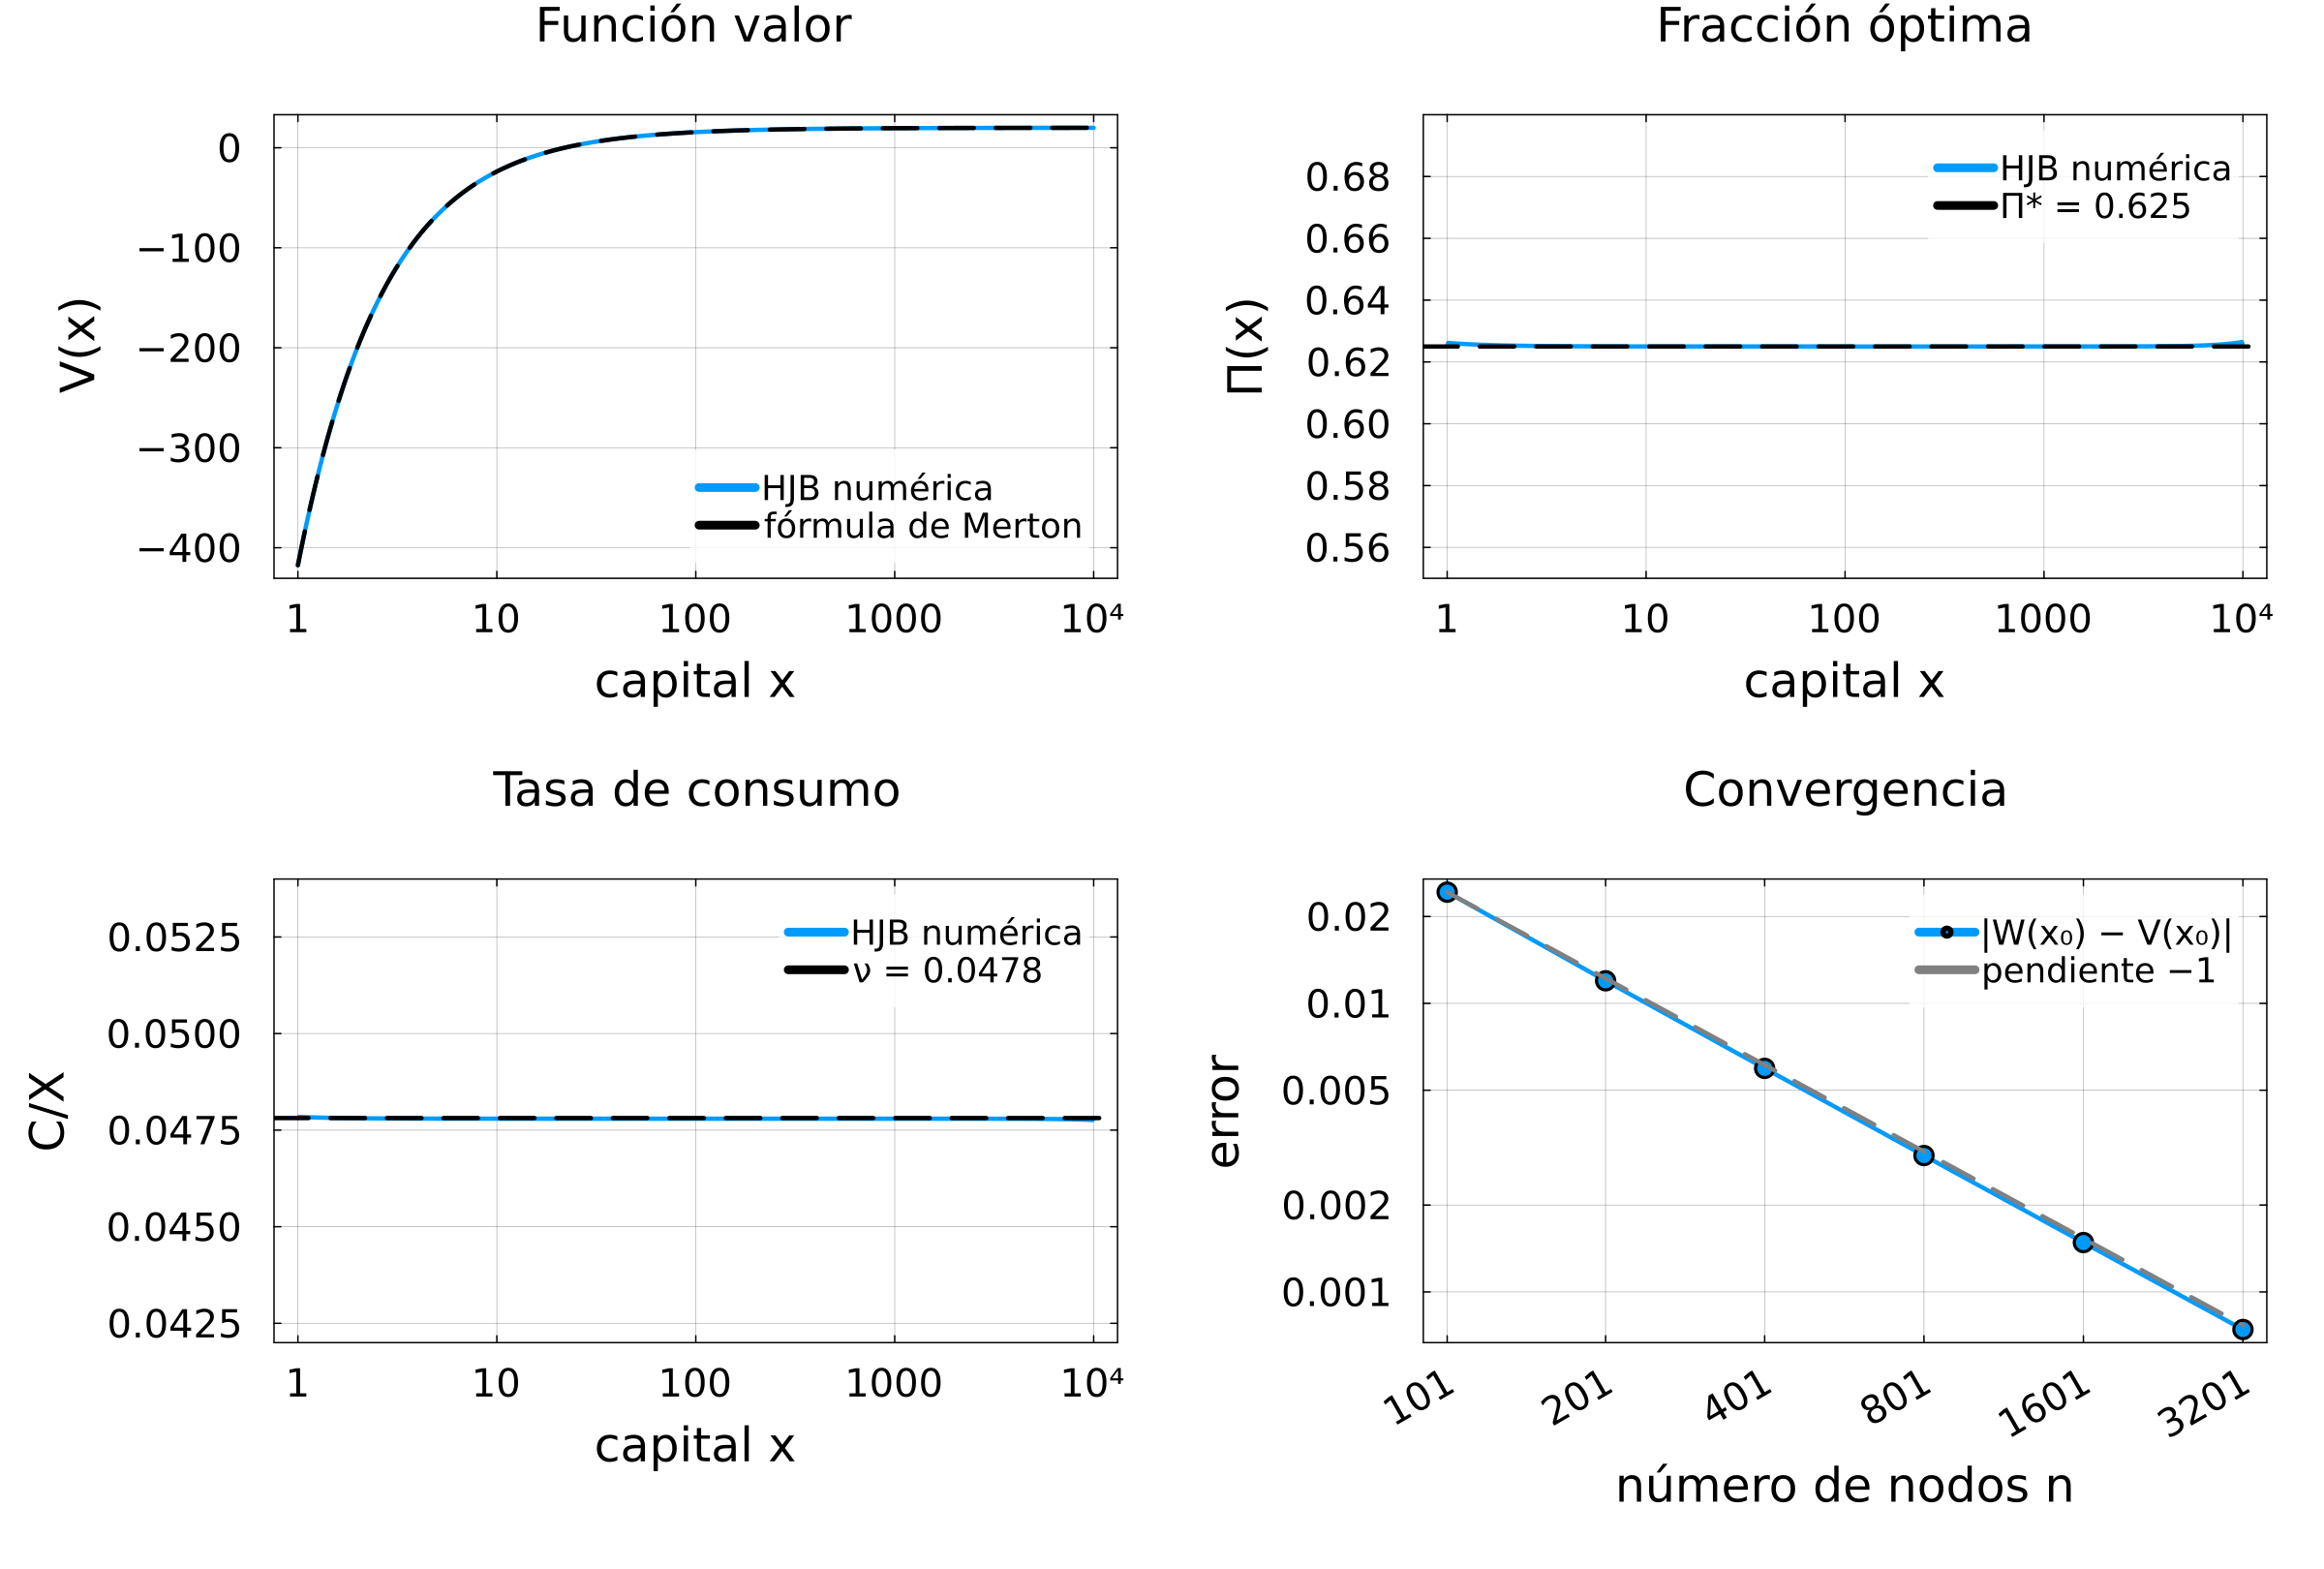

In [19]:
let ns = [101, 201, 401, 801, 1601, 3201], errV = Float64[]
    println("    n  iter  max|Pi - Pi*|  max|e - nu|  W(x0) - V(x0)  xCE - x0")
    for n in ns
        s = resolver_hjb(malla(n))
        I = (s.x .>= 5) .& (s.x .<= 2000); i0 = (n + 1) ÷ 2
        push!(errV, s.W[i0] - V(par.x0))
        @printf("%5d %5d %14.2e %12.2e %14.2e %9.4f\n", n, length(s.historial),
                maximum(abs.(s.Pi[I] .- Pim)), maximum(abs.(s.e[I] .- nu)), errV[end], xCE(s.W[i0]) - par.x0)
    end
    println("orden de convergencia en V(x0): ", join([@sprintf("%.2f", log2(errV[j]/errV[j+1])) for j in 1:length(ns)-1], ", "))

    s = resolver_hjb(malla(801))
    ejex = ([1, 10, 100, 1000, 10000], ["1", "10", "100", "1000", "10⁴"])
    p1 = plot(s.x, s.W, xscale=:log10, label="HJB numérica", title="Función valor", xlabel="capital x", ylabel="V(x)",
              legend=:bottomright, xticks=ejex)
    plot!(p1, s.x, V.(s.x), ls=:dash, color=:black, label="fórmula de Merton")
    p2 = plot(s.x, s.Pi, xscale=:log10, label="HJB numérica", title="Fracción óptima", xlabel="capital x", ylabel="Π(x)",
              ylims=(0.55, 0.7), xticks=ejex)
    hline!(p2, [Pim], ls=:dash, color=:black, label="Π* = 0.625")
    p3 = plot(s.x, s.e, xscale=:log10, label="HJB numérica", title="Tasa de consumo", xlabel="capital x", ylabel="C/X",
              ylims=(0.042, 0.054), xticks=ejex)
    hline!(p3, [nu], ls=:dash, color=:black, label="ν = 0.0478")
    p4 = plot(ns, abs.(errV), xscale=:log10, yscale=:log10, marker=:circle, label="|W(x₀) − V(x₀)|",
              title="Convergencia", xlabel="número de nodos n", ylabel="error", xticks=(ns, string.(ns)), xrotation=30,
              yticks=([1e-3, 2e-3, 5e-3, 1e-2, 2e-2], ["0.001", "0.002", "0.005", "0.01", "0.02"]))
    plot!(p4, ns, abs(errV[1]) .* ns[1] ./ ns, ls=:dash, color=:gray, label="pendiente −1")
    for (p, nombre) in [(p1, "valor"), (p2, "fraccion"), (p3, "consumo"), (p4, "convergencia")]
        guardar(p, "hjb_" * nombre)
    end
    plot(p1, p2, p3, p4, layout=(2, 2), size=(1600, 1080))
end

El esquema converge con **orden 1** en $V(x_0)$, lo esperado de un esquema *upwind*: se elige porque es monótono, a costa de ser de primer orden. Con 801 nodos el error en $V(x_0)$ equivale a perder 0.07 de capital sobre 100, y los controles numéricos son constantes en $x$ e iguales a $\Pi^*=0.625$ y $\nu=0.0478$ con error menor que $10^{-4}$: la HJB numérica **reproduce la solución de Merton sin usarla**. La iteración de políticas converge en 6 a 8 iteraciones.

### 5.4 Existencia (objetivo 4)

**Teoría.** La existencia se demuestra con el teorema de la Sección 1: si $\nu>0$, la cota por dualidad da $J\le V$ para todo control de $\mathcal A_K$ y el control de Merton la alcanza, así que existe un control óptimo (markoviano) y el consumo óptimo es único.

**Numérica.** Cada iteración de Howard es el valor de un control markoviano admisible, así que $W^{(m)}(x_0)\le V(x_0)$ (salvo el error de malla), y la sucesión sube hasta el valor óptimo.

In [20]:
let s = resolver_hjb(malla(801))
    println(" iteración      W(x0)      xCE")
    for (m, w) in enumerate(s.historial)
        @printf("%6d %13.5f %9.3f\n", m, w, xCE(w))
    end
    @printf(" exacto  %13.5f %9.3f\n", V(par.x0), par.x0)
end

 iteración      W(x0)      xCE
     1      13.33333    65.616
     2      15.45509    96.248
     3      15.62067    99.887
     4      15.62264    99.932
     5      15.62265    99.932
     6      15.62265    99.932
     7      15.62265    99.932
 exacto       15.62561   100.000


**¿Qué pasa al variar $\eta$?** El teorema pide $\nu>0$, que siempre se cumple si $\eta\ge1$. Si $\eta<1$, la condición es $\gamma>(1-\eta)\big(r+\frac{\theta^2}{2\eta}\big)$, que falla cuando el inversionista tolera mucho riesgo. Entonces $V=+\infty$ y el problema está **mal planteado**: si $\nu<0$, la estrategia $(\Pi^*,\bar cX)$ con $\bar c$ pequeño cumple $\kappa=\eta\nu+(1-\eta)\bar c\le0$ y ya da $J=+\infty$, y si $\nu=0$ el supremo es $+\infty$ y no se alcanza. Calculamos el umbral $\eta_{\min}$ y resolvemos la HJB para varios $\eta>\eta_{\min}$.

nu > 0 si y solo si eta > eta_min = 0.4767

  eta  Pi(x0) HJB     Pi*   e(x0) HJB       nu   V(x0) HJB     V(x0)
  0.5     2.4995   2.5000    0.00750   0.00750    191.0402  190.9401
  1.5     0.8333   0.8333    0.05027   0.05028     22.2576   22.2595
  2.0     0.6250   0.6250    0.04780   0.04781     15.6241   15.6256
  3.0     0.4167   0.4167    0.04360   0.04361      9.3966    9.3972
  5.0     0.2500   0.2500    0.03898   0.03900      4.9722    4.9723


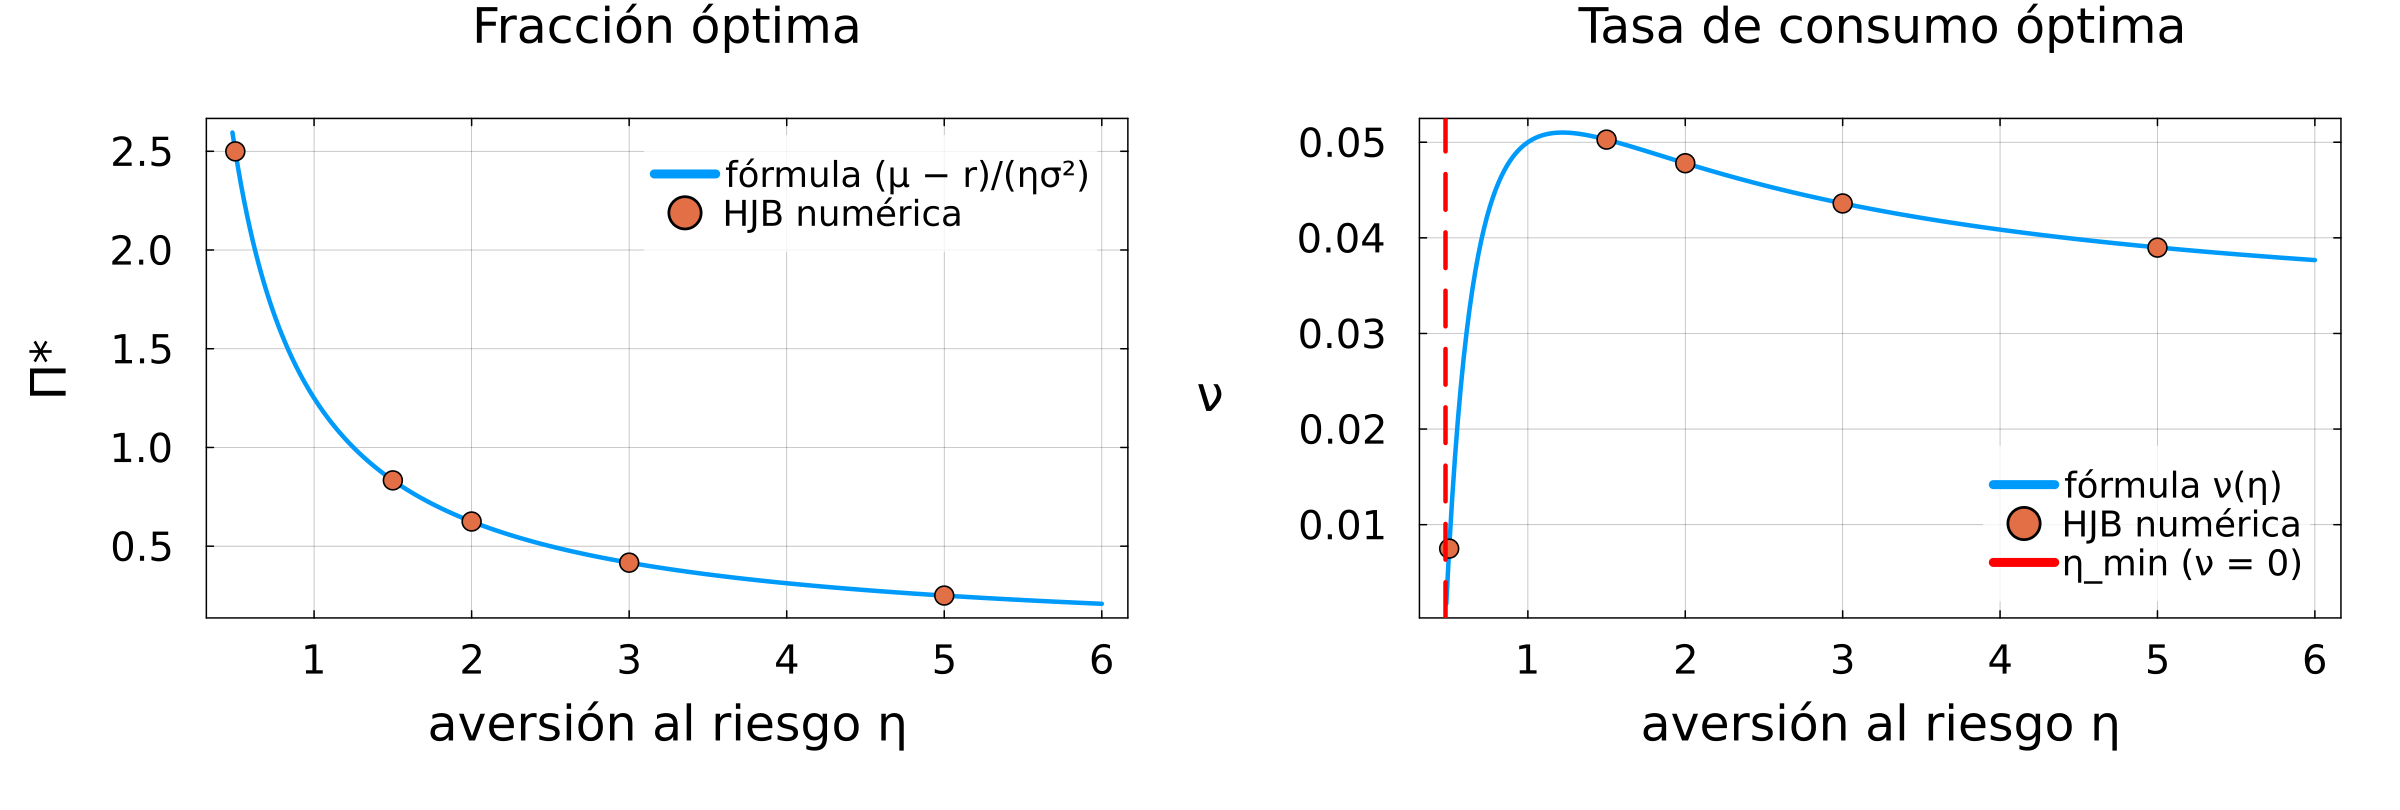

In [21]:
nu_eta(eta) = nustar(merge(par, (eta = eta,)))

eta_min = let a = 0.1, b = 1.0          # nu(eta_min) = 0, por bisección en (0.1, 1)
    for _ in 1:60
        m = (a + b)/2
        nu_eta(m) > 0 ? (b = m) : (a = m)
    end
    (a + b)/2
end
@printf("nu > 0 si y solo si eta > eta_min = %.4f\n\n", eta_min)

let etas = [0.5, 1.5, 2.0, 3.0, 5.0], res = []
    println("  eta  Pi(x0) HJB     Pi*   e(x0) HJB       nu   V(x0) HJB     V(x0)")
    for eta in etas
        P = merge(par, (eta = eta,))
        s = resolver_hjb(malla(1601); P=P)
        push!(res, (s.Pi[801], s.e[801]))
        @printf("%5.1f %10.4f %8.4f %10.5f %9.5f %11.4f %9.4f\n", eta, s.Pi[801], Pistar(P), s.e[801], nustar(P), s.W[801], V(P.x0; P=P))
    end
    eg = range(eta_min + 0.005, 6, length=300)
    q1 = plot(eg, [Pistar(merge(par, (eta = e_,))) for e_ in eg], label="fórmula (μ − r)/(ησ²)",
              xlabel="aversión al riesgo η", ylabel="Π*", title="Fracción óptima")
    scatter!(q1, etas, first.(res), label="HJB numérica")
    q2 = plot(eg, nu_eta.(eg), label="fórmula ν(η)", xlabel="aversión al riesgo η", ylabel="ν", yguidefontrotation=-90,
              title="Tasa de consumo óptima", legend=:bottomright)
    scatter!(q2, etas, last.(res), label="HJB numérica")
    vline!(q2, [eta_min], ls=:dash, color=:red, label="η_min (ν = 0)")
    guardar(q1, "hjb_fraccion_eta"); guardar(q2, "hjb_consumo_eta")
    plot(q1, q2, layout=(1, 2), size=(1600, 540))
end

La sucesión de Howard es creciente: la política inicial vale lo mismo que tener 65.6 de capital con Merton, tras una mejora se llega a 96.2 y en tres iteraciones a 99.9. Para todos los $\eta>\eta_{\min}\approx0.477$ probados, la HJB numérica coincide con las fórmulas. La fracción óptima cae como $1/\eta$, y la tasa de consumo es máxima cerca de $\eta=1$. Cuando $\eta\to\eta_{\min}$, $\nu\to0$: el inversionista posterga el consumo indefinidamente, y para $\eta\le\eta_{\min}$ el problema está mal planteado. La condición $\nu>0$ del teorema de existencia no es solo técnica.

**Pendientes.** Demostrar la convergencia del esquema a la solución de viscosidad (Barles–Souganidis: monotonía, estabilidad y consistencia), y subir el orden sin perder la monotonía.

## 6. Controles admisibles restringidos (objetivo 6)

### 6.1 Fracción acotada

Ross [R, 2.7] pide $|\Pi_t|\le K_\Pi$, y también es natural prohibir el apalancamiento y la venta corta, $0\le\Pi_t\le1$. Consideramos $\Pi_t\in[\Pi_{\min},\Pi_{\max}]$.

**Proposición 6.1.** Sea $\bar p=\mathrm{proy}_{[\Pi_{\min},\Pi_{\max}]}(\Pi^*)$. Si $\nu(\bar p)>0$, el control óptimo en la clase restringida es $\Pi_t\equiv\bar p$, $C_t=\nu(\bar p)X_t$, con valor $V_{\bar p}(x)=\frac{1}{1-\eta}\big(\nu(\bar p)^{-\eta}x^{1-\eta}-\frac1\gamma\big)$. En particular, si $\Pi^*\in[\Pi_{\min},\Pi_{\max}]$ la restricción no cambia nada, y si no, **también cambia el consumo**.

*Demostración.* La Prop. 5.1 sigue valiendo con la restricción, así que $V$ es de la forma $\frac{A}{1-\eta}x^{1-\eta}-\frac{1}{(1-\eta)\gamma}$. Al reemplazar en la HJB, el término que depende de $\Pi$ es $Ax^{1-\eta}\big[\Pi(\mu-r)-\frac\eta2\sigma^2\Pi^2\big]$, una parábola cóncava cuyo máximo sobre el intervalo es la proyección del vértice $\Pi^*$. Con $\Pi=\bar p$, la ecuación para $A$ es la del caso sin restricción con $\rho(\Pi^*)=r+\frac{\theta^2}{2\eta}$ reemplazado por $\rho(\bar p)$, y da $A=\nu(\bar p)^{-\eta}$. La verificación es la misma del teorema de la Sección 1. $\blacksquare$

In [22]:
let y = malla(801), i0 = 401
    cotas = [("sin restricción (|Pi| <= 5)", -5.0, 5.0), ("|Pi| <= 1 (Ross, K = 1)",  -1.0, 1.0),
             ("0 <= Pi <= 0.5",              0.0, 0.5), ("0 <= Pi <= 0.25",          0.0, 0.25),
             ("Pi >= 1 (mínimo en acción)",  1.0, 5.0), ("solo banco, Pi = 0",       0.0, 0.0)]
    @printf("%-28s %7s %7s %9s %9s %9s %9s %7s\n", "restricción", "Pi HJB", "p", "e HJB", "nu(p)", "W(x0)", "V_p(x0)", "xCE")
    for (nombre, lo, hi) in cotas
        s = resolver_hjb(y; Pimin=lo, Pimax=hi)
        p = clamp(Pim, lo, hi)
        Vp = Jexacto(p, nu_p(p))
        @printf("%-28s %7.4f %7.4f %9.5f %9.5f %9.4f %9.4f %7.2f\n", nombre, s.Pi[i0], p, s.e[i0], nu_p(p), s.W[i0], Vp, xCE(Vp))
    end
end

restricción                   Pi HJB       p     e HJB     nu(p)     W(x0)   V_p(x0)     xCE
sin restricción (|Pi| <= 5)   0.6250  0.6250   0.04780   0.04781   15.6226   15.6256  100.00
|Pi| <= 1 (Ross, K = 1)       0.6250  0.6250   0.04780   0.04781   15.6226   15.6256  100.00
0 <= Pi <= 0.5                0.5000  0.5000   0.04749   0.04750   15.5665   15.5679   98.70
0 <= Pi <= 0.25               0.2500  0.2500   0.04499   0.04500   15.0594   15.0617   88.58
Pi >= 1 (mínimo en acción)    1.0000  1.0000   0.04496   0.04500   15.0523   15.0617   88.58
solo banco, Pi = 0            0.0000  0.0000   0.03997   0.04000   13.7410   13.7500   69.99


El solver con cotas reproduce la Prop. 6.1 en todos los casos. Las cotas que contienen a $\Pi^*=0.625$ no cambian nada; con $\eta=2$, $\rho$ es simétrica en torno a $\Pi^*$, así que $0\le\Pi\le0.25$ y $\Pi\ge1$ cuestan lo mismo ($x_{CE}=88.6$); y la pérdida es pequeña cerca de $\Pi^*$ y grande lejos de él (no invertir nada equivale a perder 30 de capital).

### 6.2 Controles markovianos y no markovianos

Un control es **markoviano** si $\Pi_t=\pi(t,X_t)$ y $C_t=c(t,X_t)$; uno **no markoviano** usa la historia, del capital o del precio.

**Proposición 6.2.** Para todo control de $\mathcal A_K$, markoviano o no, $J(x;\Pi,C)\le V(x)$, y el control markoviano de Merton alcanza la igualdad. Por lo tanto, restringir la clase a controles markovianos, o incluso a estrategias proporcionales, **no cambia el valor**.

*Demostración.* La cota por dualidad usa solo la desigualdad de Fenchel y la restricción presupuestaria (Prop. 2.1), que valen para todo control de $\mathcal A_K$ sin importar cómo dependa de la historia. $\blacksquare$

Al revés, restringir a controles **deterministas en monto** ($\Pi_tX_t=\pi(t)$, $C_t=c(t)$) sí es un problema: el capital es gaussiano y se vuelve negativo con probabilidad positiva, así que esos controles no son admisibles.

**Experimento.** Comparamos con Monte-Carlo, en los mismos escenarios, cinco reglas:

| Regla | Tipo |
| --- | --- |
| Merton: $\Pi^*$, $C=\nu X$ | markoviana, óptima |
| Ingenua: $\Pi=1$, $C=0.04X$ | markoviana |
| Caída desde el máximo: $\Pi_t=\Pi^*X_t/\max_{s\le t}X_s$, $C=\nu X$ | no markoviana: mira la historia del capital |
| Media móvil: $\Pi_t=1$ si $S_t$ supera su promedio del último año y $0$ si no, $C=\nu X$ | no markoviana: mira la historia del precio |
| Merton aprendiendo $\mu$: $\Pi_t=\frac{\hat\mu_t-r}{\eta\sigma^2}$ acotada a $[0,2]$, $\hat\mu_t=\frac{\log S_t}{t}+\frac{\sigma^2}2$ desde el año 1 ($\sigma$ conocido) | no markoviana: aprende $\mu$ en línea |

Cada regla se aplica hasta $T=30$ años y después se sigue con Merton, así que el estimador lleva el valor de continuación $e^{-\gamma T}V(X_T)$ y cumple $\mathbb E[Y]\le V(x_0)$. El capital se simula congelando el control en cada paso semanal (exacto para el control congelado).

(La última regla no es la de la Sección 4.5: allí la ventana de datos es fija y $\sigma$ se estima; aquí $\hat\mu_t$ se actualiza cada semana, $\sigma$ es conocido y la fracción se acota. Por eso los capitales equivalentes son distintos.)

In [23]:
# precio de la acción (S_0 = 1) en los escenarios Z; filas = tiempos t_k = (k - 1) h
function simular_precio(Z, h; P=par)
    logS = cumsum((P.mu - P.sigma^2/2)*h .+ P.sigma*sqrt(h) .* Z, dims=1)
    return vcat(ones(1, size(Z, 2)), exp.(logS))
end

# Y = utilidad descontada hasta T (trapecio) + e^{-gamma T} V(X_T), para una regla (Pi, e) = regla(k, X, Xmax)
# que se decide al inicio de cada paso con la información disponible y se congela durante el paso
function utilidad_regla(regla, Z, h; P=par)
    K, N = size(Z)
    X = fill(P.x0, N); Xmax = copy(X); Y = zeros(N)
    for k in 1:K
        Pi, e = regla(k, X, Xmax)
        Y .+= (k == 1 ? h/2 : h)*exp(-P.gamma*(k - 1)*h) .* U.(e .* X; P=P)
        X .*= exp.((P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2) .* h .+ P.sigma .* Pi .* sqrt(h) .* Z[k, :])
        Xmax .= max.(Xmax, X)
    end
    Pi, e = regla(K + 1, X, Xmax)
    return Y .+ (h/2)*exp(-P.gamma*K*h) .* U.(e .* X; P=P) .+ exp(-P.gamma*K*h) .* V.(X; P=P)
end

utilidad_regla (generic function with 1 method)

In [24]:
reglas_historia = let T = 30.0, h = 1/52, N = 5_000
    Random.seed!(20)
    K = round(Int, T/h)
    Z = randn(K, N)
    S = simular_precio(Z, h)
    uno, nuN = ones(N), fill(nu, N)
    media_movil(k) = Float64.(S[k, :] .> vec(mean(view(S, max(1, k - 52):k, :), dims=1)))
    pi_aprende(k) = k <= 53 ? zeros(N) : clamp.((log.(S[k, :]) ./ ((k - 1)*h) .+ par.sigma^2/2 .- par.r) ./ (par.eta*par.sigma^2), 0.0, 2.0)
    reglas = ["Merton (markoviana, óptima)"  => (k, X, Xmax) -> (Pim .* uno, nuN),
              "Ingenua: Pi = 1, C = 0.04X"   => (k, X, Xmax) -> (uno, 0.04 .* uno),
              "Caída desde el máximo"        => (k, X, Xmax) -> (Pim .* X ./ Xmax, nuN),
              "Media móvil de 1 año"         => (k, X, Xmax) -> (media_movil(k), nuN),
              "Merton aprendiendo mu"        => (k, X, Xmax) -> (pi_aprende(k), nuN)]
    res = Dict{String, Vector{Float64}}(); tabla = Dict{String, Float64}()
    @printf("%-30s %10s %8s %8s   (Monte-Carlo, %d trayectorias)\n", "regla", "J_N", "+-IC95", "xCE", N)
    for (nombre, regla) in reglas
        Y = utilidad_regla(regla, Z, h); res[nombre] = Y; tabla[nombre] = xCE(mean(Y))
        @printf("%-30s %10.4f %8.4f %8.2f\n", nombre, mean(Y), 1.96*std(Y)/sqrt(N), xCE(mean(Y)))
    end
    @printf("%-30s %10.4f\n\n", "V(x0) exacto", V(par.x0))
    YM = res["Merton (markoviana, óptima)"]
    @printf("%-30s %12s %10s\n", "regla", "J_M - J", "+-IC95 pareado")
    for (nombre, _) in reglas[2:end]
        d = YM .- res[nombre]
        @printf("%-30s %12.4f %10.4f\n", nombre, mean(d), 1.96*std(d)/sqrt(N))
    end
    tabla
end;

regla                                 J_N   +-IC95      xCE   (Monte-Carlo, 5000 trayectorias)
Merton (markoviana, óptima)       15.6225   0.0524    99.93
Ingenua: Pi = 1, C = 0.04X        15.1178   0.1019    89.60
Caída desde el máximo             15.5328   0.0415    97.92
Media móvil de 1 año              14.8063   0.0802    84.22
Merton aprendiendo mu             14.6525   0.0641    81.80
V(x0) exacto                      15.6256

regla                               J_M - J +-IC95 pareado
Ingenua: Pi = 1, C = 0.04X           0.5047     0.0528
Caída desde el máximo                0.0897     0.0170
Media móvil de 1 año                 0.8163     0.0577
Merton aprendiendo mu                0.9700     0.0531


Ninguna regla supera a $V(x_0)$ y la de Merton lo alcanza dentro del intervalo de confianza, como dice la Prop. 6.2; las comparaciones pareadas muestran con significancia que todas las demás son peores. Mirar la historia del capital o del precio no ayuda, porque el futuro de la acción no depende de ella; la historia solo sirve cuando hay algo que aprender, como un parámetro desconocido, y aun así cuesta (Sección 4).

**Conclusiones de las Secciones 5 y 6.**
1. La HJB se resuelve con un esquema *upwind* monótono e iteración de políticas, con una condición de borde que sale de la homotecia y no necesita conocer $V$. Converge con orden 1 y reproduce $\Pi^*$, $\nu$ y $V$.
2. La existencia del óptimo es un teorema (dualidad) si $\nu>0$; la iteración de políticas lo ilustra construyendo controles admisibles cada vez mejores. Con $\eta\le\eta_{\min}\approx0.477$ el problema está mal planteado.
3. Con la fracción acotada, el óptimo es la proyección de $\Pi^*$ con su propia tasa de consumo $\nu(\bar p)$. Restringir a controles markovianos no pierde valor.

## 7. Horizonte finito y tiempo de parada (objetivo 7)

### 7.1 Horizonte finito: solución explícita

Con horizonte $T$ y una **herencia** de peso $\varepsilon\ge0$ (utilidad del capital que queda en $T$), el criterio es
$$
J_T(x;\Pi,C)=\mathbb E_x\Big[\int_0^Te^{-\gamma t}U(C_t)\,dt+\varepsilon\,e^{-\gamma T}U(X_T)\Big],
$$
y la función valor $V(t,x)$ resuelve la HJB **parabólica**
$$
\partial_tV-\gamma V+\sup_{\Pi,\ c\ge0}\Big\{U(c)+\big[(r+\Pi(\mu-r))x-c\big]\partial_xV+\tfrac12\sigma^2\Pi^2x^2\partial_{xx}V\Big\}=0,\qquad V(T,x)=\varepsilon\,U(x).
$$

**Proposición 7.1.** Sean $s=T-t$ el tiempo que falta,
$$
L(s)=\frac1\nu+\Big(\varepsilon^{1/\eta}-\frac1\nu\Big)e^{-\nu s},\qquad D(s)=\frac{1-e^{-\gamma s}}{\gamma}+\varepsilon\,e^{-\gamma s}.
$$
Entonces $V(t,x)=\frac{1}{1-\eta}\big(L(s)^\eta x^{1-\eta}-D(s)\big)$, y el control óptimo es $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$ (el de horizonte infinito) con consumo $C^*_t=X_t/L(T-t)$.

*Demostración.* Probamos $V=\frac{L^\eta x^{1-\eta}}{1-\eta}+g(t)$. Como en el caso estacionario, el supremo en $\Pi$ da $\Pi^*$ y el supremo en $c$ da $c=L^{-1}x$. Agrupando los términos en $x^{1-\eta}$ queda la EDO $L'=\nu L-1$ (con $'=d/dt$), cuya solución con $L(T)=\varepsilon^{1/\eta}$ es la del enunciado; los términos constantes dan $g'-\gamma g=\frac{1}{1-\eta}$ con $g(T)=-\frac{\varepsilon}{1-\eta}$, cuya solución es $g=-\frac{D(s)}{1-\eta}$. La verificación es la de la Sección 1, ahora en $[0,T]$. $\blacksquare$

**Consecuencias.**
* La fracción invertida no depende del horizonte: con utilidad CRRA el inversionista no se vuelve más conservador al acercarse a $T$.
* Si $\varepsilon^{1/\eta}<1/\nu$ (con nuestros parámetros, $\varepsilon<437$), $L$ decrece hacia $T$ y la tasa de consumo $1/L(s)$ **sube** a medida que se acerca $T$, hasta $\varepsilon^{-1/\eta}$. **Sin herencia** ($\varepsilon=0$) se tiene $L(s)\approx s$ cerca de $T$, así que $C^*/X\approx\frac{1}{T-t}\to\infty$: el inversionista consume todo su capital.
* Cuando $T\to\infty$, $L(s)\to1/\nu$ y $D(s)\to1/\gamma$: se recupera el horizonte infinito.

In [25]:
D(s, eps; P=par) = (1 - exp(-P.gamma*s))/P.gamma + eps*exp(-P.gamma*s)      # s = T - t
L(s, eps; P=par) = 1/nustar(P) + (eps^(1/P.eta) - 1/nustar(P))*exp(-nustar(P)*s)
VT(s, x, eps; P=par) = (L(s, eps; P=P)^P.eta*x^(1 - P.eta) - D(s, eps; P=P))/(1 - P.eta)   # valor con s años por delante

for eps in [0.0, 0.1, 1.0]
    @printf("eps = %.1f:  V(0, x0) con T = 20: %.4f   consumo C/X en t = 0: %.4f,  en t = 19: %.4f,  en t = T: %s\n",
            eps, VT(20.0, par.x0, eps), 1/L(20.0, eps), 1/L(1.0, eps), eps > 0 ? @sprintf("%.4f", 1/L(0.0, eps)) : "infinito")
end

eps = 0.0:  V(0, x0) con T = 20: 10.9843   consumo C/X en t = 0: 0.0777,  en t = 19: 1.0241,  en t = T: infinito
eps = 0.1:  V(0, x0) con T = 20: 10.9897   consumo C/X en t = 0: 0.0769,  en t = 19: 0.7825,  en t = T: 3.1623
eps = 1.0:  V(0, x0) con T = 20: 11.2517   consumo C/X en t = 0: 0.0754,  en t = 19: 0.5182,  en t = T: 1.0000


### 7.2 La HJB parabólica numérica

Usamos el esquema de la Sección 5 en $y=\log x$, marchando **hacia atrás en el tiempo** desde $V(T,\cdot)=\varepsilon U$. Con paso $\Delta s$ en $s=T-t$: en cada paso calculamos la política con las condiciones de primer orden sobre la solución del paso anterior, y resolvemos el sistema tridiagonal de **Euler implícito**, que sigue siendo una M-matriz (la diagonal gana $1/\Delta s$), así que es estable para cualquier $\Delta s$.

**Proposición 7.2 (homotecia con horizonte finito).** $x\,\partial_xV(t,x)=(1-\eta)V(t,x)+D(T-t)$.

*Demostración.* Como la Prop. 5.1: escalar el capital por $\lambda$ multiplica $J_T$ por $\lambda^{1-\eta}$ y le suma $\frac{\lambda^{1-\eta}-1}{1-\eta}D(T-t)$. Se deriva en $\lambda=1$. $\blacksquare$

En los bordes de la malla usamos esta identidad, que no usa $L$, solo la función conocida $D$. La herencia es necesaria para el esquema: con $\varepsilon=0$ el consumo explota en $T$ y la política del primer paso no está definida. Por eso resolvemos numéricamente $\varepsilon=1$ y $\varepsilon=0.1$, y el caso $\varepsilon=0$ lo vemos con la fórmula.

In [26]:
# HJB parabólica hacia atrás desde t = T, con M pasos de Euler implícito.
# Devuelve W(0, .), la política en t = 0 y la tasa de consumo en x0 a lo largo del tiempo.
function resolver_finito(y, T, M; eps=1.0, P=par)
    n = length(y); k = y[2] - y[1]; x = exp.(y); ds = T/M
    i0 = argmin(abs.(x .- P.x0))
    W = eps .* U.(x; P=P)                               # condición final V(T, x) = eps U(x)
    e_x0 = zeros(M)
    for m in 1:M
        Pi, e = politica(W, y, D((m - 1)*ds, eps; P=P); P=P)
        e_x0[m] = e[i0]
        dl, d, du, b, a = sistema_upwind(Pi, e, k; P=P, inv_ds=1/ds)
        rhs = U.(e .* x; P=P) .+ W ./ ds
        for i in (1, n)                                 # bordes: Prop. 7.2
            dl[i] = 0.0; du[i] = 0.0
            d[i] = 1/ds + kappa(Pi[i], e[i]; P=P)
            rhs[i] = W[i]/ds + U(e[i]*x[i]; P=P) + (b[i] + (1 - P.eta)*a[i])*D(m*ds, eps; P=P)
        end
        W = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
    end
    Pi, e = politica(W, y, D(T, eps; P=P); P=P)
    return (W=W, Pi=Pi, e=e, x=x, s=ds .* (0:M-1), e_x0=e_x0)
end

let T = 20.0
    println("  eps     n     M   W(0,x0)    exacto     error   Pi(0,x0)   C/X en t=0   exacto")
    for eps in [1.0, 0.1], (n, M) in [(201, 200), (401, 400), (801, 800), (1601, 1600)]
        i0 = (n + 1) ÷ 2
        s = resolver_finito(malla(n), T, M; eps=eps)
        @printf("%5.1f %5d %5d %9.4f %9.4f %9.1e %9.4f %11.5f %9.5f\n", eps, n, M, s.W[i0], VT(T, par.x0, eps),
                s.W[i0] - VT(T, par.x0, eps), s.Pi[i0], s.e[i0], 1/L(T, eps))
    end
end

  eps     n     M   W(0,x0)    exacto     error   Pi(0,x0)   C/X en t=0   exacto
  1.0   201   200   11.2049   11.2517  -4.7e-02    0.6251     0.07477   0.07541
  1.0   401   400   11.2286   11.2517  -2.3e-02    0.6250     0.07510   0.07541
  1.0   801   800   11.2402   11.2517  -1.1e-02    0.6250     0.07526   0.07541
  1.0  1601  1600   11.2460   11.2517  -5.7e-03    0.6250     0.07533   0.07541
  0.1   201   200   10.9345   10.9897  -5.5e-02    0.6251     0.07610   0.07693
  0.1   401   400   10.9627   10.9897  -2.7e-02    0.6250     0.07653   0.07693
  0.1   801   800   10.9763   10.9897  -1.3e-02    0.6250     0.07673   0.07693
  0.1  1601  1600   10.9830   10.9897  -6.6e-03    0.6250     0.07683   0.07693


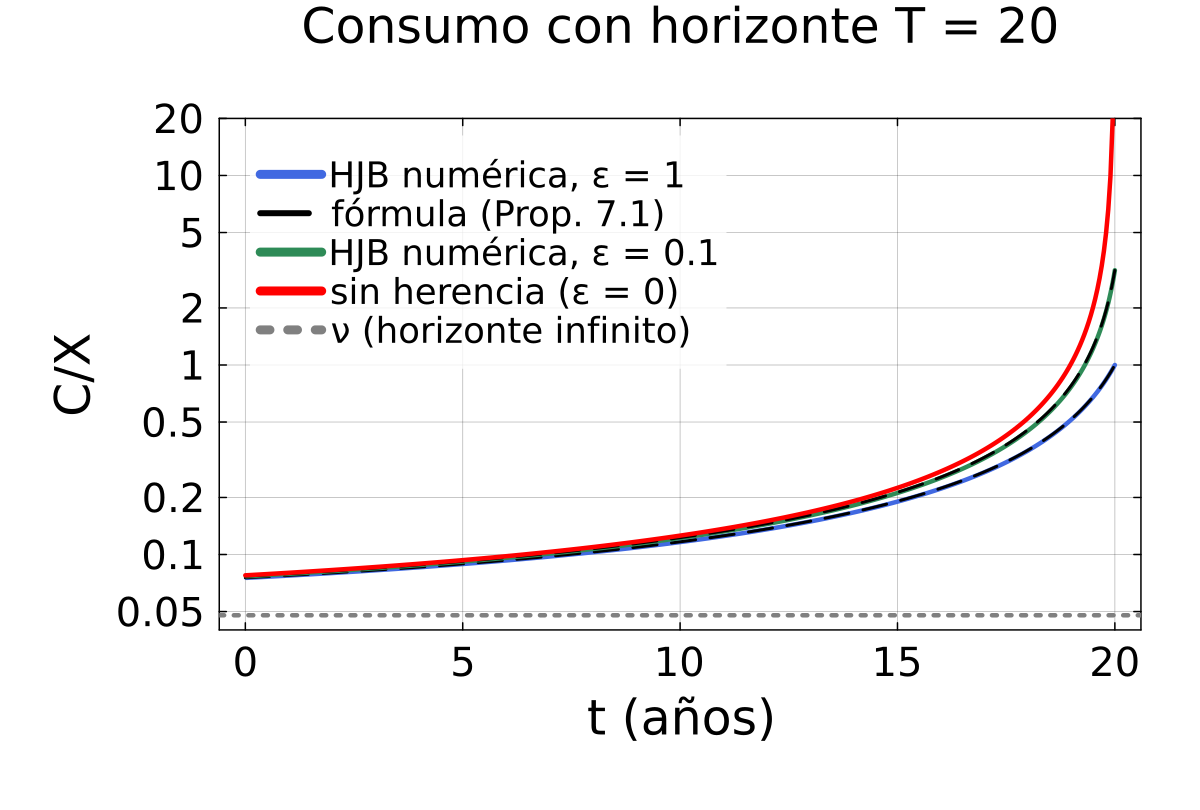

In [27]:
let T = 20.0, y = malla(801), tt = range(0, 20.0 - 1e-3, length=400)
    pe = plot(xlabel="t (años)", ylabel="C/X", title="Consumo con horizonte T = 20", yscale=:log10,
              ylims=(0.04, 20), legend=:topleft,
              yticks=([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20], ["0.05", "0.1", "0.2", "0.5", "1", "2", "5", "10", "20"]))
    for (eps, col, txt) in [(1.0, :royalblue, "1"), (0.1, :seagreen, "0.1")]
        s = resolver_finito(y, T, 800; eps=eps)
        plot!(pe, T .- s.s, s.e_x0, color=col, label="HJB numérica, ε = $txt")
        plot!(pe, tt, 1 ./ L.(T .- tt, eps), color=:black, ls=:dash, lw=2, label=(eps == 1.0 ? "fórmula (Prop. 7.1)" : false))
    end
    plot!(pe, tt, 1 ./ L.(T .- tt, 0.0), color=:red, label="sin herencia (ε = 0)")
    hline!(pe, [nu], color=:gray, ls=:dot, label="ν (horizonte infinito)")
    guardar(pe, "horizonte_consumo")
end

El esquema converge con orden 1 a la Prop. 7.1 y la fracción numérica es $\Pi^*=0.625$. La tasa de consumo numérica sigue a $1/L(T-t)$: sube lentamente durante casi todo el horizonte y se dispara en los últimos años. Sin herencia, el inversionista se consume todo antes de $T$. Incluso al inicio se consume más que en horizonte infinito (0.075 frente a $\nu=0.048$), porque hay menos años entre los que repartir el capital.

### 7.3 El horizonte como parámetro

T =  10: V(0,x0) sin herencia =   7.2375, con herencia =   7.7417  (infinito: 15.6256);  C/X inicial = 0.1258 / 0.1167  (nu = 0.0478)
T =  30: V(0,x0) sin herencia =  12.9992, con herencia =  13.1458  (infinito: 15.6256);  C/X inicial = 0.0628 / 0.0618  (nu = 0.0478)
T =  60: V(0,x0) sin herencia =  15.1124, con herencia =  15.1398  (infinito: 15.6256);  C/X inicial = 0.0507 / 0.0505  (nu = 0.0478)
T = 100: V(0,x0) sin herencia =  15.5639, con herencia =  15.5672  (infinito: 15.6256);  C/X inicial = 0.0482 / 0.0482  (nu = 0.0478)


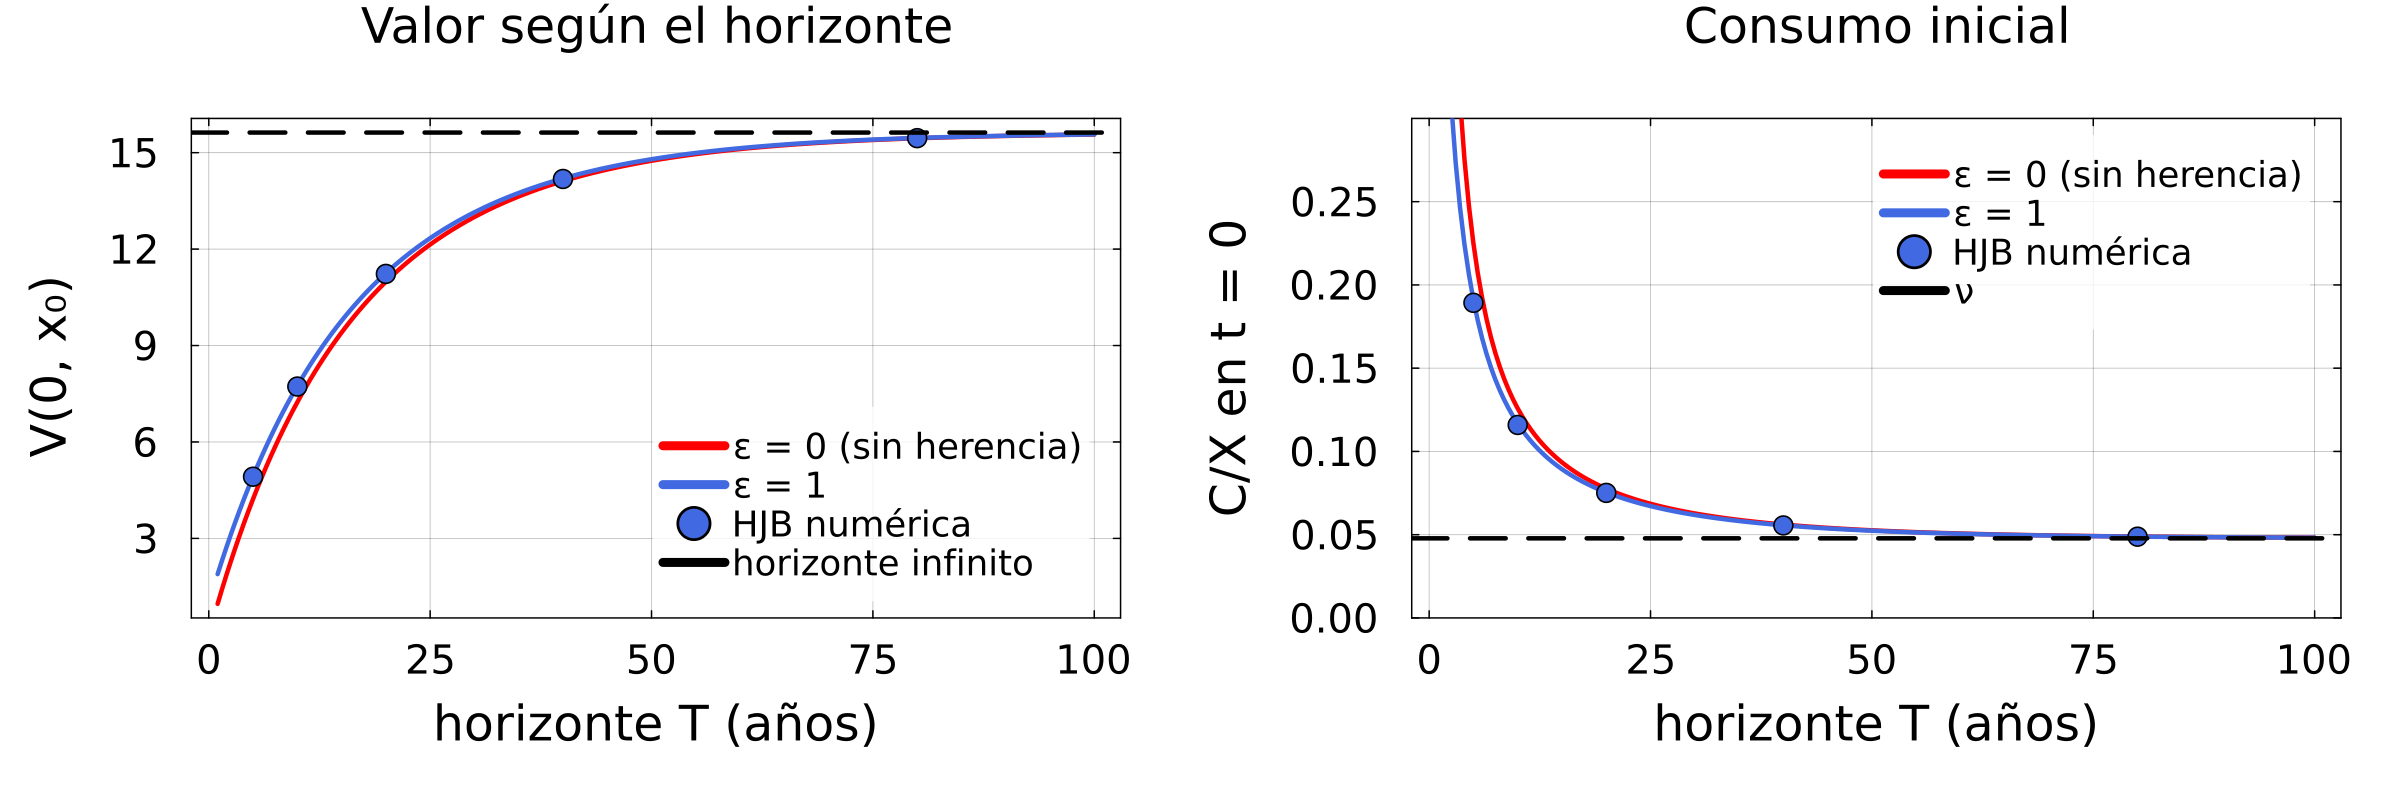

In [28]:
let Ts = range(1, 100, length=200), Tnum = [5.0, 10.0, 20.0, 40.0, 80.0]
    pv = plot(xlabel="horizonte T (años)", ylabel="V(0, x₀)", title="Valor según el horizonte", legend=:bottomright)
    pc = plot(xlabel="horizonte T (años)", ylabel="C/X en t = 0", title="Consumo inicial", legend=:topright, ylims=(0, 0.3))
    for (eps, col, txt) in [(0.0, :red, "ε = 0 (sin herencia)"), (1.0, :royalblue, "ε = 1")]
        plot!(pv, Ts, VT.(Ts, par.x0, eps), color=col, label=txt)
        plot!(pc, Ts, 1 ./ L.(Ts, eps), color=col, label=txt)
    end
    Wnum = [resolver_finito(malla(401), Tn, round(Int, 20Tn); eps=1.0) for Tn in Tnum]
    scatter!(pv, Tnum, [w.W[201] for w in Wnum], color=:royalblue, label="HJB numérica")
    scatter!(pc, Tnum, [w.e[201] for w in Wnum], color=:royalblue, label="HJB numérica")
    hline!(pv, [V(par.x0)], color=:black, ls=:dash, label="horizonte infinito")
    hline!(pc, [nu], color=:black, ls=:dash, label="ν")
    for Tn in [10, 30, 60, 100]
        @printf("T = %3d: V(0,x0) sin herencia = %8.4f, con herencia = %8.4f  (infinito: %.4f);  C/X inicial = %.4f / %.4f  (nu = %.4f)\n",
                Tn, VT(Tn, par.x0, 0.0), VT(Tn, par.x0, 1.0), V(par.x0), 1/L(Tn, 0.0), 1/L(Tn, 1.0), nu)
    end
    guardar(pv, "horizonte_valor"); guardar(pc, "horizonte_consumo_inicial")
    plot(pv, pc, layout=(1, 2), size=(1600, 540))
end

El horizonte importa mucho y por mucho tiempo: $L(s)$ se acerca a $1/\nu$ como $e^{-\nu s}$, con $1/\nu\approx21$ años, así que hacen falta unos $3/\nu\approx60$ años para que el horizonte deje de importar. La herencia aumenta el valor y baja el consumo inicial, pero su efecto desaparece en horizontes largos.

### 7.4 Tiempo de parada aleatorio: vida incierta

El sistema se detiene en $\tau\sim\text{Exp}(\lambda)$ independiente del browniano (la muerte del inversionista, con esperanza $1/\lambda$ años), y en $\tau$ se deja una herencia $\varepsilon\,U(X_\tau)$.

**Proposición 7.3.** $J=\mathbb E_x\int_0^\infty e^{-(\gamma+\lambda)t}\big[U(C_t)+\lambda\varepsilon\,U(X_t)\big]dt$: **sin herencia** es el problema de horizonte infinito con descuento $\gamma+\lambda$, y con herencia se agrega el término $\lambda\varepsilon U(X_t)$. La solución es $\Pi^*$ (sin cambios), $C^*=X/L_\lambda$ y
$$
V(x)=\frac{L_\lambda^\eta x^{1-\eta}}{1-\eta}-\frac{1+\lambda\varepsilon}{(1-\eta)(\gamma+\lambda)},
$$
donde $L_\lambda>0$ resuelve $\eta\nu_\lambda L^\eta-\eta L^{\eta-1}-\lambda\varepsilon=0$ con $\nu_\lambda=\nu+\frac\lambda\eta$. Sin herencia, $L_\lambda=1/\nu_\lambda$.

*Demostración.* Por independencia y Fubini, $\mathbb E\int_0^\tau f(t)dt=\int_0^\infty e^{-\lambda t}f(t)dt$ y $\mathbb E[e^{-\gamma\tau}U(X_\tau)]=\int_0^\infty\lambda e^{-(\gamma+\lambda)t}\mathbb E[U(X_t)]dt$. La HJB es la de Merton con $\gamma+\lambda$ y el término extra $\lambda\varepsilon U(x)$; el ansatz $V=\frac{A}{1-\eta}x^{1-\eta}+K$ con $A=L^\eta$ da las dos ecuaciones del enunciado. $\blacksquare$

El riesgo de morir hace al inversionista más **impaciente**: consume más ($\nu_\lambda>\nu$), y la herencia modera ese efecto. Lo validamos simulando directamente el tiempo de parada.

In [29]:
# L_lambda de la Prop. 7.3 por bisección
function L_exp(lam, eps; P=par)
    nul = nustar(P) + lam/P.eta
    f(Lv) = P.eta*nul*Lv^P.eta - P.eta*Lv^(P.eta - 1) - lam*eps
    a, b = 1e-6, 1e4
    for _ in 1:200
        m = (a + b)/2
        f(m) > 0 ? (b = m) : (a = m)
    end
    return (a + b)/2
end
V_exp(x, lam, eps; P=par) = L_exp(lam, eps; P=P)^P.eta*x^(1 - P.eta)/(1 - P.eta) - (1 + lam*eps)/((1 - P.eta)*(P.gamma + lam))

# Monte-Carlo con tau ~ Exp(lam): utilidad hasta tau (trapecio y último tramo parcial) + herencia en tau
function mc_exponencial(lam, eps; N=20_000, h=1/52, semilla=1, P=par)
    rng = Xoshiro(semilla)
    Lx = L_exp(lam, eps; P=P)
    a = P.r + Pim*(P.mu - P.r) - 1/Lx - 0.5*P.sigma^2*Pim^2     # deriva de log X con (Pi*, X/L)
    Y = zeros(N)
    for i in 1:N
        tau = randexp(rng)/lam
        lx, t, acc = log(P.x0), 0.0, 0.0
        while t + h <= tau
            f0 = exp(-P.gamma*t)*U(exp(lx)/Lx)
            lx += a*h + P.sigma*Pim*sqrt(h)*randn(rng)
            acc += h/2*(f0 + exp(-P.gamma*(t + h))*U(exp(lx)/Lx)); t += h
        end
        resto = tau - t                                          # tramo final [t, tau)
        acc += resto*exp(-P.gamma*t)*U(exp(lx)/Lx)
        lx += a*resto + P.sigma*Pim*sqrt(resto)*randn(rng)
        Y[i] = acc + eps*exp(-P.gamma*tau)*U(exp(lx))
    end
    return mean(Y), 1.96*std(Y)/sqrt(N)
end

println("vida esperada  herencia   C/X = 1/L    V exacto   Monte-Carlo +- IC95   (50 000 trayectorias)")
for (j, (lam, eps)) in enumerate([(l, e) for l in [1/50, 1/30, 1/10] for e in [0.0, 1.0, 5.0]])
    m, s = mc_exponencial(lam, eps; N=50_000, semilla=j)
    @printf("%8.0f años %8.1f %11.5f %11.4f %11.4f +- %.4f\n", 1/lam, eps, 1/L_exp(lam, eps), V_exp(par.x0, lam, eps), m, s)
end
@printf("(sin riesgo de muerte: C/X = nu = %.5f, V(x0) = %.4f)\n", nu, V(par.x0))

vida esperada  herencia   C/X = 1/L    V exacto   Monte-Carlo +- IC95   (50 000 trayectorias)
      50 años      0.0     0.05781     11.2937     11.2943 +- 0.0412
      50 años      1.0     0.05778     11.5760     11.5418 +- 0.0389
      50 años      5.0     0.05765     12.7050     12.7075 +- 0.0294
      30 años      0.0     0.06448      9.5947      9.6176 +- 0.0419
      30 años      1.0     0.06441      9.9896      9.9950 +- 0.0393
      30 años      5.0     0.06414     11.5690     11.5485 +- 0.0296
      10 años      0.0     0.09781      5.6214      5.6051 +- 0.0332
      10 años      1.0     0.09734      6.2779      6.2611 +- 0.0312
      10 años      5.0     0.09553      8.9042      8.9007 +- 0.0232
(sin riesgo de muerte: C/X = nu = 0.04781, V(x0) = 15.6256)


Los nueve casos coinciden con la Prop. 7.3 dentro del intervalo de confianza. Con una vida esperada de 30 años la tasa de consumo sube de $\nu=0.048$ a 0.064, y con 10 años a casi 0.098. La fracción invertida es siempre $\Pi^*=0.625$: el riesgo de morir no hace al inversionista más conservador, solo más impaciente.

### 7.5 Tiempo de parada que depende del capital: piso de liquidación

Si el capital cae a un piso $x_\ell<x_0$, el inversionista es obligado a liquidar la acción y desde ese momento solo usa el banco: $\tau=\inf\{t:X_t\le x_\ell\}$, y después de $\tau$ obtiene $\Psi$, el valor de "solo banco" (Sección 1). El problema es
$$
V_\ell(x)=\sup\mathbb E_x\Big[\int_0^\tau e^{-\gamma t}U(C_t)dt+e^{-\gamma\tau}\Psi(X_\tau)\Big],
$$
y su HJB es la de siempre en $x>x_\ell$. **El piso rompe la homotecia:** al escalar el capital se escala también la distancia al piso, así que el control óptimo deja de ser constante y no hay solución explícita.

**Condición de borde en el piso.** En $x=x_\ell$ se liquida ($\tau=0$), pero desde $x>x_\ell$ el inversionista puede **evitar** el piso para siempre con $\Pi=0$ y $C\le rX$: la deriva es $\ge0$ y no hay difusión. Por eso el límite $V_\ell(x_\ell^+)$ puede ser mayor que $\Psi(x_\ell)$, y la condición de Dirichlet $V_\ell(x_\ell)=\Psi(x_\ell)$ no es la correcta. En el nodo del piso usamos la mejor de dos opciones:
$$
V_\ell(x_\ell^+)=\max\Big\{\Psi(x_\ell),\ \text{valor de quedarse encima}\Big\},\qquad \text{quedarse: }\ \gamma V=\sup_{0\le e\le r}\big\{U(e\,x_\ell)+(r-e)\,\partial_yV\big\},
$$
que es una condición de **restricción de estado** (solo se permiten controles que no sacan al capital del dominio). En el esquema, "quedarse" es la fila *upwind* hacia adelante con $\Pi=0$, sin difusión. En el borde derecho seguimos usando la homotecia como aproximación (lejos del piso el problema se parece al de Merton). Siempre $\Psi\le V_\ell\le V$.

Como el control cambia bruscamente cerca del piso, el error de malla es mayor que en la Sección 5: evaluamos $V_\ell(x_0)$ interpolando (no en el nodo más cercano) y refinamos la malla.

In [30]:
# HJB estacionaria en [log xl, log xmax]. En el piso: liquidar (V = Psi) o quedarse encima con Pi = 0 y e <= r,
# lo que sea mejor. En el borde derecho: homotecia.
function resolver_piso(xl; n=3201, xmax=1e4, P=par, tol=1e-11, maxit=300)
    y = collect(range(log(xl), log(xmax), length=n)); k = y[2] - y[1]; x = exp.(y)
    Pi = zeros(n); e = fill(P.r, n); e[1] = P.r; W = zeros(n)
    quedarse = true                                                    # se parte quedándose encima del piso
    for it in 1:maxit
        dl, d, du, b, a = sistema_upwind(Pi, e, k; P=P)
        rhs = U.(e .* x; P=P)
        if !quedarse                                                   # liquidar: Dirichlet V = Psi
            du[1] = 0.0; d[1] = 1.0; rhs[1] = Psi(x[1]; P=P)
        end                                                            # quedarse: fila upwind con Pi = 0, e <= r
        dl[n] = 0.0; du[n] = 0.0; d[n] = kappa(Pi[n], e[n]; P=P)       # borde derecho: homotecia
        rhs[n] = U(e[n]*x[n]; P=P) + (b[n] + (1 - P.eta)*a[n])/P.gamma
        Wn = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
        Pi, e = politica(Wn, y, 1/P.gamma; P=P)
        # nodo del piso: solo Pi = 0 y e <= r mantienen X >= xl (la homotecia no vale aquí)
        W1p = max((Wn[2] - Wn[1])/k, 1e-12)
        e[1] = min((x[1]^(1 - P.eta)/W1p)^(1/P.eta), P.r); Pi[1] = 0.0
        quedarse = (U(e[1]*x[1]; P=P) + (P.r - e[1])*Wn[2]/k)/(P.gamma + (P.r - e[1])/k) > Psi(x[1]; P=P)
        cambio = maximum(abs.(Wn .- W))/maximum(abs.(Wn)); W = Wn
        cambio < tol && it > 2 && break
    end
    return (W=W, Pi=Pi, e=e, x=x, y=y, quedarse=quedarse)
end

# interpolación lineal en la malla uniforme y
interp_y(yq, y, v) = (k = y[2] - y[1]; j = clamp(floor(Int, (yq - y[1])/k) + 1, 1, length(y) - 1);
                      a = (yq - y[j])/k; (1 - a)*v[j] + a*v[j+1])
valor_en_x0(s; P=par) = interp_y(log(P.x0), s.y, s.W)
xCE_piso(s) = xCE(valor_en_x0(s))

xCE_piso (generic function with 1 method)

In [31]:
const pisos = [20.0, 50.0, 80.0]
println("Refinamiento de malla: capital equivalente en x0 (V_l(x0) interpolado)")
@printf("%6s %s\n", "piso", join([@sprintf("%9s", "n=$n") for n in [801, 1601, 3201, 6401]]))
for xl in pisos
    @printf("%6.0f %s\n", xl, join([@sprintf("%9.2f", xCE_piso(resolver_piso(xl; n=n))) for n in [801, 1601, 3201, 6401]]))
end

sols_piso = Dict(xl => resolver_piso(xl; n=6401) for xl in pisos)
@printf("\n%6s %10s %8s %9s %10s %12s %12s\n", "piso", "V_l(x0)", "xCE", "Pi(x0)", "C/X(x0)", "V_l(piso+)", "Psi(piso)")
for xl in pisos
    s = sols_piso[xl]
    @printf("%6.0f %10.4f %8.2f %9.4f %10.4f %12.4f %12.4f   %s\n", xl, valor_en_x0(s), xCE_piso(s),
            interp_y(log(par.x0), s.y, s.Pi), interp_y(log(par.x0), s.y, s.e), s.W[1], Psi(xl),
            s.quedarse ? "en el piso conviene quedarse encima" : "en el piso conviene liquidar")
end
@printf("(Merton: V = %.4f, Pi* = %.3f, nu = %.4f;  solo banco: Psi(x0) = %.4f)\n", V(par.x0), Pim, nu, Psi(par.x0))

Refinamiento de malla: capital equivalente en x0 (V_l(x0) interpolado)
  piso     n=801   n=1601   n=3201   n=6401
    20     99.08    99.12    99.14    99.15
    50     94.67    94.77    94.82    94.84
    80     85.34    85.55    85.66    85.72

  piso    V_l(x0)      xCE    Pi(x0)    C/X(x0)   V_l(piso+)    Psi(piso)
    20    15.5879    99.15    0.6102     0.0472     -10.1762     -11.2500   en el piso conviene quedarse encima
    50    15.3877    94.84    0.5340     0.0442       7.9351       7.5000   en el piso conviene quedarse encima
    80    14.8968    85.72    0.3647     0.0374      12.4612      12.1875   en el piso conviene quedarse encima
(Merton: V = 15.6256, Pi* = 0.625, nu = 0.0478;  solo banco: Psi(x0) = 13.7500)


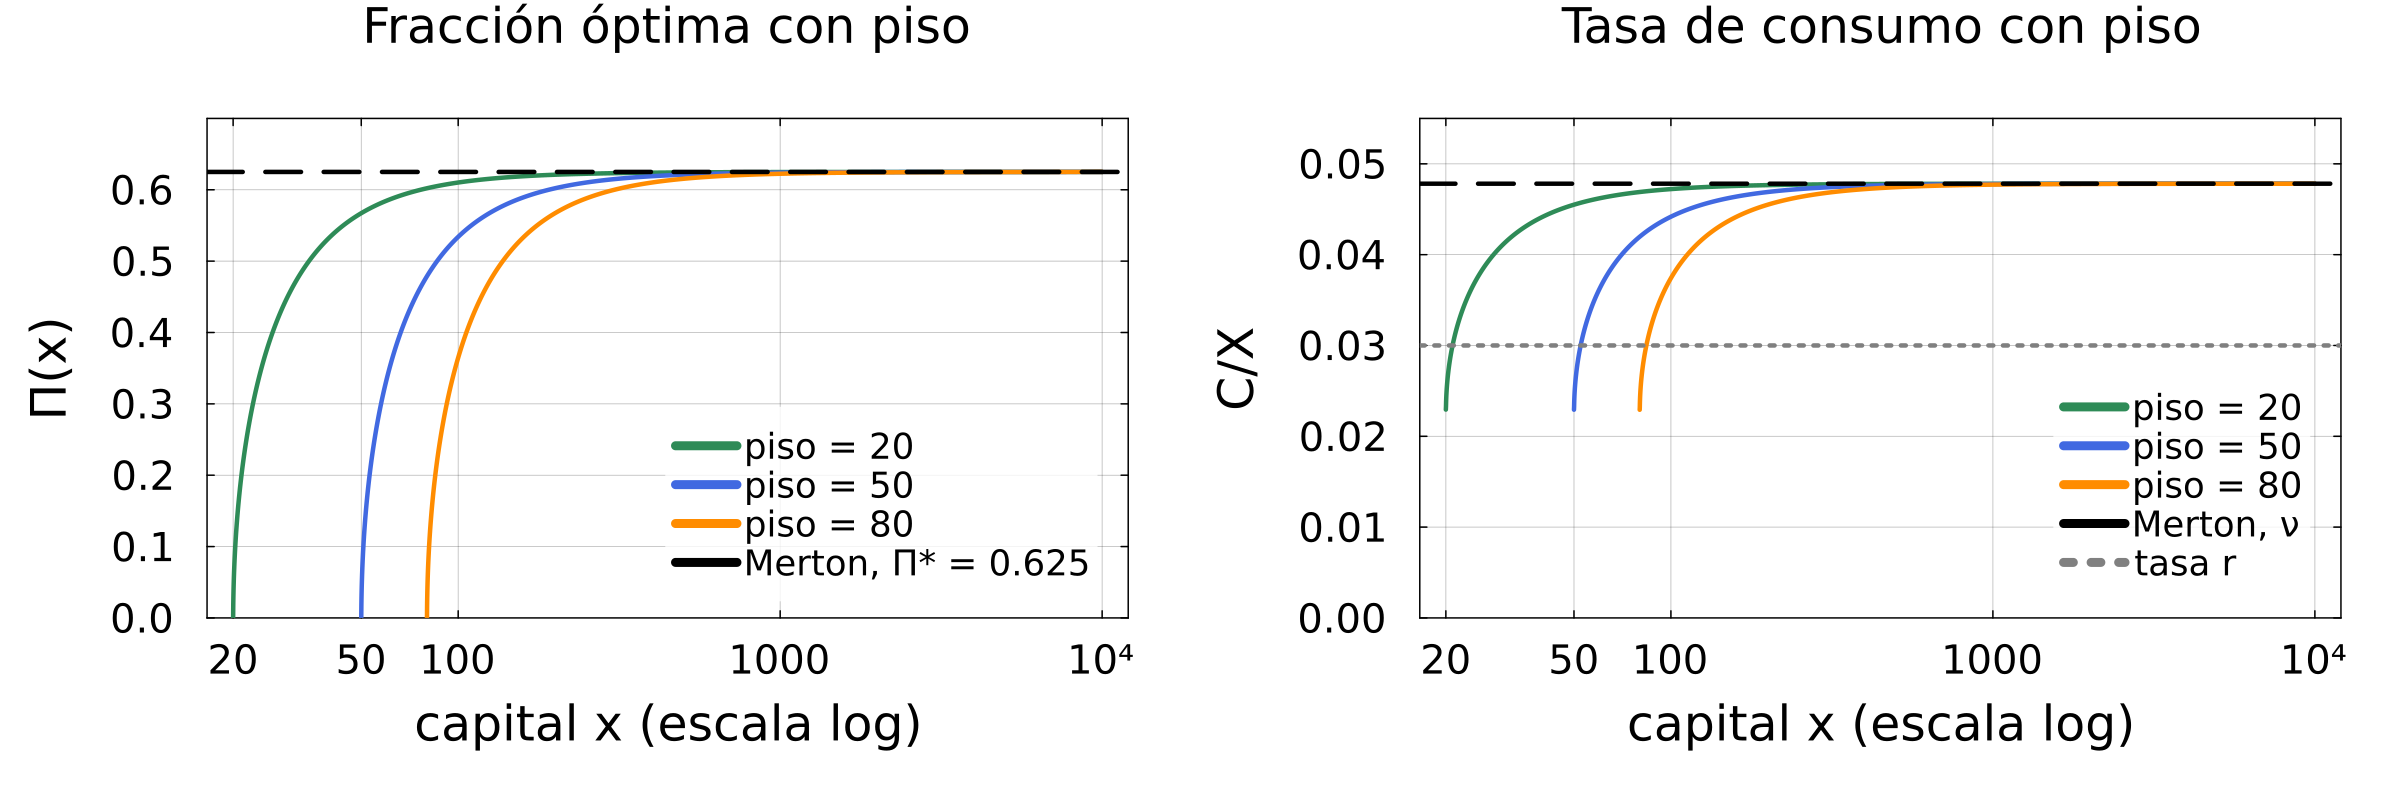

In [32]:
let ejex = ([20, 50, 100, 1000, 10000], ["20", "50", "100", "1000", "10⁴"])
    q1 = plot(xlabel="capital x (escala log)", ylabel="Π(x)", title="Fracción óptima con piso", xscale=:log10,
              legend=:bottomright, ylims=(0, 0.7), xticks=ejex)
    q2 = plot(xlabel="capital x (escala log)", ylabel="C/X", title="Tasa de consumo con piso", xscale=:log10,
              legend=:bottomright, ylims=(0, 0.055), xticks=ejex)
    for (xl, col) in zip(pisos, [:seagreen, :royalblue, :darkorange])
        s = sols_piso[xl]
        plot!(q1, s.x, s.Pi, color=col, label="piso = $(Int(xl))")
        plot!(q2, s.x, s.e, color=col, label="piso = $(Int(xl))")
    end
    hline!(q1, [Pim], color=:black, ls=:dash, label="Merton, Π* = 0.625")
    hline!(q2, [nu], color=:black, ls=:dash, label="Merton, ν")
    hline!(q2, [par.r], color=:gray, ls=:dot, label="tasa r")
    guardar(q1, "piso_fraccion"); guardar(q2, "piso_consumo")
    plot(q1, q2, layout=(1, 2), size=(1600, 540))
end

El piso cambia el control: lejos del piso el inversionista actúa como Merton, pero al acercarse **reduce la fracción invertida a cero** y **consume menos que la tasa de interés** $r$, así que el capital crece en forma casi determinista y se aleja de la liquidación. En el piso mismo prefiere quedarse encima antes que liquidar ($V_\ell(x_\ell^+)>\Psi(x_\ell)$), lo que confirma que la condición de Dirichlet no era la correcta. Cuanto más alto el piso, más se nota desde $x_0$.

**Verificación por simulación.** Simulamos el capital con el control numérico (interpolado entre nodos) para $x_\ell=50$, con paso diario; si una trayectoria toca el piso se detiene y suma $e^{-\gamma\tau}\Psi(x_\ell)$, y a las que no lo tocan en 100 años les sumamos $e^{-\gamma T}V_\ell(X_T)$. Si la solución numérica es correcta, el promedio debe reproducir $V_\ell(x_0)$. También medimos qué fracción de trayectorias toca el piso según el paso de simulación.

In [33]:
function mc_piso(s, xl; N=5_000, h=1/52, Tsim=100.0, semilla=8, P=par)
    rng = Xoshiro(semilla); K = round(Int, Tsim/h)
    Y = zeros(N); tocan = 0
    for i in 1:N
        x, acc, parado = P.x0, 0.0, false
        f0 = U(interp_y(log(x), s.y, s.e)*x)
        for k in 1:K
            ly = log(x); Pi = interp_y(ly, s.y, s.Pi); e = interp_y(ly, s.y, s.e)
            x *= exp((P.r + Pi*(P.mu - P.r) - e - 0.5*P.sigma^2*Pi^2)*h + P.sigma*Pi*sqrt(h)*randn(rng))
            if x <= xl                                           # toca el piso: liquidación en X_tau = xl
                acc += h/2*f0 + exp(-P.gamma*k*h)*Psi(xl); parado = true; tocan += 1
                break
            end
            f1 = exp(-P.gamma*k*h)*U(interp_y(log(x), s.y, s.e)*x)
            acc += h/2*(f0 + f1); f0 = f1
        end
        parado || (acc += exp(-P.gamma*K*h)*interp_y(log(x), s.y, s.W))
        Y[i] = acc
    end
    return mean(Y), 1.96*std(Y)/sqrt(N), tocan/N
end

let s = sols_piso[50.0]
    m, semi, frac = mc_piso(s, 50.0; h=1/252)
    @printf("piso 50, paso diario: Monte-Carlo = %.4f +- %.4f   vs   V_l(x0) numérico = %.4f\n", m, semi, valor_en_x0(s))
    println("fracción de trayectorias que toca el piso en 100 años:")
    for (nombre, h) in [("mensual", 1/12), ("semanal", 1/52), ("diario", 1/252)]
        @printf("  paso %-8s %.4f\n", nombre, nombre == "diario" ? frac : mc_piso(s, 50.0; h=h)[3])
    end
end

piso 50, paso diario: Monte-Carlo = 15.4152 +- 0.0474   vs   V_l(x0) numérico = 15.3877
fracción de trayectorias que toca el piso en 100 años:
  paso mensual  0.1534
  paso semanal  0.1254
  paso diario   0.0026


La simulación reproduce el valor numérico dentro del intervalo de confianza. La fracción de trayectorias que toca el piso baja al achicar el paso: cerca del piso la difusión se anula y la deriva es positiva, así que en tiempo continuo el control óptimo evita el piso, y los toques son un efecto de la discretización (con un paso grande, un solo salto puede cruzar el piso).

**Conclusiones de la Sección 7.**
1. Con horizonte finito el control óptimo sigue siendo $\Pi^*$ constante, pero la tasa de consumo $1/L(T-t)$ crece hacia $T$, y sin herencia explota como $1/(T-t)$. La HJB parabólica numérica converge a la solución explícita con orden 1.
2. El horizonte es un parámetro relevante: el problema se parece al de horizonte infinito solo cuando $T\gtrsim3/\nu\approx60$ años.
3. Un tiempo de parada exponencial independiente equivale (sin herencia) a aumentar el descuento a $\gamma+\lambda$: no cambia la fracción invertida y aumenta el consumo.
4. Un piso de liquidación rompe la homotecia: el control deja de ser constante y solo se obtiene numéricamente. Cerca del piso conviene no invertir y consumir menos que el interés, y el inversionista evita tocarlo.

**Pendientes.** Parada **óptima** (que el inversionista elija $\tau$, un problema de frontera libre); combinar horizonte finito y piso.

## 8. Extensiones (objetivo 8)

| Extensión del enunciado | Dónde |
| --- | --- |
| Múltiples activos riesgosos | 8.1 |
| $\mu(t)$ y $\sigma(t)$ no autónomos | 8.2 |
| Cambio de $\Pi_t$ acotado en el tiempo | 8.3 |
| Costos de transacción | 8.4 |
| Tiempo finito como parámetro modificable | 7.1 a 7.3 |

En las tres primeras, la homotecia de la CRRA reduce el problema a una fórmula o una EDO, y validamos con Monte-Carlo. Los costos de transacción conservan la homotecia, pero el control óptimo es de tipo banda (singular) y no tiene fórmula cerrada: comparamos estrategias por simulación.

### 8.1 Varios activos riesgosos

Hay $n$ acciones con retornos medios $\mu\in\mathbb R^n$ y covarianza $\Sigma$ ($\Sigma_{ij}=\rho_{ij}\sigma_i\sigma_j$). Con fracciones $\Pi_t\in\mathbb R^n$,
$$
dX_t=\big[(r+\Pi_t^\top(\mu-r\mathbf 1))X_t-C_t\big]dt+X_t\,\Pi_t^\top\mathrm{diag}(\sigma)\,dW_t .
$$

**Proposición 8.1 (fondos mutuos).** Sea $\theta^2=(\mu-r\mathbf 1)^\top\Sigma^{-1}(\mu-r\mathbf 1)$. El control óptimo es $\Pi^*=\frac1\eta\,\Sigma^{-1}(\mu-r\mathbf 1)$, $C^*=\nu X$, con $\nu$ y $V$ dados por las fórmulas de un activo con este $\theta^2$. La **dirección** $\Pi^*/\sum_i\Pi^*_i$ no depende de $\eta$ (separación en dos fondos).

*Demostración.* La HJB tiene el término $\sup_\Pi\big\{\Pi^\top(\mu-r\mathbf 1)\,xV'+\frac12x^2\,\Pi^\top\Sigma\Pi\,V''\big\}$, cóncavo en $\Pi$ si $V''<0$, con máximo en $\Pi=-\frac{V'}{xV''}\Sigma^{-1}(\mu-r\mathbf 1)$ y valor $-\frac{(V')^2}{2V''}\theta^2$: el mismo del caso de un activo. El ansatz da la misma $V$ con el nuevo $\theta^2$, y $-\frac{V'}{xV''}=\frac1\eta$. $\blacksquare$

In [34]:
# tasa de consumo y valor de Merton como funciones de theta^2 (sirven con varios activos)
nu_de(th2; P=par) = (P.gamma - (1 - P.eta)*(P.r + th2/(2*P.eta)))/P.eta
Vde(x, th2; P=par) = (nu_de(th2; P=P)^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)

# tres acciones: la del proyecto, una más rentable y volátil, y una más defensiva
const mu_n  = [0.08, 0.10, 0.06]
const sig_n = [0.20, 0.30, 0.15]
const Rho_n = [1.0 0.5 0.3; 0.5 1.0 0.2; 0.3 0.2 1.0]
const Sig_n = (sig_n * sig_n') .* Rho_n
const exc_n = mu_n .- par.r
const Pi_n  = (Sig_n \ exc_n) ./ par.eta
const th2_n = exc_n' * (Sig_n \ exc_n)

@printf("Pi* = %s  (total en acciones %.3f)\ntheta^2 = %.4f (un activo: %.4f)   nu = %.5f   V(x0) = %.4f   xCE = %.2f\n\n",
        round.(Pi_n, digits=3), sum(Pi_n), th2_n, theta()^2, nu_de(th2_n), Vde(par.x0, th2_n), xCE(Vde(par.x0, th2_n)))

println("separación en dos fondos: la dirección no depende de eta")
for eta in [1.5, 2.0, 5.0]
    p = (Sig_n \ exc_n) ./ eta
    println("  eta = $eta: Pi* = ", round.(p, digits=3), "   dirección = ", round.(p ./ sum(p), digits=3))
end

# valor de una cartera fija w con su consumo óptimo (Prop. 6.1 con varios activos)
function valor_cartera(w; P=par)
    rho_w = P.r + w' * exc_n - 0.5*P.eta*(w' * Sig_n * w)
    nu_w = (P.gamma + (P.eta - 1)*rho_w)/P.eta
    return (nu_w^(-P.eta)*P.x0^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)
end
println("\ncartera                                  V(x0)     xCE")
for (nombre, w) in [("óptima (Prop. 8.1)", Pi_n), ("solo la acción 1 (Merton de un activo)", [Pim, 0, 0]),
                    ("1/n, mismo total que la óptima", fill(sum(Pi_n)/3, 3)), ("1/n, total 0.625", fill(Pim/3, 3))]
    @printf("%-40s %8.4f %7.2f\n", nombre, valor_cartera(w), xCE(valor_cartera(w)))
end

Pi* = [0.358, 0.226, 0.433]  (total en acciones 1.017)
theta^2 = 0.0934 (un activo: 0.0625)   nu = 0.05168   V(x0) = 16.2560   xCE = 116.84

separación en dos fondos: la dirección no depende de eta
  eta = 1.5: Pi* = [0.477, 0.302, 0.577]   dirección = [0.352, 0.222, 0.426]
  eta = 2.0: Pi* = [0.358, 0.226, 0.433]   dirección = [0.352, 0.222, 0.426]
  eta = 5.0: Pi* = [0.143, 0.091, 0.173]   dirección = [0.352, 0.222, 0.426]

cartera                                  V(x0)     xCE
óptima (Prop. 8.1)                        16.2560  116.84
solo la acción 1 (Merton de un activo)    15.6256  100.00
1/n, mismo total que la óptima            16.1772  114.43
1/n, total 0.625                          16.0369  110.38


In [35]:
# validación por Monte-Carlo: con fracciones constantes log X es gaussiano (simulación exacta),
# con el valor de continuación exacto V(X_T) como en la Sección 3
let N = 20_000, T = 30.0, h = 1/12
    Random.seed!(1)
    K = round(Int, T/h)
    Lc = cholesky(Rho_n).L
    c_n = nu_de(th2_n)
    a_n = par.r + Pi_n' * exc_n - c_n - 0.5*(Pi_n' * Sig_n * Pi_n)     # deriva de log X
    lX = fill(log(par.x0), N); Y = zeros(N)
    for k in 0:K-1
        Y .+= (k == 0 ? h/2 : h)*exp(-par.gamma*k*h) .* U.(c_n .* exp.(lX))
        dW = Lc * randn(3, N)                                          # brownianos correlacionados
        lX .+= a_n*h .+ sqrt(h) .* vec((Pi_n .* sig_n)' * dW)
    end
    Y .+= (h/2)*exp(-par.gamma*T) .* U.(c_n .* exp.(lX)) .+ exp(-par.gamma*T) .* Vde.(exp.(lX), th2_n)
    @printf("Monte-Carlo = %.4f +- %.4f   vs   V(x0) = %.4f\n", mean(Y), 1.96*std(Y)/sqrt(N), Vde(par.x0, th2_n))
end

Monte-Carlo = 16.2580 +- 0.0268   vs   V(x0) = 16.2560


Con tres acciones la fracción óptima reparte el riesgo, $\Pi^*=(0.36,\,0.23,\,0.43)$, y el inversionista queda como si tuviera 117 de capital en vez de 100: **diversificar vale un 17%**. La dirección del portafolio es la misma para todo $\eta$. El Monte-Carlo con brownianos correlacionados reproduce el valor exacto.

### 8.2 Retorno y volatilidad que cambian en el tiempo

$\mu(t)$ y $\sigma(t)$ son funciones **conocidas** del tiempo, con horizonte $T=30$ y herencia $\varepsilon=1$.

**Proposición 8.2.** Sea $\nu(t)=\frac1\eta\big[\gamma-(1-\eta)\big(r+\frac{\theta(t)^2}{2\eta}\big)\big]$ y $L$ la solución de $L'(t)=\nu(t)L(t)-1$, $L(T)=\varepsilon^{1/\eta}$. Entonces $V(t,x)=\frac{1}{1-\eta}\big(L(t)^\eta x^{1-\eta}-D(T-t)\big)$ y el control óptimo es $\Pi^*(t)=\frac{\mu(t)-r}{\eta\,\sigma(t)^2}$, $C^*_t=X_t/L(t)$.

*Demostración.* La misma cuenta de la Prop. 7.1: en cada instante el supremo en $\Pi$ se toma con los coeficientes de ese instante. $\blacksquare$

Resolvemos la EDO hacia atrás con Runge–Kutta 4, con un ciclo de 8 años en que la volatilidad es alta cuando el retorno es bajo: $\mu(t)=0.08+0.04\sin(2\pi t/8)$, $\sigma(t)=0.20-0.05\sin(2\pi t/8)$.

In [36]:
mu_t(t)  = 0.08 + 0.04*sin(2pi*t/8)
sig_t(t) = 0.20 - 0.05*sin(2pi*t/8)
Pi_t(t)  = (mu_t(t) - par.r)/(par.eta*sig_t(t)^2)
nu_t(t)  = nu_de(((mu_t(t) - par.r)/sig_t(t))^2)

# RK4 hacia atrás para L' = nu(t) L - 1 en [t0, T], con L(T) = LT; devuelve la malla y los valores
function L_rk4(nuf, t0, T, LT; M=20_000)
    ts = range(t0, T, length=M + 1); ds = step(ts)
    Ls = zeros(M + 1); Ls[end] = LT
    f(t, Lv) = nuf(t)*Lv - 1
    for j in M:-1:1
        t, Lv, hh = ts[j+1], Ls[j+1], -ds
        k1 = f(t, Lv); k2 = f(t + hh/2, Lv + hh/2*k1); k3 = f(t + hh/2, Lv + hh/2*k2); k4 = f(t + hh, Lv + hh*k3)
        Ls[j] = Lv + hh/6*(k1 + 2k2 + 2k3 + k4)
    end
    return ts, Ls
end
interp_t(ts, v, t) = (j = clamp(floor(Int, (t - ts[1])/step(ts)) + 1, 1, length(ts) - 1);
                      a = (t - ts[j])/step(ts); (1 - a)*v[j] + a*v[j+1])

const T_ciclo, eps_ciclo = 30.0, 1.0
const ts_ciclo, Ls_ciclo = L_rk4(nu_t, 0.0, T_ciclo, eps_ciclo^(1/par.eta))
const V0_ciclo = (Ls_ciclo[1]^par.eta*par.x0^(1 - par.eta) - D(T_ciclo, eps_ciclo))/(1 - par.eta)
xCE_ciclo(J) = (((1 - par.eta)*J + D(T_ciclo, eps_ciclo))/Ls_ciclo[1]^par.eta)^(1/(1 - par.eta))   # respecto del óptimo
@printf("V(0, x0) = %.4f;  Pi*(t) entre %.3f y %.3f;  C/X inicial = %.4f (con parámetros promedio: %.4f)\n",
        V0_ciclo, minimum(Pi_t.(ts_ciclo)), maximum(Pi_t.(ts_ciclo)), 1/Ls_ciclo[1], 1/L(T_ciclo, eps_ciclo))

V(0, x0) = 13.6536;  Pi*(t) entre 0.080 y 2.000;  C/X inicial = 0.0689 (con parámetros promedio: 0.0618)


óptimo (Prop. 8.2):   Monte-Carlo = 13.6660 +- 0.0157  vs  V(0,x0) = 13.6536
parámetros promedio:  Monte-Carlo = 13.2374 +- 0.0118  ->  xCE = 83.50 (exacto del óptimo: 100)
diferencia pareada:   0.4286 +- 0.0109


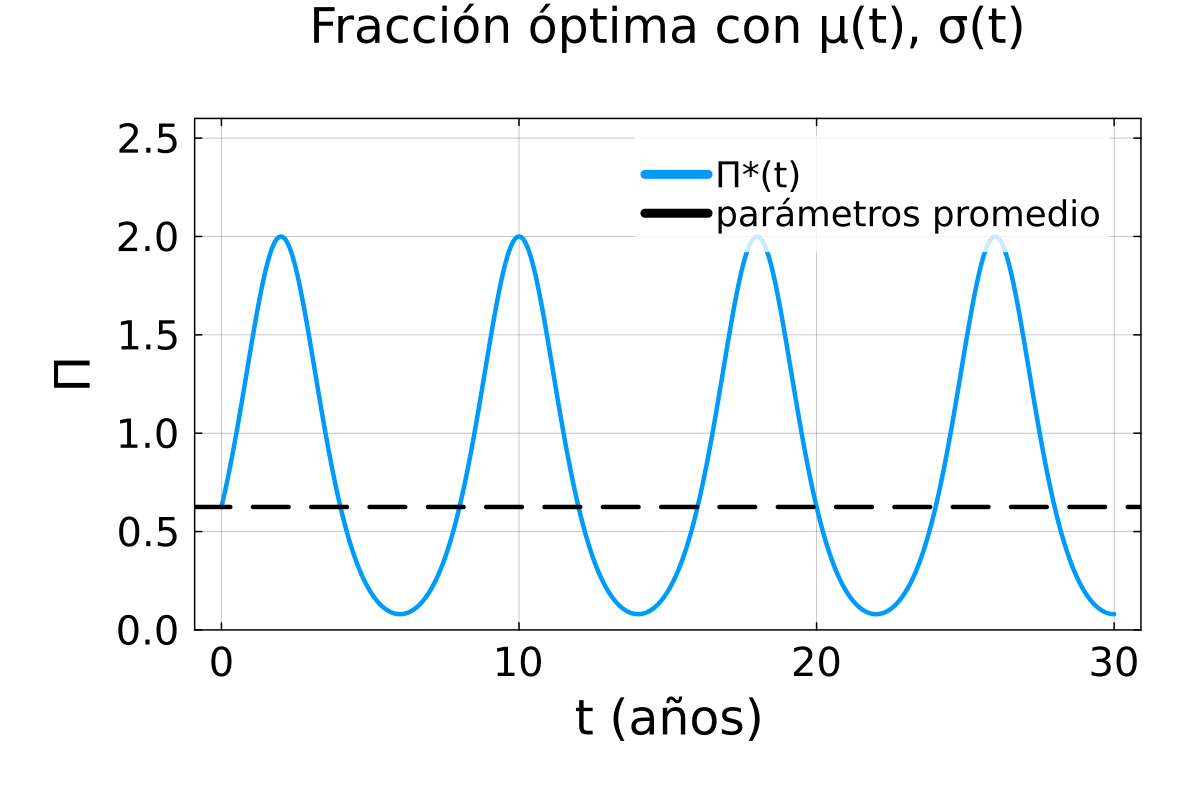

In [37]:
# Monte-Carlo con coeficientes congelados en cada paso diario; los dos inversionistas ven los mismos escenarios
function mc_tiempo(politica_t; N=20_000, h=1/252, semilla=2, P=par)
    rng = Xoshiro(semilla); K = round(Int, T_ciclo/h)
    lX = fill(log(P.x0), N); Y = zeros(N)
    for k in 0:K-1
        t = k*h; Pi, e = politica_t(t)
        Y .+= (k == 0 ? h/2 : h)*exp(-P.gamma*t) .* U.(e .* exp.(lX))
        lX .+= (P.r + Pi*(mu_t(t) - P.r) - e - 0.5*sig_t(t)^2*Pi^2)*h .+ sig_t(t)*Pi*sqrt(h) .* randn(rng, N)
    end
    Pi, e = politica_t(T_ciclo)
    return Y .+ (h/2)*exp(-P.gamma*T_ciclo) .* U.(e .* exp.(lX)) .+ eps_ciclo*exp(-P.gamma*T_ciclo) .* U.(exp.(lX))
end

let
    Y_opt = mc_tiempo(t -> (Pi_t(t), 1/interp_t(ts_ciclo, Ls_ciclo, t)))
    Y_cte = mc_tiempo(t -> (Pim, 1/L(T_ciclo - t, eps_ciclo)))
    d = Y_opt .- Y_cte; N = length(d)
    @printf("óptimo (Prop. 8.2):   Monte-Carlo = %.4f +- %.4f  vs  V(0,x0) = %.4f\n", mean(Y_opt), 1.96*std(Y_opt)/sqrt(N), V0_ciclo)
    @printf("parámetros promedio:  Monte-Carlo = %.4f +- %.4f  ->  xCE = %.2f (exacto del óptimo: 100)\n",
            mean(Y_cte), 1.96*std(Y_cte)/sqrt(N), xCE_ciclo(mean(Y_cte)))
    @printf("diferencia pareada:   %.4f +- %.4f\n", mean(d), 1.96*std(d)/sqrt(N))
    tt = range(0, T_ciclo, length=600)
    pv1 = plot(tt, Pi_t.(tt), label="Π*(t)", xlabel="t (años)", ylabel="Π", title="Fracción óptima con μ(t), σ(t)",
               legend=:topright, ylims=(0, 2.6))
    hline!(pv1, [Pim], ls=:dash, color=:black, label="parámetros promedio")
    guardar(pv1, "ciclo_fraccion")
end

La fracción óptima sigue al ciclo: va de 0.08, cuando el retorno es bajo y la volatilidad alta, a 2.0 en la fase buena. Un inversionista que usa los parámetros promedio con la fórmula de Merton constante queda como si tuviera unos 83 de capital: conocer el ciclo vale cerca de un 17%. Pero esto supone que el ciclo se **conoce**; la Sección 4 mostró que seguirlo con el filtro de Kalman es casi imposible con $\sigma=0.2$.

### 8.3 Cambios acotados de la fracción invertida

La fracción no se puede cambiar de golpe: $\frac{d\Pi_t}{dt}=u_t$ con $|u_t|\le L_\Pi$, partiendo de $\Pi_0=0$.

**Proposición 8.3.** Con $\rho$ de la Sección 1 (cóncava, con máximo en $\Pi^*$):
1. Por homotecia, $V(x,\Pi)=\frac{A(\Pi)}{1-\eta}x^{1-\eta}+K$, así que el control $u$ óptimo depende solo de $\Pi$ y el camino $\Pi(t)$ es **determinista**.
2. Para un camino determinista $\Pi(t)$, el valor es $\frac{1}{1-\eta}\big(L(0)^\eta x^{1-\eta}-\frac1\gamma\big)$, con $L'=\nu(t)L-1$, $\nu(t)=\nu(\Pi(t))$, y el consumo óptimo es $C=X/L(t)$.
3. El camino óptimo es ir **lo más rápido posible** hacia $\Pi^*$: $\Pi(t)=\min(L_\Pi t,\Pi^*)$.

*Demostración.* (1) Escalar el capital no cambia la fracción, así que la Prop. 5.1 vale con $\Pi$ fijo. (2) Es la Prop. 8.2 con $\frac{\theta(t)^2}{2\eta}$ reemplazado por $\rho(\Pi(t))-r$. (3) Todo camino cumple $\Pi(t)\le L_\Pi t$ y $\rho$ crece en $(-\infty,\Pi^*]$, así que $\rho(\Pi(t))\le\rho(\min(L_\Pi t,\Pi^*))$. Con $\eta>1$, $\nu(p)$ crece con $\rho(p)$; la solución hacia atrás $L(t)=e^{-\int_t^{t_1}\nu}L(t_1)+\int_t^{t_1}e^{-\int_t^s\nu}ds$ decrece cuando $\nu$ crece, y el valor crece cuando $L(0)$ decrece. $\blacksquare$

Aquí la homotecia **sigue valiendo**, pero la fracción óptima no es la de Merton mientras no se alcanza $\Pi^*$.

L_Pi (por año)   años hasta Pi*     V(x0)      xCE   C/X inicial
      0.05            12.50      15.3714    94.51     0.0465
      0.10             6.25      15.4912    97.02     0.0471
      0.25             2.50      15.5700    98.74     0.0475
      0.50             1.25      15.5975    99.36     0.0477
      1.00             0.62      15.6115    99.68     0.0477
      5.00             0.12      15.6228    99.94     0.0478
         0            nunca      13.7500    69.99     0.0400
  sin cota                0      15.6256   100.00     0.0478

L_Pi = 0.1: Monte-Carlo = 15.4837 +- 0.0222   vs   V(x0) = 15.4912


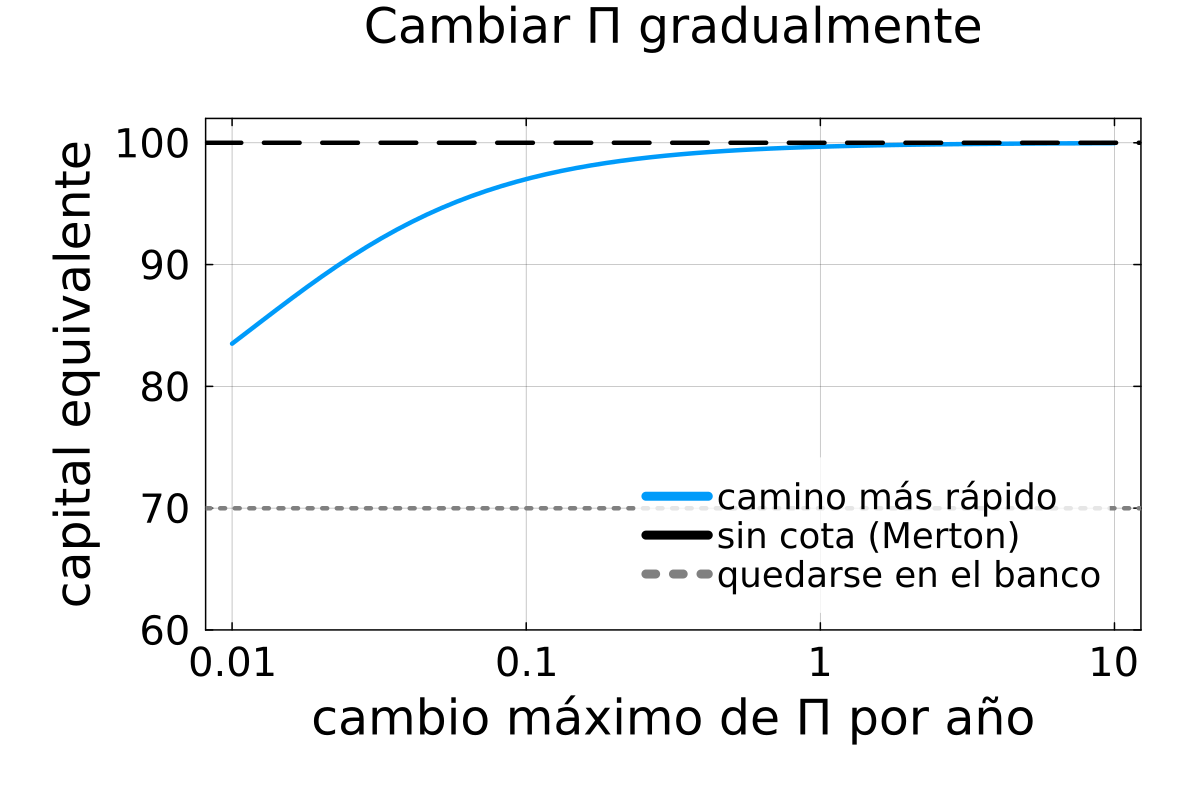

In [38]:
function valor_camino(LPi; P=par)
    t1 = Pim/LPi
    ts, Ls = L_rk4(t -> nu_p(min(LPi*t, Pim)), 0.0, t1, 1/nu; M=20_000)
    return (V=(Ls[1]^P.eta*P.x0^(1 - P.eta) - 1/P.gamma)/(1 - P.eta), t1=t1, ts=ts, Ls=Ls)
end

println("L_Pi (por año)   años hasta Pi*     V(x0)      xCE   C/X inicial")
for LPi in [0.05, 0.1, 0.25, 0.5, 1.0, 5.0]
    s = valor_camino(LPi)
    @printf("%10.2f %16.2f %12.4f %8.2f %10.4f\n", LPi, s.t1, s.V, xCE(s.V), 1/s.Ls[1])
end
@printf("%10s %16s %12.4f %8.2f %10.4f\n", "0", "nunca", Psi(par.x0), xCE(Psi(par.x0)), nu0)
@printf("%10s %16s %12.4f %8.2f %10.4f\n", "sin cota", "0", V(par.x0), 100.0, nu)

# validación por Monte-Carlo con L_Pi = 0.1: hasta T = 40 con el camino óptimo y después V(X_T) (ya es Merton)
let s = valor_camino(0.1), N = 20_000, h = 1/52, T = 40.0
    Random.seed!(3)
    K = round(Int, T/h)
    lX = fill(log(par.x0), N); Y = zeros(N)
    for k in 0:K-1
        t = k*h; p = min(0.1*t, Pim); e = t < s.t1 ? 1/interp_t(s.ts, s.Ls, t) : nu
        Y .+= (k == 0 ? h/2 : h)*exp(-par.gamma*t) .* U.(e .* exp.(lX))
        lX .+= (par.r + p*(par.mu - par.r) - e - 0.5*par.sigma^2*p^2)*h .+ par.sigma*p*sqrt(h) .* randn(N)
    end
    Y .+= (h/2)*exp(-par.gamma*T) .* U.(nu .* exp.(lX)) .+ exp(-par.gamma*T) .* V.(exp.(lX))
    @printf("\nL_Pi = 0.1: Monte-Carlo = %.4f +- %.4f   vs   V(x0) = %.4f\n", mean(Y), 1.96*std(Y)/sqrt(N), s.V)
end

let vs = exp10.(range(-2, 1, length=60))
    pc1 = plot(vs, [xCE(valor_camino(v).V) for v in vs], xscale=:log10, label="camino más rápido",
               xlabel="cambio máximo de Π por año", ylabel="capital equivalente", title="Cambiar Π gradualmente",
               legend=:bottomright, ylims=(60, 102), xticks=([0.01, 0.1, 1, 10], ["0.01", "0.1", "1", "10"]))
    hline!(pc1, [100], ls=:dash, color=:black, label="sin cota (Merton)")
    hline!(pc1, [xCE(Psi(par.x0))], ls=:dot, color=:gray, label="quedarse en el banco")
    guardar(pc1, "cambio_acotado")
end

No poder cambiar la fracción de golpe cuesta poco si la cota no es muy estricta: llegar a $\Pi^*$ en 7 meses cuesta 0.3% de capital equivalente, y en 6 años, 3%.

### 8.4 Costos de transacción

Si cada compra o venta por un monto $|a|$ cuesta $\lambda|a|$, mantener $\Pi_t=\Pi^*$ exige transar todo el tiempo y es carísimo. La teoría [DN] dice que el óptimo es una **región de no transacción**: por homotecia es un cono en el plano $(X^0,X^1)$, es decir, una **banda en la fracción** $\Pi$ alrededor de $\Pi^*$. No se transa mientras la fracción esté dentro, y se transa lo mínimo para volver al borde cuando sale. El problema es una desigualdad cuasivariacional sin solución explícita, así que comparamos estrategias de banda con Monte-Carlo:

* el consumo sale del banco con la tasa de Merton de horizonte finito, $C_t=X_t/L(T-t)$ ($T=20$, $\varepsilon=1$);
* cada semana, si la fracción sale de $[\Pi^*-\delta,\Pi^*+\delta]$, se compra o vende lo justo para volver al borde, pagando el costo: para comprar $a>0$ y quedar en la fracción $p$ se resuelve $X^1+a=p\,(X-\lambda a)$, y análogamente para vender;
* $\delta=0$ es rebalancear a $\Pi^*$ todas las semanas.

El criterio es el de horizonte finito, con $X_T$ neto del costo de liquidar, expresado en capital equivalente respecto del óptimo sin costos.

In [39]:
const T_costos, eps_costos = 20.0, 1.0
xCE_costos(J) = (((1 - par.eta)*J + D(T_costos, eps_costos))/L(T_costos, eps_costos)^par.eta)^(1/(1 - par.eta))

# estrategia de banda [Pi* - delta, Pi* + delta] con costo proporcional lam; Z: escenarios semanales
function banda(delta, lam, Z; h=1/52, P=par)
    K, N = size(Z)
    X0 = fill((1 - Pim)*P.x0, N); X1 = fill(Pim*P.x0, N); Y = zeros(N)
    lo, hi = Pim - delta, Pim + delta
    for k in 1:K
        t = (k - 1)*h
        c = (X0 .+ X1) ./ L(T_costos - t, eps_costos)                          # consumo desde el banco
        Y .+= (k == 1 ? h/2 : h)*exp(-P.gamma*t) .* U.(c)
        X0 .= X0 .* exp(P.r*h) .- c .* h
        X1 .*= exp.((P.mu - P.sigma^2/2)*h .+ P.sigma*sqrt(h) .* Z[k, :])
        for i in 1:N                                                           # rebalanceo semanal
            Xi = X0[i] + X1[i]; p = X1[i]/Xi
            if p > hi
                a = (hi*Xi - X1[i])/(1 - hi*lam)                               # vender (a < 0)
            elseif p < lo
                a = (lo*Xi - X1[i])/(1 + lo*lam)                               # comprar (a > 0)
            else
                continue
            end
            X1[i] += a; X0[i] -= a + lam*abs(a)
        end
    end
    XT = X0 .+ X1 .- lam .* X1                                                 # liquidación final
    return Y .+ (h/2)*exp(-P.gamma*T_costos) .* U.(XT ./ L(0.0, eps_costos)) .+ eps_costos*exp(-P.gamma*T_costos) .* U.(XT)
end

banda (generic function with 1 method)

In [40]:
costos = let deltas = [0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20],
             lams = [0.001, 0.0025, 0.005, 0.01, 0.02, 0.04]
    Random.seed!(4)
    Zc = randn(round(Int, 52T_costos), 4_000)
    tabla = zeros(length(lams), length(deltas)); dstar = Float64[]
    for (i, lam) in enumerate(lams)
        J = [mean(banda(d, lam, Zc)) for d in deltas]
        tabla[i, :] = xCE_costos.(J)
        j = clamp(argmax(J), 2, length(deltas) - 1)                            # parábola por los 3 puntos del máximo
        (x1, x2, x3), (y1, y2, y3) = deltas[j-1:j+1], J[j-1:j+1]
        den = (x1 - x2)*(x1 - x3)*(x2 - x3)
        A = (x3*(y2 - y1) + x2*(y1 - y3) + x1*(y3 - y2))/den
        B = (x3^2*(y1 - y2) + x2^2*(y3 - y1) + x1^2*(y2 - y3))/den
        push!(dstar, -B/(2A))
    end
    @printf("sin costos, rebalanceo semanal (delta = 0): xCE = %.2f\n\n", xCE_costos(mean(banda(0.0, 0.0, Zc))))
    println("capital equivalente según el ancho de la banda delta:")
    println("    lam  ", join([@sprintf("%7.2f", d) for d in deltas]), "   delta*")
    for (i, lam) in enumerate(lams)
        println(@sprintf("%7.4f  ", lam), join([@sprintf("%7.2f", v) for v in tabla[i, :]]), @sprintf("   %.3f", dstar[i]))
    end
    @printf("\npendiente de log(delta*) contra log(lam): %.2f  (ley asintótica de [DN]: 1/3)\n", pendiente(lams, dstar))

    lam_txt = ["0.1%", "0.25%", "0.5%", "1%", "2%", "4%"]
    pt1 = plot(xlabel="ancho de la banda δ", ylabel="capital equivalente", title="Estrategias de banda", legend=:bottomright)
    for (i, lam) in enumerate(lams)
        plot!(pt1, deltas, tabla[i, :], marker=:circle, ms=5, label="λ = $(lam_txt[i])")
    end
    guardar(pt1, "costos_bandas")
    (deltas=deltas, lams=lams, tabla=tabla, dstar=dstar)
end;

sin costos, rebalanceo semanal (delta = 0): xCE = 99.79

capital equivalente según el ancho de la banda delta:
    lam     0.00   0.01   0.02   0.03   0.04   0.05   0.06   0.08   0.10   0.12   0.15   0.20   delta*
 0.0010    99.55  99.70  99.70  99.69  99.67  99.64  99.62  99.56  99.47  99.36  99.17  98.77   0.017
 0.0025    99.18  99.56  99.60  99.59  99.57  99.55  99.53  99.46  99.38  99.27  99.08  98.68   0.024
 0.0050    98.57  99.34  99.42  99.43  99.41  99.39  99.37  99.31  99.22  99.11  98.93  98.53   0.029
 0.0100    97.36  98.88  99.06  99.10  99.10  99.08  99.06  99.00  98.91  98.80  98.62  98.22   0.034
 0.0200    94.96  97.96  98.35  98.44  98.45  98.44  98.42  98.37  98.29  98.18  97.99  97.59   0.041
 0.0400    90.21  96.11  96.89  97.08  97.13  97.14  97.13  97.08  97.00  96.89  96.71  96.30   0.048

pendiente de log(delta*) contra log(lam): 0.27  (ley asintótica de [DN]: 1/3)


* **Rebalancear a $\Pi^*$ todas las semanas es caro:** con un costo de 1% equivale a tener 97.4 de capital, y con 4%, 90.2.
* **Una banda angosta recupera casi todo:** con $\lambda=1\%$ y una banda de $\pm0.03$ se llega a 99.1, cerca del óptimo sin costos con rebalanceo semanal (99.8).
* El ancho óptimo crece con el costo, con pendiente logarítmica 0.27, cercana al exponente 1/3 de [DN] (que es para rebalanceo continuo y horizonte infinito; la estimación es ruidosa porque las curvas son planas cerca del máximo).

**Conclusiones de la Sección 8.**
1. **Varios activos:** $\Pi^*=\frac1\eta\Sigma^{-1}(\mu-r\mathbf 1)$; todos compran el mismo fondo, y diversificar vale un 17%.
2. **$\mu(t)$, $\sigma(t)$ conocidos:** la fórmula de Merton se aplica instante a instante; conocer el ciclo vale mucho, pero no se puede estimar.
3. **Cambios acotados de $\Pi$:** por homotecia el problema se reduce a una EDO y conviene llegar lo antes posible a $\Pi^*$.
4. **Costos de transacción:** una banda de no transacción angosta recupera casi todo, y su ancho crece aproximadamente como $\lambda^{1/3}$.

## 9. Conclusiones

1. **Controlabilidad.** El sistema no es controlable en el sentido clásico, pero es exactamente controlable con restricciones: el conjunto alcanzable es $\{\xi\ge0:\mathbb E[H_T\xi]\le x\}$.
2. **Monte-Carlo.** Con estrategias proporcionales la simulación es exacta y, con el valor de continuación exacto, el estimador solo tiene el sesgo de la cuadratura; confirma que Merton es óptimo entre las estrategias simuladas.
3. **Parámetros.** El mayor obstáculo práctico es estimar $\mu$, no resolver la HJB: su error solo baja con los años observados, y usar $\hat\mu$ en la fórmula cuesta mucho.
4. **HJB y existencia.** La HJB numérica reproduce la solución de Merton sin usarla; la existencia es un teorema si $\nu>0$, y con $\eta\le\eta_{\min}$ el problema está mal planteado.
5. **Restricciones y extensiones.** Con homotecia y cotas fijas sobre $\Pi$ la fracción es la de Merton (o su proyección) y solo cambia el consumo. Con un piso (que rompe la homotecia), costos de transacción o cambios acotados de $\Pi$ (controles dinámicos) no hay fórmula cerrada y queda lo numérico.

### Números del póster

La celda siguiente reúne los valores que aparecen en el póster, calculados en este notebook.

In [41]:
println("Problema:        Pi* = ", round(Pim, digits=3), ",  nu = ", round(nu, digits=4), ",  V(x0) = ", round(V(par.x0), digits=3))
println("Solo banco:      xCE = ", round(xCE(Psi(par.x0)), digits=1))
println("Kalman:          años para que el error de mu sea menor que la prima: ", round((1.96*par.sigma/(par.mu - par.r))^2, digits=1))
println("Costo de estimar (años de datos ", kalman_costo.Tobs, "):")
println("                 mediana xCE  = ", round.(kalman_costo.mediana, digits=1))
println("                 P(J = -Inf)  = ", round.(kalman_costo.P_inf, digits=2))
println("Existencia:      eta_min = ", round(eta_min, digits=3))
println("Fracción acotada: xCE con Pi <= 0.5: ", round(xCE(Jexacto(0.5, nu_p(0.5))), digits=1),
        ";  Pi <= 0.25 o Pi >= 1: ", round(xCE(Jexacto(0.25, nu_p(0.25))), digits=1))
println("Reglas con historia (Monte-Carlo): ", Dict(k => round(v, digits=1) for (k, v) in reglas_historia))
println("Parada exponencial (vida esperada 30 años): C/X = ", round(nu + (1/30)/par.eta, digits=3))
println("Piso de liquidación: xCE = ", [round(xCE_piso(sols_piso[xl]), digits=1) for xl in pisos], " para pisos ", Int.(pisos))
println("Varios activos:  xCE = ", round(xCE(Vde(par.x0, th2_n)), digits=1))
let j = findfirst(==(0.01), costos.lams)
    println("Costos (lam = 1%): delta = 0 -> xCE = ", round(costos.tabla[j, 1], digits=1),
            ";  delta = 0.03 -> xCE = ", round(costos.tabla[j, 4], digits=1),
            ";  pendiente de delta* = ", round(pendiente(costos.lams, costos.dstar), digits=2))
end

Problema:        Pi* = 0.625,  nu = 0.0478,  V(x0) = 15.626
Solo banco:      xCE = 70.0
Kalman:          años para que el error de mu sea menor que la prima: 61.5
Costo de estimar (años de datos [5, 10, 20, 40]):
                 mediana xCE  = [27.3, 71.5, 85.6, 92.6]
                 P(J = -Inf)  = [0.43, 0.24, 0.12, 0.03]
Existencia:      eta_min = 0.477
Fracción acotada: xCE con Pi <= 0.5: 98.7;  Pi <= 0.25 o Pi >= 1: 88.6
Reglas con historia (Monte-Carlo): Dict("Merton aprendiendo mu" => 81.8, "Caída desde el máximo" => 97.9, "Ingenua: Pi = 1, C = 0.04X" => 89.6, "Merton (markoviana, óptima)" => 99.9, "Media móvil de 1 año" => 84.2)
Parada exponencial (vida esperada 30 años): C/X = 0.064
Piso de liquidación: xCE = [99.1, 94.8, 85.7] para pisos [20, 50, 80]
Varios activos:  xCE = 116.8
Costos (lam = 1%): delta = 0 -> xCE = 97.4;  delta = 0.03 -> xCE = 99.1;  pendiente de delta* = 0.27
